In [1]:
# [01] คำอธิบายโน้ตบุ๊ค อภิธานศัพท์ และ import ทั้งหมด
# ==================================================
# ทำอะไร: โน้ตบุ๊คนี้ฝึกโมเดล Decision Tree (ต้นไม้ตัดสินใจ) ทายราคารถมือสองจากไฟล์ merge_50min_clean.csv
#         ใช้ไฟล์ที่ทำความสะอาดนอกโน้ตบุ๊คด้วย data/main/clean_merged_min50.py (บันทึก: data/main/merge_50min_clean_steps.md); เซลล์ตรวจคุณภาพ [05]-[11] ตรวจอย่างเดียว ไม่ลบแถว
#         บนเครื่องของเราเองใน VS Code แล้วปรับค่าตั้งของโมเดล (hyperparameter) ด้วย cross-validation
#         และพิมพ์ผลบนชุด train / validation / test โดยไม่เขียนไฟล์ใดๆ ลงเครื่อง
#         เซลล์นี้เป็นทั้งคำอธิบายภาพรวมและที่รวม import ทั้งหมด (เซลล์อื่นไม่ import เพิ่ม)
#
# วิธีรัน:
#   1) ปิดโปรแกรมที่กินหน่วยความจำมากก่อน (เช่น แท็บเบราว์เซอร์จำนวนมาก) เพราะช่วงค้นหา
#      ใช้หลาย process พร้อมกัน และแต่ละ process ถือสำเนาข้อมูลของตัวเอง
#   2) เปิดไฟล์นี้ใน VS Code แล้วกด "Select Kernel" มุมขวาบน เลือก Python ของ research/.venv
#      (D:/AI_Workspace/car-project/research/.venv/Scripts/python.exe)
#   3) กด "Run All" แล้วรอจนเซลล์สุดท้าย [47] พิมพ์ผลสรุป
#      เวลาที่คาดไว้ประมาณ 5-10 นาทีบนเครื่องนี้ (ประมาณจากการรันทดลองเมื่อ 2026-10-23
#      ไม่ใช่การวัดซ้ำทุกครั้ง) ส่วนที่นานที่สุดคือการค้นหา ccp_alpha ร่วมกับ grid ในเซลล์ [25]
#      และการรัน GridSearchCV ในเซลล์ [31] ช่วงนั้นเซลล์จะเงียบเป็นเรื่องปกติ
#   4) ถ้าเซลล์ไหน error ให้หยุดอ่านข้อความ error ก่อน อย่ากดรันต่อ เพราะเซลล์ถัดไปใช้ผลของเซลล์ก่อนหน้า
#
# แผนที่ของโน้ตบุ๊ค (เลขในวงเล็บคือเลขเซลล์):
#   - ตั้งค่าและอ่านข้อมูล             [01]-[04]
#   - ตรวจคุณภาพข้อมูล                 [05]-[11]
#   - เตรียมข้อมูลและแบ่งชุด           [12]-[14]
#   - ความสัมพันธ์ระหว่างตัวแปรทีละคู่  [15]-[17]
#   - โมเดล                            [18]-[21]
#   - เลือก ccp_alpha ร่วมกับ grid      [22]-[33]
#   - ตรวจขอบ grid                     [34]
#   - วัดผล                            [35]-[37]
#   - การตรวจเพิ่มเติม                 [38]-[43]
#   - สรุปการตรวจ overfit              [44]
#   - ความสำคัญของตัวแปร              [45]-[47]
#
# ต่างจากโน้ตบุ๊คต้นฉบับ (เหตุผลอยู่ในคอมเมนต์ของแต่ละเซลล์):
#   - รันบนเครื่องใน VS Code เท่านั้น ไม่เชื่อม Google Drive / Colab และไม่เขียนไฟล์ใดๆ        [02]
#   - ไม่ตรวจลายนิ้วมือไฟล์ (hash) ของข้อมูล (ผู้ใช้สั่งตัดออกเมื่อ 2026-10-27)              [04]
#   - ไม่เปลี่ยนชื่อคอลัมน์                                                          [12]
#   - ไม่มีขั้นคัดเลือกตัวแปร (feature selection)                                   [18]
#   - ขยาย grid ของ max_depth และ min_samples_leaf                                [21]
#   - เลือก ccp_alpha ตามวิธีมาตรฐานของ CART คือลองทุก alpha บน pruning path
#     ของทุกคู่ (max_depth, min_samples_leaf) ด้วย 5-fold CV แล้วเลือกชุดที่ CV MAE เฉลี่ยต่ำสุด
#     (ไม่ใช้กฎเลือกต้นไม้เล็กในช่วงหนึ่ง SE และไม่จำกัดจำนวน alpha แบบเดิม)          [22]-[33]
#   - เพิ่มการตรวจที่ต้นฉบับไม่มี:
#       คุณภาพข้อมูล [05]-[11], ความสัมพันธ์ทีละคู่ [15]-[17], ขอบ grid [34],
#       ตาราง 10 อันดับแรก [38], learning curve [39]-[40], CV train เทียบ validation [41],
#       validation curve [42]-[43], สรุปการตรวจ overfit [44]
#
# โน้ตบุ๊คนี้คือ Decision Tree ฉบับที่ปรับให้รันบนเครื่องเอง ใช้โครงสร้างเซลล์เดียวกับโน้ตบุ๊ค
# Random Forest และ XGBoost ที่รันบนเครื่อง เซลล์ [01]-[19] ของทั้งสามเล่มมีเลขและงานเดียวกัน
# จะเทียบทีละเซลล์ได้ ส่วนเรื่องที่ DT ต่างจากสองโมเดลนั้น:
#   - DT มีต้นไม้ต้นเดียว ปรับความซับซ้อนด้วย max_depth, min_samples_leaf และ ccp_alpha
#     (การตัดกิ่ง) ซึ่ง Random Forest และ XGBoost ไม่มี                                [22]-[33]
#   - DT นับใบด้วยการฝึกต้นไม้ซ้ำบน train ทั้งชุด (ไม่ได้นับระหว่าง cross-validation)       [29]
#
# อภิธานศัพท์ (ศัพท์ที่จะเจอตลอดโน้ตบุ๊ค):
#   - train / validation / test: ข้อมูลสามชุด
#       train       ใช้สอนโมเดล (ให้โมเดลดูคำตอบแล้วเรียนรู้)
#       validation  กันไว้ตรวจผลอีกชุดที่โมเดลไม่เคยเห็น (ในโน้ตบุ๊คนี้การเลือกพารามิเตอร์
#                   ใช้ cross-validation บน train ส่วน validation ใช้รายงานผลคู่กับ test)
#       test        เก็บไว้ตัดสินผลสุดท้ายครั้งเดียว ไม่เอามาปรับโมเดล
#   - fold และ cross-validation (CV): แบ่งชุด train เป็นหลายส่วน (fold)
#       แล้วผลัดกันเอาทีละ fold ไปเป็นชุดทดสอบ ส่วนที่เหลือใช้สอน
#       ได้คะแนนหลายรอบมาเฉลี่ย เชื่อถือกว่าการลองแค่รอบเดียว
#   - feature: คอลัมน์ที่โมเดลใช้ทายราคา เช่น ยี่ห้อ รุ่น เลขไมล์ อายุรถ
#   - hyperparameter: ค่าที่เราตั้งเองก่อนฝึก เช่น ความลึกของต้นไม้
#       (ต่างจากค่าที่โมเดลเรียนรู้เอง)
#   - ต้นไม้ตัดสินใจ (decision tree): โมเดลที่ถามคำถามใช่/ไม่ใช่ต่อกันเป็นกิ่ง เช่น "อายุรถ <= 5 ปี?"
#       ปลายกิ่งเรียกว่าใบ (leaf) แต่ละใบให้คำตอบเป็นราคาเฉลี่ยของรถในใบนั้น
#       ใบยิ่งมาก ต้นไม้ยิ่งละเอียดและยิ่งจำข้อมูลฝึกได้มาก
#   - pruning และ ccp_alpha: pruning คือการตัดกิ่งที่ไม่คุ้มออกหลังต้นไม้โตเสร็จ
#       ccp_alpha คือ "ค่าปรับต่อหนึ่งใบ" ยิ่งมากยิ่งตัดมาก ต้นไม้ยิ่งเล็ก (0 = ไม่ตัดเลย)
#   - pruning path (เส้นทางการตัดกิ่ง): ลำดับค่า ccp_alpha ที่ต้นไม้เต็มที่ถูกตัดเพิ่มทีละขั้น
#       ได้จาก cost_complexity_pruning_path ระหว่างค่าที่ติดกันต้นไม้ยังเหมือนเดิม
#       เราจึงใช้ค่ากลางแบบเรขาคณิต (geometric midpoint) ของ alpha ที่ติดกันเป็นตัวแทน
#       เพราะมันไม่ทับกับจุดตัดพอดี (ที่ alpha เท่ากับค่าใน path การเทียบ <= กำกวม)
#   - การเลือก ccp_alpha ด้วย CV: ทุกคู่ (max_depth, min_samples_leaf) มี pruning path ของตัวเอง
#       เอาทุก alpha ของคู่นั้นมาวัดด้วย 5-fold CV แล้วเลือก (คู่, alpha) ที่ CV MAE ต่ำสุด
#       เป็นวิธีมาตรฐานของ CART (Breiman, Friedman, Olshen & Stone, 1984)
#       และเป็นวิธีเดียวกับที่ R rpart ทำ (หนึ่งต้นต่อหนึ่ง fold)
#   - MAE (Mean Absolute Error): ค่าเฉลี่ยของ "ทายผิดไปกี่บาท" ไม่สนว่าสูงหรือต่ำไป
#       ยิ่งต่ำยิ่งดี หน่วยเป็นบาท
#   - RMSE (Root Mean Squared Error): คล้าย MAE แต่ลงโทษความผิดพลาดก้อนใหญ่หนักกว่า
#       หน่วยเป็นบาท ยิ่งต่ำยิ่งดี
#   - MAPE (Mean Absolute Percentage Error): ทายผิดเฉลี่ยกี่เปอร์เซ็นต์ของราคาจริง
#       ยิ่งต่ำยิ่งดี
#   - R² : สัดส่วนความผันผวนของราคาที่โมเดลอธิบายได้ 1 = ทายตรงทุกคัน
#       0 = ไม่ดีกว่าการทายราคาเฉลี่ยทุกคัน (ค่าติดลบได้ถ้าแย่กว่านั้น)
#   - overfit: โมเดลจำข้อมูล train ได้ดีเกินไป จนทายข้อมูลใหม่ไม่ดี
#       (คะแนน train ดีมาก แต่ validation / test แย่กว่ามาก)
#   - underfit: โมเดลง่ายเกินไป จับรูปแบบในข้อมูลไม่ได้ ทายแย่ทั้ง train และข้อมูลใหม่
# ==================================================
import heapq
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from IPython.display import display
from joblib import Parallel, delayed, parallel_backend
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error,
                             mean_squared_error, r2_score)
from sklearn.model_selection import (GridSearchCV, KFold, ParameterGrid, train_test_split,
                                     cross_val_score, cross_validate, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor

print("=== [01] คำอธิบายโน้ตบุ๊ค อภิธานศัพท์ และ import ทั้งหมด ===")
print("import ครบแล้ว")
from sklearn.compose import TransformedTargetRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_val_score


=== [01] คำอธิบายโน้ตบุ๊ค อภิธานศัพท์ และ import ทั้งหมด ===
import ครบแล้ว


In [2]:
# [02] กำหนดที่อยู่ไฟล์ข้อมูล
# ==================================================
# ทำอะไร: กำหนดตัวแปร DATA_PATH ให้ชี้ไปที่ไฟล์ merge_50min_clean.csv บนเครื่องนี้
# ทำไม: โน้ตบุ๊คนี้รันบนเครื่องใน VS Code เท่านั้น ไม่ได้รันใน Google Colab
#       จึงไม่ต้องเชื่อม Google Drive และไม่ต้องตรวจว่ารันที่ไหน เซลล์ถัดไปอ่านไฟล์จาก DATA_PATH
# ผลที่ควรเห็น: บรรทัดเดียวบอกที่อยู่ไฟล์ DATA_PATH
# ข้อควรระวัง: ถ้าย้ายไฟล์ข้อมูลไปที่อื่น ให้แก้ที่อยู่ในเซลล์นี้ที่เดียว
#       ใช้เครื่องหมาย / คั่นโฟลเดอร์ได้แม้บน Windows (Python เข้าใจทั้ง / และ \)
# ==================================================
print("=== [02] กำหนดที่อยู่ไฟล์ข้อมูล ===")

DATA_PATH = "D:/AI_Workspace/car-project/data/main/merge_50min_clean.csv"

print(f"DATA_PATH : {DATA_PATH}")

=== [02] กำหนดที่อยู่ไฟล์ข้อมูล ===
DATA_PATH : D:/AI_Workspace/car-project/data/main/merge_50min_clean.csv


In [3]:
# [03] ค่าคงที่ของการทดลอง
# ==================================================
# ทำอะไร: รวมค่าที่ตั้งเองทั้งหมดของการทดลองไว้ที่เดียว (เลขสุ่ม จำนวน fold รายชื่อคอลัมน์
#         สัดส่วนการแบ่งข้อมูล จำนวนงานค้นหา ฯลฯ) เซลล์อื่นอ่านค่าจากที่นี่
# ทำไม: อยากเปลี่ยนค่าไหนก็แก้ที่เดียว และไม่มี "เลขมายากล" กระจายอยู่ในโค้ด
#       ใช้เลขสุ่ม SEED เดิมทุกที่ ผลจึงทำซ้ำได้ รันกี่รอบก็ได้ตัวเลขเดิม
#   - SEARCH_JOBS = 8 และ MODEL_THREADS = 1: DecisionTreeRegressor ฝึกต้นไม้ต้นเดียวด้วย thread เดียว
#     (ไม่มีตัวเลือก n_jobs ในโมเดล) MODEL_THREADS จึงไม่ถูกส่งให้โมเดลโดยตรง แต่ใช้จำกัดจำนวน thread
#     ของไลบรารีคำนวณ (เช่น numpy) ภายในแต่ละ process ของ grid search ในเซลล์ [31] ให้ไม่แย่ง core กันเอง
#     ความเร็วจึงมาจากการให้ grid search ฝึกหลายต้นพร้อมกัน (SEARCH_JOBS ต้น) เครื่องนี้มี 22 logical CPU
#     เลือก SEARCH_JOBS x MODEL_THREADS = 8 ซึ่งไม่เกิน 20 และเหลือ core ให้ระบบ
#     เหตุผลที่ไม่ใช้ 20: แต่ละงานเป็น process แยก ถือสำเนาข้อมูลและต้นไม้ของตัวเอง หน่วยความจำว่างของ
#     เครื่องนี้มีจำกัด 8 งานยังเร็วพอเพราะต้นไม้ต้นหนึ่งฝึกเสร็จเร็ว และหน่วยความจำรวมยังเล็ก
#     จำนวนงานไม่เปลี่ยนผลลัพธ์ เพราะต้นไม้ที่ได้ขึ้นกับข้อมูลกับ SEED เท่านั้น
#   - แกนกราฟที่ล็อกไว้ (MAE_AXIS, R2_AXIS, ROWS_AXIS ฯลฯ) ประกาศไว้ท้ายเซลล์นี้ เพื่อให้กราฟของ DT / RF / XGB เทียบกันที่ความสูงเดียวกัน
# ผลที่ควรเห็น: สรุปค่าตั้งหลักๆ เรียงเป็นบรรทัด
# ข้อควรระวัง:
#   - ccp_alpha ไม่มีค่าคงที่ในเซลล์นี้ เพราะรายการ alpha สร้างจาก pruning path ของแต่ละคู่
#     (max_depth, min_samples_leaf) ในเซลล์ [23] แล้ววัดด้วย 5-fold CV ในเซลล์ [25]
#   - ถ้าเครื่องที่รันมี CPU น้อยกว่า 10 logical CPU ให้ลด SEARCH_JOBS ลงให้ไม่เกินจำนวน logical CPU ลบ 2
#     ผลลัพธ์จะเหมือนเดิมแต่ใช้เวลานานขึ้น
#   - CURRENT_YEAR คือปีที่เก็บข้อมูล (ไม่ใช่ปีที่รันโน้ตบุ๊ค) ใช้คำนวณอายุรถ
#     ถ้าเปลี่ยนเป็นปีปัจจุบัน ตัวเลขอายุและผลของโมเดลจะเปลี่ยนไป
# ==================================================
print("=== [03] ค่าคงที่ของการทดลอง ===")

SEED = 99  # เลขสุ่มกลาง ใช้ทุกที่ที่มีการสุ่ม เพื่อให้ผลซ้ำได้
N_FOLDS = 5  # จำนวน fold ของ cross-validation
NUM_COLS = ["engine", "mileage", "car_age"]  # feature ตัวเลข
CAT_COLS = ["brand", "model", "car_type", "fuel", "gear"]  # feature ประเภทกลุ่ม
MODEL_NAME = "DT"  # ชื่อโมเดล ใช้ในผลลัพธ์ JSON
VERSION = "v5"  # เวอร์ชันของวิธีฝึก ใช้ในผลลัพธ์ JSON
CURRENT_YEAR = 2026  # ปีที่เก็บข้อมูล ใช้คำนวณ car_age = CURRENT_YEAR - year
TRAIN_SIZE, VAL_SIZE, TEST_SIZE = 0.8, 0.1, 0.1  # สัดส่วนแบ่ง train / validation / test
LC_FRACTIONS = np.arange(1, 11) / 10  # สัดส่วน train ที่ใช้วาด learning curve: 10% ถึง 100%
LC_REPEATS = 5  # จำนวนรอบสุ่มซ้ำของ learning curve ต่อหนึ่งสัดส่วน
SEARCH_JOBS = 8  # จำนวนงานค้นหาที่รันพร้อมกันใน GridSearchCV (SEARCH_JOBS x MODEL_THREADS ไม่เกิน 20)
MODEL_THREADS = 1  # จำนวน thread ของไลบรารีคำนวณภายในแต่ละงาน (DT ฝึกด้วย thread เดียวอยู่แล้ว)

# --- แกนกราฟที่ล็อกไว้ (ค่าเหมือนกันทั้ง 3 โน้ตบุ๊ค DT / RF / XGB ต้องแก้ให้ตรงกันทุกไฟล์) ---
# ทำไมต้องล็อก: ให้กราฟของ DT / RF / XGB เทียบกันด้วยตาได้ที่ความสูงเดียวกัน
#   ถ้าปล่อยให้ matplotlib เลือกช่วงเอง ค่าเดียวกันจะไปอยู่คนละความสูงในแต่ละโน้ตบุ๊ค
# เลือกช่วงอย่างไร: ดูค่าต่ำสุด/สูงสุดที่กราฟวาด (รวมแถบ ±1 sd) จากผลที่บันทึกไว้ของทั้ง 3 โน้ตบุ๊ค
#   แล้วเผื่อขอบเล็กน้อยและปัดเป็นเลขกลม ถ้าข้อมูลเปลี่ยนจนค่าหลุดช่วง เซลล์กราฟจะพิมพ์ WARN
MAE_AXIS = (20000, 90000)  # แกน MAE (บาท) ของ learning curve และ validation curve ครอบทุกโมเดล
R2_AXIS = (0.8, 1.0)  # แกน R² ของ learning curve
ROWS_AXIS = (0, 40000)  # แกน x ของ learning curve: จำนวนแถวฝึก (ทุกโมเดลฝึกบนข้อมูลชุดเดียวกัน)
FOLD_AXIS = (-0.5, 4.5)  # แกน x ของกราฟแท่งราย fold: ตำแหน่ง 0..4 (ต้องสัมพันธ์กับ N_FOLDS = 5)
MAE_BAR_AXIS = (0, 70000)  # แกน y ของกราฟแท่ง MAE ต่อ fold: แท่งต้องเริ่มที่ 0 จึงแยกจาก MAE_AXIS
MAE_CCP_AXIS = (50000, 130000)  # แกน y ของกราฟ ccp_alpha (เฉพาะ DT): ฝั่ง alpha สูงเกิน MAE_AXIS จึงใช้ช่วงซูมแยก
MAE_OOB_AXIS = (52000, 54000)  # แกน y ของกราฟ OOB (เฉพาะ RF): เส้นแบนมาก ถ้าใช้ MAE_AXIS เส้นจะเป็นขีดตรง จึงใช้ช่วงซูมแยก
MAE_ROUND_AXIS = (30000, 70000)  # แกน y ของกราฟรายรอบ (เฉพาะ XGB): ตัดรอบแรกๆ ที่ MAE สูงมากทิ้งเหมือนเดิม จึงใช้ช่วงซูมแยก

print(f"SEED                   : {SEED}")
print(f"จำนวน fold             : {N_FOLDS}")
print(f"ตัวแปรตัวเลข           : {NUM_COLS}")
print(f"ตัวแปรประเภทกลุ่ม      : {CAT_COLS}")
print(f"สัดส่วน train/val/test : {TRAIN_SIZE} / {VAL_SIZE} / {TEST_SIZE}")
print(f"ปีที่เก็บข้อมูล        : {CURRENT_YEAR}")
print(f"โมเดล / เวอร์ชัน       : {MODEL_NAME} / {VERSION}")
print(f"งานค้นหา x thread      : {SEARCH_JOBS} x {MODEL_THREADS}")
RUN_ID = "DT_merge50minC"
DATASET = "merge_50min_clean.csv"
VARIANT = "base"
PERM_AXIS = (0, 150000)
SHARE_AXIS = (0, 1.0)


=== [03] ค่าคงที่ของการทดลอง ===
SEED                   : 99
จำนวน fold             : 5
ตัวแปรตัวเลข           : ['engine', 'mileage', 'car_age']
ตัวแปรประเภทกลุ่ม      : ['brand', 'model', 'car_type', 'fuel', 'gear']
สัดส่วน train/val/test : 0.8 / 0.1 / 0.1
ปีที่เก็บข้อมูล        : 2026
โมเดล / เวอร์ชัน       : DT / v5
งานค้นหา x thread      : 8 x 1


In [4]:
# [04] อ่าน CSV
# ==================================================
# ทำอะไร: อ่านไฟล์ข้อมูลเป็นตาราง raw_df
# ทำไม:
#   - ไม่ตรวจ sha256 ของไฟล์แล้ว (ผู้ใช้สั่งตัดออกเมื่อ 2026-10-27) เพราะข้อมูลถูกทำความสะอาดต่อเนื่อง
#     ลายนิ้วมือจึงเปลี่ยนทุกครั้งที่ไฟล์เปลี่ยน และการตรวจทำให้รันโน้ตบุ๊คไม่ได้
#   - เก็บตารางต้นทางไว้ใน raw_df และไม่แก้ไข เซลล์ [12] จะทำสำเนาไปเตรียมข้อมูลต่อ
#     จึงรันซ้ำได้โดยไม่ต้องอ่านไฟล์ใหม่
#   - encoding="utf-8-sig" รองรับ BOM (ตัวอักษรพิเศษต้นไฟล์ที่ Excel ชอบใส่)
# ผลที่ควรเห็น: จำนวนแถวและคอลัมน์ และตัวอย่าง 5 แถวแรก
# ข้อควรระวัง: เมื่อไม่มีการตรวจ ต้องแน่ใจเองว่า DATA_PATH ชี้ไปที่ข้อมูลชุดที่ตั้งใจใช้
#       ผลที่บันทึกไว้ในโน้ตบุ๊คอาจมาจากข้อมูลคนละชุด (รุ่นเก่า 47,001 แถว) จนกว่าจะรันใหม่
# ==================================================
print("=== [04] อ่าน CSV ===")

raw_df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

print(f"จำนวนแถว     : {raw_df.shape[0]:,}")
print(f"จำนวนคอลัมน์ : {raw_df.shape[1]:,}")
print("ตัวอย่าง 5 แถวแรก:")
display(raw_df.head())


=== [04] อ่าน CSV ===


จำนวนแถว     : 46,074
จำนวนคอลัมน์ : 10
ตัวอย่าง 5 แถวแรก:


=== [05] ตรวจคุณภาพ 1: ค่าว่าง ===


ตารางนี้บอกว่าแต่ละคอลัมน์มีค่าว่างกี่ช่อง และคิดเป็นกี่เปอร์เซ็นต์ของทุกแถว


,missing_count,missing_percent
brand,0,0.00
model,0,0.00
car_type,0,0.00
fuel,0,0.00
gear,0,0.00
color,0,0.00
engine,0,0.00
year,0,0.00
mileage,0,0.00
price,0,0.00


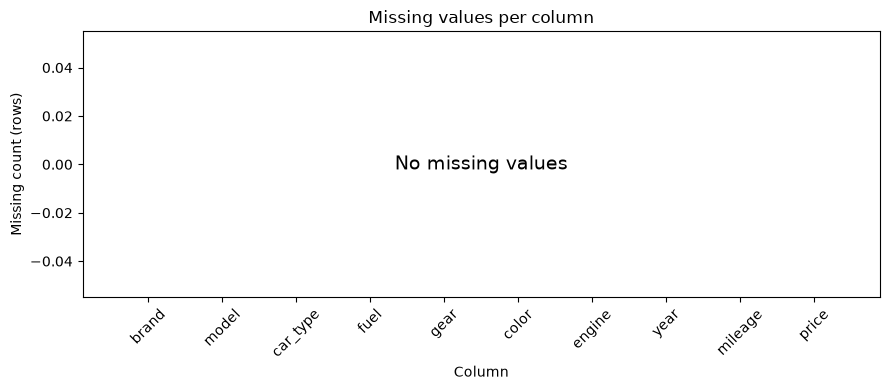

ไม่พบค่าว่าง


In [5]:
# [05] ตรวจคุณภาพ 1: ค่าว่าง
# ==================================================
# ทำอะไร: นับจำนวนและเปอร์เซ็นต์ของ "ค่าว่าง" (missing value, ช่องที่ไม่มีข้อมูล) ในทุกคอลัมน์ของ raw_df
#         แล้ววาดแท่งกราฟจำนวนค่าว่างต่อคอลัมน์
# ทำไม: ส่วนนี้ ([05]–[11]) คือการตรวจคุณภาพข้อมูลก่อนสร้างโมเดล เพราะหลัก "garbage in, garbage out"
#       คือถ้าข้อมูลเข้าไม่ดี (ว่าง ซ้ำ เป็นไปไม่ได้ กระจายแปลก) ต่อให้โมเดลดีแค่ไหน ผลลัพธ์ก็ไม่น่าเชื่อถือ
#       ค่าว่างต้องรู้ก่อนเสมอ เพราะถ้ามีอยู่ ต้องตัดสินใจว่าจะเติม ลบ หรือปล่อยไว้
#       ข้อตกลงของทั้งส่วนนี้:
#       1) ทุกเซลล์ตรวจบน raw_df ทั้งไฟล์ (ก่อนเตรียมข้อมูล) ซึ่งปลอดภัย เพราะไม่มีผลการตรวจใดถูกนำไปเลือก
#          อะไรให้โมเดลเลย (ไม่มี data leakage คือข้อมูลชุดทดสอบไม่รั่วไปมีอิทธิพลต่อการเลือกโมเดล)
#       2) ส่วนนี้ "รายงานอย่างเดียว" ไม่แก้ raw_df และไม่สร้างตัวแปรที่เซลล์อื่นต้องใช้
#          ถ้าพบปัญหา ผู้ใช้เป็นคนตัดสินใจทีหลังว่าจะทำอย่างไร ข้อมูลจึงไม่ถูกเปลี่ยนที่นี่
#          และผลของโมเดลไม่เปลี่ยน
#       3) ข้อสรุปท้ายแต่ละเซลล์ถูกคำนวณโดยโค้ด ไม่ได้พิมพ์ตายตัว
# ผลที่ควรเห็น: ตารางหนึ่งแถวต่อคอลัมน์ (10 แถว) บอกจำนวนค่าว่างและเปอร์เซ็นต์ กราฟแท่งจำนวนค่าว่างต่อคอลัมน์
#       ถ้าทุกแท่งเป็นศูนย์ บนกราฟจะมีข้อความ "No missing values" และบรรทัดสุดท้ายบอกว่าไม่พบค่าว่าง
#       ถ้ามีแท่งสูง แสดงว่าคอลัมน์นั้นมีข้อมูลหาย ควรหาสาเหตุก่อนไปต่อ
# ==================================================
print("=== [05] ตรวจคุณภาพ 1: ค่าว่าง ===")

missing_table = pd.DataFrame({
    "missing_count": raw_df.isna().sum(),
    "missing_percent": raw_df.isna().mean() * 100,
})

print("ตารางนี้บอกว่าแต่ละคอลัมน์มีค่าว่างกี่ช่อง และคิดเป็นกี่เปอร์เซ็นต์ของทุกแถว")
display(missing_table.style.format({
    "missing_count": "{:,.0f}",
    "missing_percent": "{:.2f}",
}))

total_missing = int(missing_table["missing_count"].sum())

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(missing_table.index, missing_table["missing_count"])
ax.set_title("Missing values per column")
ax.set_xlabel("Column")
ax.set_ylabel("Missing count (rows)")
ax.tick_params(axis="x", rotation=45)
if total_missing == 0:
    ax.text(0.5, 0.5, "No missing values", transform=ax.transAxes,
            ha="center", va="center", fontsize=14)
plt.tight_layout()
plt.show()

if total_missing == 0:
    print("ไม่พบค่าว่าง")
else:
    columns_with_missing = int((missing_table["missing_count"] > 0).sum())
    print(f"พบค่าว่างรวม {total_missing:,} ค่า ใน {columns_with_missing} คอลัมน์")

=== [06] ตรวจคุณภาพ 2: แถวซ้ำ ===


ตารางนี้บอกจำนวนแถวที่ซ้ำกับแถวก่อนหน้า ตามแต่ละนิยามของคำว่า 'ซ้ำ'


,duplicate_rows,percent_of_rows
all columns,0,0.00
all except price,"9,066",19.68
all except color,"1,238",2.69


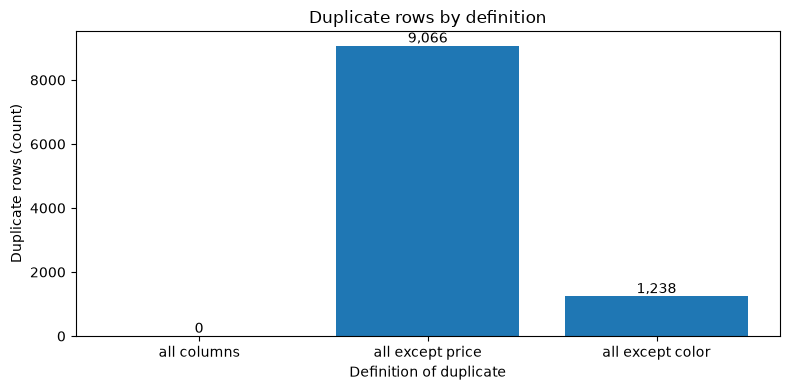

ไม่พบแถวที่ซ้ำกันทุกคอลัมน์
แถวที่ต่างกันแค่ price (ธงเตือน)   : 9,066 แถว
แถวที่ต่างกันแค่ color (รถคนละคัน) : 1,238 แถว


In [6]:
# [06] ตรวจคุณภาพ 2: แถวซ้ำ
# ==================================================
# ทำอะไร: นับแถวที่ "ซ้ำกับแถวก่อนหน้า" (ตัวสำเนาส่วนเกิน ไม่นับแถวแรกที่เจอ) ตาม 3 นิยาม
#         1) เหมือนกันทุกคอลัมน์
#         2) เหมือนกันทุกคอลัมน์ ยกเว้น price
#         3) เหมือนกันทุกคอลัมน์ ยกเว้น color
# ทำไม: กฎของโปรเจกต์นี้คือ "แถวที่ต่างกันในคอลัมน์ใดก็ตามที่ไม่ใช่ price ถือว่าเป็นรถคนละคัน"
#       ดังนั้น
#       - นิยาม 1 คือแถวซ้ำจริง ๆ (อาจเป็นข้อมูลที่ถูกบันทึกซ้ำ)
#       - นิยาม 2 คือแถวที่ทุกอย่างเหมือนกันหมดแต่ราคาต่างกัน ตามกฎอาจเป็นรถคันเดียวที่ถูกประกาศขายสองราคา
#         จึงเป็นธงเตือนคุณภาพ (quality flag) ไม่ใช่ข้อผิดพลาดที่ยืนยันแล้ว
#       - นิยาม 3 คือแถวที่ต่างกันแค่สี ตามกฎเป็นรถคนละคัน (สีต่างกัน) จึงไม่ใช่ข้อมูลซ้ำ
#         ข้อนี้เชื่อมกับหมายเหตุในเซลล์ [13] ที่อธิบายเรื่องการแบ่งข้อมูล
#       แถวซ้ำสำคัญเพราะถ้าแถวเดียวกันอยู่ทั้งชุดเทรนและชุดทดสอบ คะแนนทดสอบจะดีเกินจริง
#       เซลล์นี้รายงานอย่างเดียว ไม่ลบแถวใดเลย
# ผลที่ควรเห็น: ตารางสามแถว (นิยามละหนึ่งแถว) บอกจำนวนแถวซ้ำและเปอร์เซ็นต์ กราฟแท่งสามแท่งเขียนตัวเลขบนแท่ง
#       ตัวเลขนิยาม 2 และ 3 จะมากกว่าหรือเท่ากับนิยาม 1 เสมอ (เพราะเทียบน้อยคอลัมน์กว่า เจอซ้ำง่ายกว่า)
# ==================================================
print("=== [06] ตรวจคุณภาพ 2: แถวซ้ำ ===")

definitions = {
    "all columns": list(raw_df.columns),
    "all except price": [c for c in raw_df.columns if c != "price"],
    "all except color": [c for c in raw_df.columns if c != "color"],
}

duplicate_counts = {}
for name, columns in definitions.items():
    duplicate_counts[name] = int(raw_df.duplicated(subset=columns, keep="first").sum())

duplicate_table = pd.DataFrame({
    "duplicate_rows": pd.Series(duplicate_counts),
})
duplicate_table["percent_of_rows"] = duplicate_table["duplicate_rows"] / len(raw_df) * 100

print("ตารางนี้บอกจำนวนแถวที่ซ้ำกับแถวก่อนหน้า ตามแต่ละนิยามของคำว่า 'ซ้ำ'")
display(duplicate_table.style.format({
    "duplicate_rows": "{:,.0f}",
    "percent_of_rows": "{:.2f}",
}))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(duplicate_table.index, duplicate_table["duplicate_rows"])
ax.bar_label(bars, fmt="{:,.0f}")
ax.set_title("Duplicate rows by definition")
ax.set_xlabel("Definition of duplicate")
ax.set_ylabel("Duplicate rows (count)")
plt.tight_layout()
plt.show()

if duplicate_counts["all columns"] == 0:
    print("ไม่พบแถวที่ซ้ำกันทุกคอลัมน์")
else:
    print(f"พบแถวซ้ำทุกคอลัมน์ {duplicate_counts['all columns']:,} แถว")
print(f"แถวที่ต่างกันแค่ price (ธงเตือน)   : {duplicate_counts['all except price']:,} แถว")
print(f"แถวที่ต่างกันแค่ color (รถคนละคัน) : {duplicate_counts['all except color']:,} แถว")

=== [07] ตรวจคุณภาพ 3: ค่าที่เป็นไปไม่ได้ ===
ตารางนี้บอกว่าแต่ละกฎมีกี่แถวที่ฝ่าฝืน (ควรเป็น 0 ทุกกฎ)


,rows_violating
price <= 0,0
engine <= 0,0
mileage < 0,0
year > 2026,0


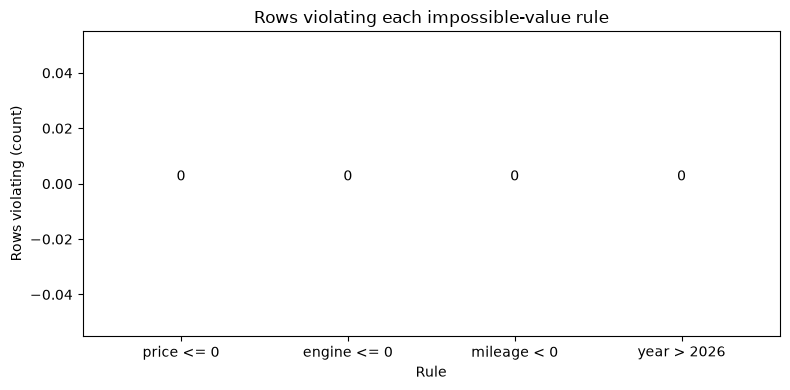

ไม่พบค่าที่เป็นไปไม่ได้


In [7]:
# [07] ตรวจคุณภาพ 3: ค่าที่เป็นไปไม่ได้
# ==================================================
# ทำอะไร: นับแถวที่ฝ่าฝืนกฎ "ค่าที่เป็นไปไม่ได้ในโลกจริง" 4 ข้อ
#         1) price <= 0     ราคาขายต้องมากกว่า 0 บาท
#         2) engine <= 0    ขนาดเครื่องยนต์ (cc) ต้องมากกว่า 0
#         3) mileage < 0    เลขไมล์ติดลบไม่ได้ (ไมล์เป็น 0 ได้ เช่นรถใหม่)
#         4) year > CURRENT_YEAR   ปีของรถต้องไม่เกินปีปัจจุบัน (CURRENT_YEAR กำหนดในเซลล์ [03])
# ทำไม: ค่าที่เป็นไปไม่ได้แปลว่าข้อมูลผิดแน่นอน (เช่นกรอกผิดหรือระบบเก็บพลาด) ไม่เหมือนค่าที่แค่หายาก
#       ถ้ามีอยู่จะทำให้โมเดลเรียนรู้จากข้อมูลเท็จ ใช้เฉพาะกฎที่ตรรกะบังคับเท่านั้น
#       ไม่คิดเกณฑ์ที่ตั้งเองตามใจ เช่น "รถเก่าเกินไป" เพราะรถเก่ามากที่ราคาสูงก็มีจริง (รถคลาสสิก)
# ผลที่ควรเห็น: ตารางแต่ละกฎกับจำนวนแถวที่ฝ่าฝืน และกราฟแท่งของแต่ละกฎ
#       ถ้าทุกกฎเป็น 0 แปลว่าไม่พบค่าที่เป็นไปไม่ได้ ถ้าไม่ใช่ ควรดูแถวนั้นก่อนตัดสินใจว่าจะทำอย่างไร
#       (เซลล์นี้ไม่แก้และไม่ลบข้อมูล)
# ==================================================
print("=== [07] ตรวจคุณภาพ 3: ค่าที่เป็นไปไม่ได้ ===")

impossible_counts = {
    "price <= 0": int((raw_df["price"] <= 0).sum()),
    "engine <= 0": int((raw_df["engine"] <= 0).sum()),
    "mileage < 0": int((raw_df["mileage"] < 0).sum()),
    f"year > {CURRENT_YEAR}": int((raw_df["year"] > CURRENT_YEAR).sum()),
}

impossible_table = pd.DataFrame({
    "rows_violating": pd.Series(impossible_counts),
})

print("ตารางนี้บอกว่าแต่ละกฎมีกี่แถวที่ฝ่าฝืน (ควรเป็น 0 ทุกกฎ)")
display(impossible_table.style.format({"rows_violating": "{:,.0f}"}))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(impossible_table.index, impossible_table["rows_violating"])
ax.bar_label(bars, fmt="{:,.0f}")
ax.set_title("Rows violating each impossible-value rule")
ax.set_xlabel("Rule")
ax.set_ylabel("Rows violating (count)")
plt.tight_layout()
plt.show()

total_impossible = sum(impossible_counts.values())
if total_impossible == 0:
    print("ไม่พบค่าที่เป็นไปไม่ได้")
else:
    print(f"พบการฝ่าฝืนกฎรวม {total_impossible:,} ครั้ง (นับซ้ำได้ถ้าแถวเดียวฝ่าฝืนหลายกฎ)")

=== [08] ตรวจคุณภาพ 4: การกระจายของตัวเลข ===
ตารางนี้สรุปสถิติของคอลัมน์ตัวเลข: count=จำนวนแถว, 25%/50%/75%=Q1/มัธยฐาน/Q3


,price,engine,mileage,year
count,"46,074","46,074","46,074","46,074"
mean,"555,577","1,922","115,309","2,019"
std,"328,567",513,"62,748",4
min,"60,000","1,000",300,"2,006"
25%,"339,000","1,500","67,500","2,017"
50%,"469,000","2,000","107,500","2,019"
75%,"689,000","2,400","157,500","2,022"
max,"2,000,000","3,500","300,000","2,026"


C:\Users\putaw\AppData\Local\Temp\ipykernel_22284\3351676981.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, position].boxplot(raw_df[column], vert=False)
C:\Users\putaw\AppData\Local\Temp\ipykernel_22284\3351676981.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, position].boxplot(raw_df[column], vert=False)
C:\Users\putaw\AppData\Local\Temp\ipykernel_22284\3351676981.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1, position].boxplot(raw_df[column], vert=False)
C:\Users\putaw\AppData\Local\Temp\ipykernel_22284\3351676981.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be re

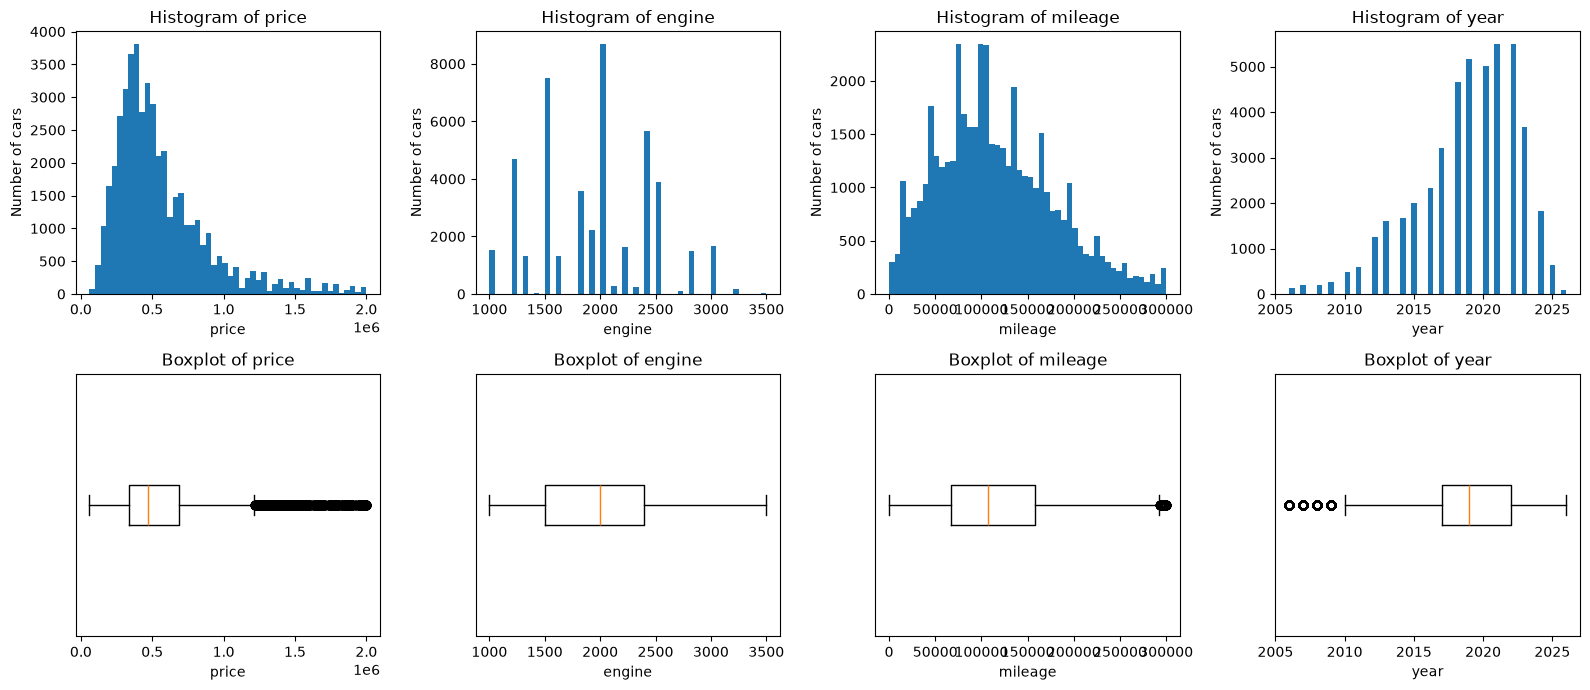

price   : ค่าความเบ้ +1.66 -> เบ้ขวาชัดเจน (หางยาวไปทางค่าสูง)
engine  : ค่าความเบ้ +0.19 -> ไม่เบ้มาก
mileage : ค่าความเบ้ +0.54 -> ไม่เบ้มาก
year    : ค่าความเบ้ -0.79 -> ไม่เบ้มาก


In [8]:
# [08] ตรวจคุณภาพ 4: การกระจายของตัวเลข
# ==================================================
# ทำอะไร: สรุปสถิติ (describe) ของคอลัมน์ตัวเลข 4 ตัว (price, engine, mileage, year)
#         แล้ววาด histogram (แถวบน) และ boxplot (แถวล่าง) ของแต่ละตัว
# ทำไม: การดูรูปร่างการกระจายของข้อมูลช่วยให้เห็นสิ่งที่ตัวเลขสรุปไม่บอก เช่น ข้อมูลเบ้ หรือถูกตัดที่ค่าสูงสุด
# วิธีอ่านกราฟ (เป็นสิ่งที่ควรสังเกต ไม่ใช่ข้อเท็จจริงของการรันครั้งนี้):
#   - Histogram: แบ่งค่าเป็นช่วง (bins = 50 ช่วง) แท่งสูง = มีรถในช่วงราคา/ค่านั้นมาก
#   - Boxplot: กล่อง = ข้อมูลตรงกลาง 50% (จาก Q1 ถึง Q3), เส้นในกล่อง = มัธยฐาน (median คือค่ากลางเมื่อเรียงลำดับ),
#              หนวด (whiskers) = ช่วงที่ยังถือว่าปกติ, จุดนอกหนวด = ค่าที่ห่างมาก (outlier)
#   - ความเบ้ (skew): ถ้าหางยาวไปทางขวา (ส่วนใหญ่ค่าต่ำ มีบางคันแพงมาก) เรียกว่าเบ้ขวา ราคารถมักเป็นแบบนี้
#   - แท่งสูงผิดปกติที่ค่าสูงสุด: อาจหมายถึงข้อมูลถูกตัดเพดาน (capped) ตอนเก็บ เช่น ทุกคันที่แพงกว่าเพดานถูกบันทึกเป็นค่าเพดาน
# ผลที่ควรเห็น: ตารางสถิติ (จำนวน ค่าเฉลี่ย ส่วนเบี่ยงเบนมาตรฐาน ต่ำสุด quartile สูงสุด) และรูป 2 แถว 4 คอลัมน์
#       ตารางไม่ได้ถูกแก้ข้อมูลใด ๆ เซลล์นี้รายงานอย่างเดียว
# ==================================================
print("=== [08] ตรวจคุณภาพ 4: การกระจายของตัวเลข ===")

numeric_check_columns = ["price", "engine", "mileage", "year"]

print("ตารางนี้สรุปสถิติของคอลัมน์ตัวเลข: count=จำนวนแถว, 25%/50%/75%=Q1/มัธยฐาน/Q3")
display(raw_df[numeric_check_columns].describe().style.format("{:,.0f}"))

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for position, column in enumerate(numeric_check_columns):
    axes[0, position].hist(raw_df[column], bins=50)
    axes[0, position].set_title(f"Histogram of {column}")
    axes[0, position].set_xlabel(column)
    axes[0, position].set_ylabel("Number of cars")
    axes[1, position].boxplot(raw_df[column], vert=False)
    axes[1, position].set_title(f"Boxplot of {column}")
    axes[1, position].set_xlabel(column)
    axes[1, position].set_yticks([])
plt.tight_layout()
plt.show()

skewness = raw_df[numeric_check_columns].skew()
for column in numeric_check_columns:
    if skewness[column] > 1:
        shape = "เบ้ขวาชัดเจน (หางยาวไปทางค่าสูง)"
    elif skewness[column] < -1:
        shape = "เบ้ซ้ายชัดเจน (หางยาวไปทางค่าต่ำ)"
    else:
        shape = "ไม่เบ้มาก"
    print(f"{column:<8}: ค่าความเบ้ {skewness[column]:+.2f} -> {shape}")

=== [09] ตรวจคุณภาพ 5: ค่าผิดปกติ (IQR) ===
ตารางนี้บอกรั้วล่าง/บนของแต่ละคอลัมน์ และจำนวนแถวที่อยู่นอกรั้ว


column,q1,q3,iqr,lower_fence,upper_fence,below,above,outlier_percent,outliers
price,"339,000","689,000","350,000","-186,000","1,214,000",0,"2,461",5.34,"2,461"
engine,"1,500","2,400",900,150,"3,750",0,0,0.00,0
mileage,"67,500","157,500","90,000","-67,500","292,500",0,254,0.55,254
year,"2,017","2,022",5,"2,010","2,030",810,0,1.76,810


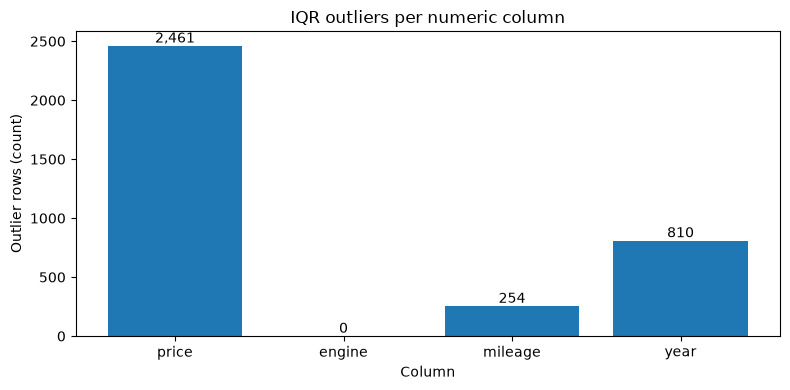

พบค่านอกรั้ว IQR รวม 3,525 ค่า (ไม่ได้ลบ เพราะอาจเป็นข้อมูลจริง)


In [9]:
# [09] ตรวจคุณภาพ 5: ค่าผิดปกติ (IQR)
# ==================================================
# ทำอะไร: หาค่าผิดปกติ (outlier คือค่าที่ห่างจากส่วนใหญ่มาก) ของคอลัมน์ตัวเลขแต่ละตัวด้วยกฎ IQR ของ Tukey
#         ขั้นตอน: หา Q1 (ค่าที่ 25% ของข้อมูลต่ำกว่า) และ Q3 (ค่าที่ 75%)
#                  IQR = Q3 - Q1 (ความกว้างของข้อมูลตรงกลาง 50%)
#                  รั้วล่าง = Q1 - 1.5 x IQR, รั้วบน = Q3 + 1.5 x IQR
#                  ค่าที่ต่ำกว่ารั้วล่างหรือสูงกว่ารั้วบนนับเป็น outlier
# ทำไม: 1.5 เป็นค่าที่ John Tukey เสนอไว้เป็นธรรมเนียมปฏิบัติ (convention) ไม่ใช่กฎธรรมชาติ
#       ต้องระวังว่า outlier ไม่ได้แปลว่าข้อมูลผิดเสมอไป รถแพงมากมีอยู่จริง จึงเป็นข้อมูลจริงที่ควรเก็บไว้
#       ต้นไม้ตัดสินใจ (decision tree) แบ่งข้อมูลด้วยลำดับ (มากกว่า/น้อยกว่าเกณฑ์) จึงไม่สนใจว่าค่าสุดโต่งนั้นสุดโต่งแค่ไหน
#       ค่าฟีเจอร์ที่สุดโต่งจึงกระทบต้นไม้น้อย (ต่างจากโมเดลเชิงเส้นที่ถูกลากง่าย)
#       เซลล์นี้ไม่ลบหรือแก้ค่าใดเลย รายงานอย่างเดียว
# ผลที่ควรเห็น: ตารางต่อคอลัมน์ (Q1, Q3, IQR, รั้วล่าง/บน, จำนวนที่ต่ำกว่า/สูงกว่า, เปอร์เซ็นต์ของแถวทั้งหมด)
#       และกราฟแท่งจำนวน outlier ต่อคอลัมน์ ถ้าแท่งสูงให้ดูว่าเป็นค่าจริงที่หายากหรือสัญญาณข้อมูลผิด
# ==================================================
print("=== [09] ตรวจคุณภาพ 5: ค่าผิดปกติ (IQR) ===")

numeric_check_columns = ["price", "engine", "mileage", "year"]

rows = []
for column in numeric_check_columns:
    q1 = raw_df[column].quantile(0.25)
    q3 = raw_df[column].quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    below = int((raw_df[column] < lower_fence).sum())
    above = int((raw_df[column] > upper_fence).sum())
    rows.append({
        "column": column,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "lower_fence": lower_fence,
        "upper_fence": upper_fence,
        "below": below,
        "above": above,
        "outlier_percent": (below + above) / len(raw_df) * 100,
    })

outlier_table = pd.DataFrame(rows)
outlier_table["outliers"] = outlier_table["below"] + outlier_table["above"]

print("ตารางนี้บอกรั้วล่าง/บนของแต่ละคอลัมน์ และจำนวนแถวที่อยู่นอกรั้ว")
display(outlier_table.style.hide(axis="index").format({
    "q1": "{:,.0f}",
    "q3": "{:,.0f}",
    "iqr": "{:,.0f}",
    "lower_fence": "{:,.0f}",
    "upper_fence": "{:,.0f}",
    "below": "{:,.0f}",
    "above": "{:,.0f}",
    "outlier_percent": "{:.2f}",
    "outliers": "{:,.0f}",
}))

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(outlier_table["column"], outlier_table["outliers"])
ax.bar_label(bars, fmt="{:,.0f}")
ax.set_title("IQR outliers per numeric column")
ax.set_xlabel("Column")
ax.set_ylabel("Outlier rows (count)")
plt.tight_layout()
plt.show()

total_outliers = int(outlier_table["outliers"].sum())
if total_outliers == 0:
    print("ไม่พบค่าผิดปกติตามกฎ IQR")
else:
    print(f"พบค่านอกรั้ว IQR รวม {total_outliers:,} ค่า (ไม่ได้ลบ เพราะอาจเป็นข้อมูลจริง)")

=== [10] ตรวจคุณภาพ 6: ตัวแปรกลุ่ม ===
ตารางนี้บอกจำนวนระดับของแต่ละคอลัมน์กลุ่ม และระดับที่พบบ่อยที่สุดพร้อมสัดส่วน


column,levels,most_common,most_common_share_percent,smallest_level_rows
brand,20,TOYOTA,32.98,89
model,115,HILUX REVO,5.77,49
car_type,7,Sedan,29.29,"1,765"
fuel,3,Benzine,49.90,"5,281"
gear,2,Automatic,87.96,"5,548"
color,18,White,35.02,23


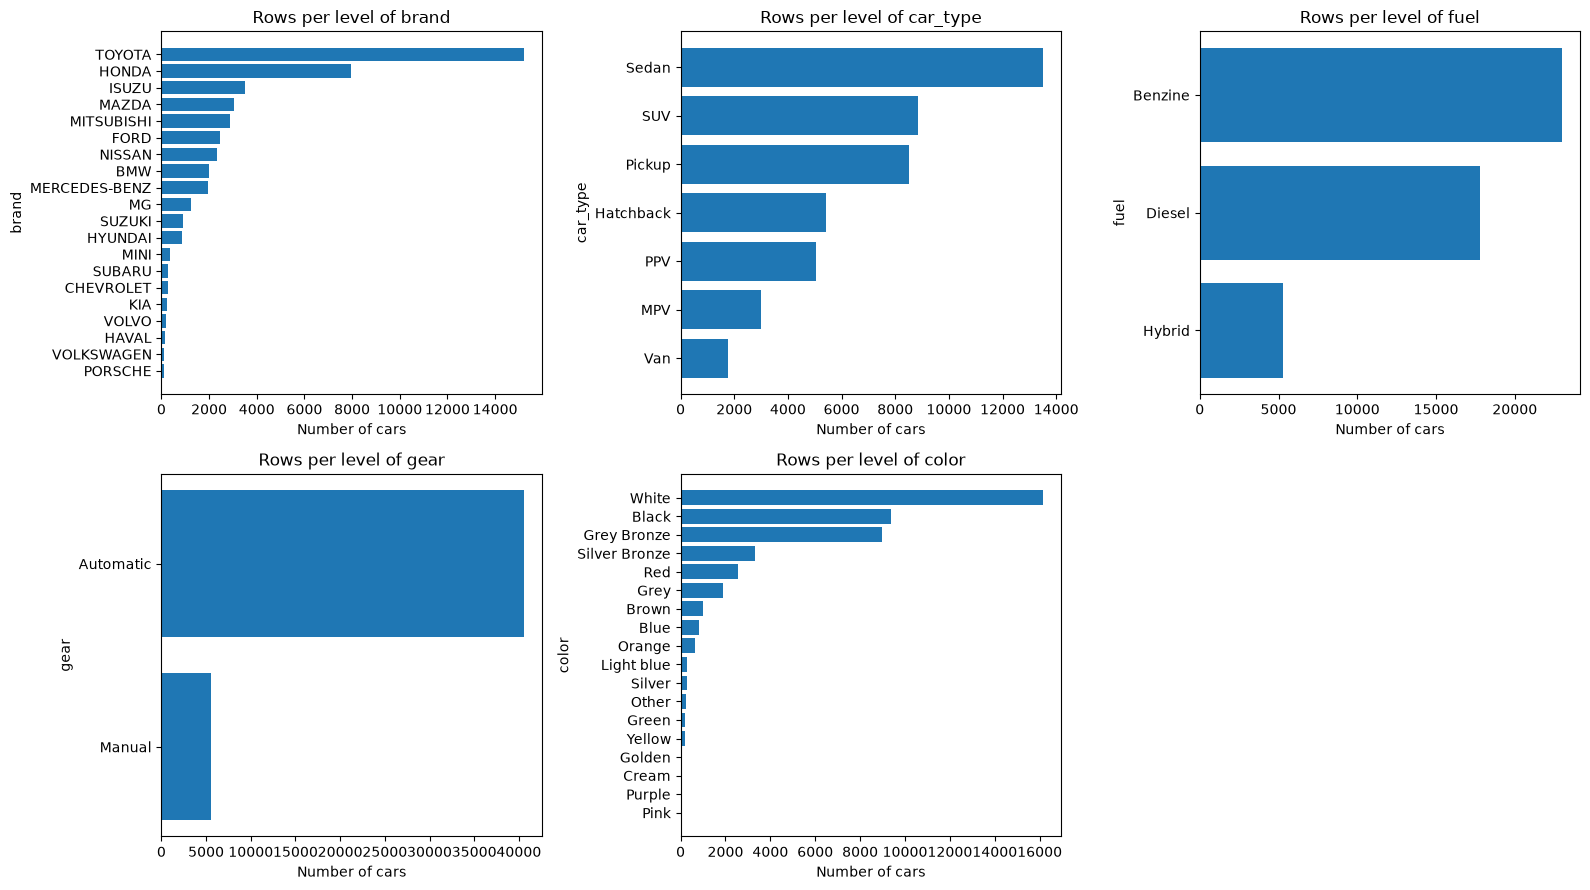

ระดับที่มีแถวน้อยที่สุดในทุกคอลัมน์กลุ่ม มี 23 แถว


In [10]:
# [10] ตรวจคุณภาพ 6: ตัวแปรกลุ่ม
# ==================================================
# ทำอะไร: ดูคอลัมน์ที่เป็นกลุ่ม/ประเภท (categorical) 6 ตัว: brand, model, car_type, fuel, gear, color
#         นับจำนวนระดับ (level คือค่าที่แตกต่างกัน เช่น fuel มี เบนซิน/ดีเซล/...) ระดับที่พบบ่อยที่สุดและสัดส่วนของมัน
#         แล้ววาดแท่งแนวนอนจำนวนแถวต่อระดับ ของ brand, car_type, fuel, gear, color
# ทำไม: ระดับที่หายาก (rare level คือมีแถวน้อยมาก) สร้างปัญหาสองอย่าง
#       1) One-hot encoding (แปลงแต่ละระดับเป็นคอลัมน์ 0/1) จะได้คอลัมน์ที่เกือบทั้งหมดเป็น 0 และเรียนรู้อะไรไม่ได้มาก
#       2) การแบ่งข้อมูลและการแบ่งโหนดของต้นไม้: ถ้าระดับหนึ่งมีไม่กี่แถว อาจไม่มีตัวอย่างในชุดทดสอบ หรือต้นไม้
#          แบ่งตามระดับนั้นแล้วได้ใบ (leaf) เล็กจนไม่น่าเชื่อถือ
#       คอลัมน์ model มีหลายระดับเกินกว่าจะวาดเป็นกราฟแท่ง เซลล์ [11] ดูเรื่องนี้แยกต่างหาก
# ผลที่ควรเห็น: ตารางต่อคอลัมน์ (จำนวนระดับ ระดับที่พบมากสุด สัดส่วน) และรูป 2x3 ช่อง ใช้ 5 ช่อง
#       ช่องที่หกถูกลบทิ้ง ในกราฟ แท่งสั้นมาก ๆ คือระดับหายาก
# ==================================================
print("=== [10] ตรวจคุณภาพ 6: ตัวแปรกลุ่ม ===")

categorical_check_columns = ["brand", "model", "car_type", "fuel", "gear", "color"]

rows = []
for column in categorical_check_columns:
    counts = raw_df[column].value_counts()
    rows.append({
        "column": column,
        "levels": len(counts),
        "most_common": counts.index[0],
        "most_common_share_percent": counts.iloc[0] / len(raw_df) * 100,
        "smallest_level_rows": counts.min(),
    })
level_table = pd.DataFrame(rows)

print("ตารางนี้บอกจำนวนระดับของแต่ละคอลัมน์กลุ่ม และระดับที่พบบ่อยที่สุดพร้อมสัดส่วน")
display(level_table.style.hide(axis="index").format({
    "levels": "{:,.0f}",
    "most_common_share_percent": "{:.2f}",
    "smallest_level_rows": "{:,.0f}",
}))

plot_columns = ["brand", "car_type", "fuel", "gear", "color"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
flat_axes = axes.flatten()
for position, column in enumerate(plot_columns):
    counts = raw_df[column].value_counts().sort_values()
    flat_axes[position].barh(counts.index.astype(str), counts.to_numpy())
    flat_axes[position].set_title(f"Rows per level of {column}")
    flat_axes[position].set_xlabel("Number of cars")
    flat_axes[position].set_ylabel(column)
fig.delaxes(flat_axes[5])
plt.tight_layout()
plt.show()

smallest_level_rows = level_table["smallest_level_rows"].min()
print(f"ระดับที่มีแถวน้อยที่สุดในทุกคอลัมน์กลุ่ม มี {smallest_level_rows:,} แถว")

=== [11] ตรวจคุณภาพ 7: จำนวนรถต่อรุ่น ===
จำนวนรุ่น (brand|model) : 115
แถวต่อรุ่น ต่ำสุด       : 49
แถวต่อรุ่น มัธยฐาน      : 190
แถวต่อรุ่น สูงสุด       : 2,658
ตารางนี้แสดง 10 รุ่นที่มีแถวน้อยที่สุด


brand,model,rows
VOLVO,XC90,49
VOLVO,XC40,51
MERCEDES-BENZ,S300,52
MG,VS HEV,52
TOYOTA,PRIUS,52
NISSAN,SYLPHY,53
CHEVROLET,TRAILBLAZER,54
MERCEDES-BENZ,E250,58
HAVAL,JOLION,61
TOYOTA,HARRIER,66


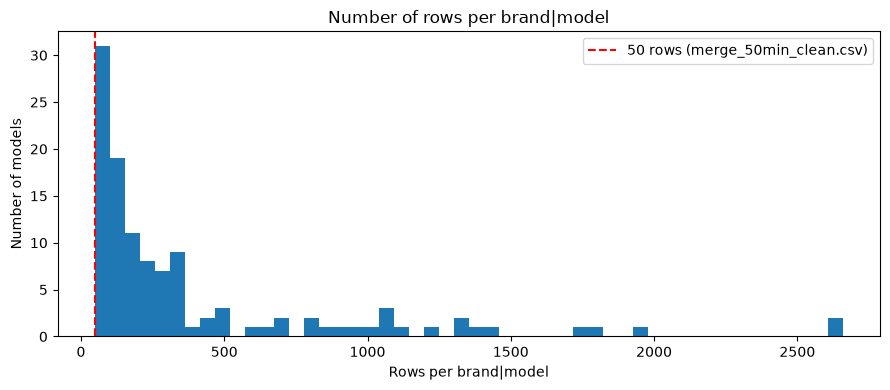

พบรุ่นที่มีแถวน้อยกว่า 50: 1 รุ่น


In [11]:
# [11] ตรวจคุณภาพ 7: จำนวนรถต่อรุ่น
# ==================================================
# ทำอะไร: นับจำนวนแถวต่อรุ่นรถ (หนึ่งรุ่น = หนึ่งคู่ brand + model) แล้วแสดงค่าต่ำสุด มัธยฐาน สูงสุด
#         ตาราง 10 รุ่นที่มีแถวน้อยที่สุด และ histogram ของจำนวนแถวต่อรุ่น
#         มีเส้นประแนวตั้งที่ 50 แถว (ขอบล่างตามชื่อไฟล์)
# ทำไม: ไฟล์ merge_50min_clean.csv ยังคงเก็บเฉพาะรุ่นที่มีอย่างน้อย 50 แถว
#       จำนวนแถวต่อรุ่นสำคัญ เพราะเซลล์ [13] แบ่งข้อมูลแบบ stratified (แบ่งโดยรักษาสัดส่วนของแต่ละรุ่น)
#       คือเอา 80/10/10 ของ "แต่ละรุ่น" ไปไว้ใน train/validation/test
#       ถ้ารุ่นหนึ่งมีแถวน้อย ชุดทดสอบจะได้แถวของรุ่นนั้นน้อยมาก (เช่น 50 แถว x 10% = 5 แถว)
#       ผลการวัดของรุ่นนั้นจึงไม่นิ่ง การตรวจนี้จึงยืนยันว่าเงื่อนไขขั้นต่ำ 50 แถวเป็นจริง
# ผลที่ควรเห็น: ค่า min/median/max, ตาราง 10 รุ่นที่เล็กที่สุด, histogram (หางขวายาวเป็นปกติ
#       เพราะรุ่นยอดนิยมมีแถวมาก) ถ้าค่าต่ำสุดน้อยกว่า 50 แสดงว่าไฟล์ไม่ตรงกับชื่อ ซึ่งบรรทัดสุดท้ายจะรายงานให้
# ==================================================
print("=== [11] ตรวจคุณภาพ 7: จำนวนรถต่อรุ่น ===")

rows_per_model = raw_df.groupby(["brand", "model"]).size()

print(f"จำนวนรุ่น (brand|model) : {len(rows_per_model):,}")
print(f"แถวต่อรุ่น ต่ำสุด       : {rows_per_model.min():,.0f}")
print(f"แถวต่อรุ่น มัธยฐาน      : {rows_per_model.median():,.0f}")
print(f"แถวต่อรุ่น สูงสุด       : {rows_per_model.max():,.0f}")

smallest_models = rows_per_model.sort_values().head(10).rename("rows").reset_index()
print("ตารางนี้แสดง 10 รุ่นที่มีแถวน้อยที่สุด")
display(smallest_models.style.hide(axis="index").format({"rows": "{:,.0f}"}))

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(rows_per_model, bins=50)
ax.axvline(50, color="red", linestyle="--", label="50 rows (merge_50min_clean.csv)")
ax.set_title("Number of rows per brand|model")
ax.set_xlabel("Rows per brand|model")
ax.set_ylabel("Number of models")
ax.legend()
plt.tight_layout()
plt.show()

if rows_per_model.min() >= 50:
    print("ทุกรุ่นมีอย่างน้อย 50 แถว ตามเงื่อนไขของไฟล์ merge_50min_clean.csv")
else:
    print(f"พบรุ่นที่มีแถวน้อยกว่า 50: {int((rows_per_model < 50).sum()):,} รุ่น")

In [12]:
# [12] เตรียมข้อมูล: car_age และตัดคอลัมน์
# ==================================================
# ทำอะไร: ทำสำเนาของ raw_df เป็น df แล้ว
#         (1) สร้างคอลัมน์ car_age = CURRENT_YEAR - year (อายุรถเป็นปี)
#         (2) ตัดคอลัมน์ year และ color ทิ้ง
#         (3) ตรวจว่าคอลัมน์ที่ใช้ทั้งหมดไม่มีค่าว่าง
# ทำไม:
#   - ตัด year เพราะ car_age บอกข้อมูลเดียวกันอยู่แล้ว (ปีที่ผลิตมากขึ้น = อายุน้อยลง)
#     เก็บไว้ทั้งสองจะซ้ำซ้อน
#   - ตัด color เพราะเป็นการตัดสินใจของโปรเจกต์ที่จะไม่ใช้สีเป็น feature
#     (ผลของการตัดนี้ต่อแถวที่ค่าเหมือนกันข้ามชุด อธิบายไว้ในเซลล์ [13])
#   - สร้าง df จาก raw_df.copy() ทุกครั้ง เพื่อให้รันเซลล์นี้ซ้ำได้ ไม่แก้ raw_df
#     ถ้าแก้ df ตรงๆ รอบที่สองจะไม่มีคอลัมน์ year ให้คำนวณแล้ว
#   - ไม่เปลี่ยนชื่อคอลัมน์ engine, fuel, gear เป็น engine_capacity, fuel_type, gear_type
#     ที่ต้นฉบับทำ เพราะผู้ใช้สั่งให้ใช้ชื่อตามไฟล์ข้อมูล การเปลี่ยนชื่อไม่มีผลกับตัวเลขของโมเดล
#     (ทดสอบแล้วได้ R² เท่าเดิมทุกหลัก) ต่างกันแค่ชื่อที่แสดงใน features และ RESULT_JSON
#     ถ้าจะเทียบกับไฟล์โมเดล V4 เดิม (V4_*_min50.json) ต้องจับคู่ชื่อเอง
# ผลที่ควรเห็น: ขนาดตาราง df และรายชื่อคอลัมน์ (ต้องไม่มี year และ color แต่มี car_age)
# ==================================================
print("=== [12] เตรียมข้อมูล: car_age และตัดคอลัมน์ ===")

df = raw_df.copy()
df["car_age"] = CURRENT_YEAR - df["year"]
df = df.drop(columns=["year", "color"])
assert df[NUM_COLS + CAT_COLS + ["price"]].notna().all().all()

print(f"ขนาดตาราง df : {df.shape[0]:,} แถว x {df.shape[1]:,} คอลัมน์")
print(f"คอลัมน์      : {list(df.columns)}")

=== [12] เตรียมข้อมูล: car_age และตัดคอลัมน์ ===
ขนาดตาราง df : 46,074 แถว x 9 คอลัมน์
คอลัมน์      : ['brand', 'model', 'car_type', 'fuel', 'gear', 'engine', 'mileage', 'price', 'car_age']


In [13]:
# [13] แบ่ง train / validation / test
# ==================================================
# ทำอะไร: แบ่ง df เป็น train 80% / validation 10% / test 10% โดยแบ่งทีละรุ่นรถ (stratify)
# ทำไม:
#   - ทำไมแบ่งสามชุด: train สอนโมเดล, validation กันไว้ตรวจผลอีกชุด (การเลือกพารามิเตอร์ใช้ CV บน train),
#     test ตัดสินผลสุดท้ายครั้งเดียว (ดูอภิธานศัพท์ในเซลล์ [01])
#   - ทำไมต้อง stratify: แบ่งทีละรุ่น ไม่ใช่สุ่มรวมทั้งก้อน
#     ตัวอย่าง: HONDA|CR-V มี 100 แถว จะได้ train 80, validation 10, test 10
#               TOYOTA|Camry มี 60 แถว จะได้ train 48, validation 6, test 6
#     ทำให้ทุกรุ่นอยู่ครบทั้ง 3 ชุดในสัดส่วนเดียวกัน ผล test จึงสะท้อนข้อมูลทั้งชุด
#     ถ้าสุ่มเฉยๆ รุ่นที่มีน้อยอาจไปกองอยู่ใน test หรือไม่มีใน test เลย
#   - ทำไมป้ายกลุ่ม (model_key) มียี่ห้อด้วย: เป็นรูปแบบ "ยี่ห้อ|รุ่น" เช่น "HONDA|CR-V"
#     เพราะรุ่นชื่อเดียวกันจากต่างยี่ห้อต้องไม่ถูกนับเป็นกลุ่มเดียวกัน
#     และ stratify รับป้ายได้คอลัมน์เดียว ป้ายนี้ใช้แค่ตอนแบ่งข้อมูล
#     ไม่ได้เพิ่มเข้าตาราง และโมเดลไม่เคยเห็น
#   - แบ่งสองรอบ: รอบแรกแยก train 80% ส่วนที่เหลือ 20% เก็บใน temp
#     รอบสองแบ่ง temp ครึ่งต่อครึ่ง (0.1 / 0.2 = 0.5) ได้ validation 10% และ test 10%
#   - random_state=SEED ทำให้แบ่งกี่ครั้งก็ได้ชุดเดิม
# ผลที่ควรเห็น: ตารางสรุปแต่ละชุด ได้แก่ จำนวนแถว สัดส่วนต่อทั้งหมด และจำนวนรุ่น (ยี่ห้อ|รุ่น)
#       ที่ไม่ซ้ำ จำนวนรุ่นของ validation และ test ควรใกล้เคียงกัน เพราะแบ่งแบบ stratify
# ข้อควรระวัง: แถวที่ค่าเหมือนกันข้ามชุด
#   หลังตัด color อาจมีแถวใน test หรือ validation ที่ค่าทุกคอลัมน์ที่ใช้
#   (รวมราคา) ตรงกับแถวใน train แม้แถวต้นทางจะต่างกันที่สี
#   ดูจำนวนแถวซ้ำในไฟล์ที่ทำความสะอาดแล้วจากเซลล์ [06]
#   และดูขนาดของแต่ละชุดจากตารางด้านล่าง ไม่ใช้ตัวเลขจากไฟล์ก่อนทำความสะอาด
#   ตามกติกาของโปรเจกต์ ถ้าสองแถวไม่เหมือนกันทุกคอลัมน์ (นอกจากราคา)
#   ถือเป็นรถคนละคัน เช่น แถวที่ต่างกันที่สีอาจมีสเปกและราคาเหมือนกัน
#   จึงควรตรวจลักษณะของแถวที่ตรงกันก่อนสรุปว่าเป็นรถคันเดียวที่ลงประกาศซ้ำ
# ==================================================
print("=== [13] แบ่ง train / validation / test ===")

model_key = df["brand"] + "|" + df["model"]

# รอบแรก: แยก train 80% ที่เหลือ 20% เก็บใน temp
train, temp = train_test_split(df, train_size=TRAIN_SIZE, stratify=model_key, random_state=SEED)

# รอบสอง: แบ่ง temp ครึ่งต่อครึ่ง ได้ validation และ test
val, test = train_test_split(
    temp,
    test_size=TEST_SIZE / (VAL_SIZE + TEST_SIZE),
    stratify=model_key.loc[temp.index],
    random_state=SEED,
)

split_table = pd.DataFrame({
    "ชุด": ["train", "validation", "test"],
    "แถว": [len(train), len(val), len(test)],
    "สัดส่วน (%)": [100 * len(part) / len(df) for part in (train, val, test)],
    "จำนวนรุ่น": [model_key.loc[part.index].nunique() for part in (train, val, test)],
})
print("อ่านตาราง: แต่ละชุดมีกี่แถว คิดเป็นกี่ % ของทั้งหมด และมีกี่รุ่น (ยี่ห้อ|รุ่น) ที่ไม่ซ้ำ")
display(
    split_table.style
    .format({"แถว": "{:,.0f}", "สัดส่วน (%)": "{:.2f}", "จำนวนรุ่น": "{:,.0f}"})
    .hide(axis="index")
)

=== [13] แบ่ง train / validation / test ===


อ่านตาราง: แต่ละชุดมีกี่แถว คิดเป็นกี่ % ของทั้งหมด และมีกี่รุ่น (ยี่ห้อ|รุ่น) ที่ไม่ซ้ำ


ชุด,แถว,สัดส่วน (%),จำนวนรุ่น
train,"36,859",80.00,115
validation,"4,607",10.00,115
test,"4,608",10.00,115


In [14]:
# [14] สร้าง 5 fold
# ==================================================
# ทำอะไร: แบ่งชุด train เป็น N_FOLDS ส่วน (fold) ด้วย KFold เก็บเป็นรายการ folds
#         แต่ละสมาชิกคือคู่ (แถวที่ใช้สอน, แถวที่ใช้ตรวจ)
# ทำไม:
#   - K-fold cross-validation: แบ่ง train เป็น K ส่วนเท่าๆ กัน แล้วผลัดกันเอา 1 ส่วนเป็นชุดตรวจ
#     อีก K-1 ส่วนเป็นชุดสอน ทำ K รอบ แล้วเฉลี่ยคะแนน ได้ค่าที่เชื่อถือกว่าการตรวจรอบเดียว
#     และไม่ต้องแตะ validation / test
#   - สร้าง folds ครั้งเดียวแล้วให้ทุกขั้นตอนถัดไปใช้ร่วมกัน ทุกการเปรียบเทียบจึงใช้แถวชุดเดียวกัน
#     ผลต่างที่เห็นมาจากตัวเลือกที่เทียบจริง ไม่ใช่จากการแบ่ง fold ที่ต่างกัน
#   - shuffle=True สลับลำดับแถวก่อนแบ่ง เพราะข้อมูลอาจเรียงตามยี่ห้อหรือราคา
#     การแบ่งตามลำดับจะทำให้ fold ไม่เป็นตัวแทนของทั้งชุด
#     และใช้ random_state=SEED ให้สลับแล้วได้ผลเดิมทุกครั้ง
# ผลที่ควรเห็น: ตารางหนึ่งแถวต่อ fold บอกจำนวนแถวที่ใช้สอนและแถวที่ใช้ตรวจ
#       ผลรวมสองคอลัมน์ในแต่ละแถวเท่ากับจำนวนแถวของ train
# ข้อควรระวัง: validation และ test ไม่ถูกใช้จนถึงขั้นวัดผลสุดท้าย
# ==================================================
print("=== [14] สร้าง 5 fold ===")

folds = list(KFold(N_FOLDS, shuffle=True, random_state=SEED).split(train))

fold_rows = []
for fold_number, (train_index, valid_index) in enumerate(folds, start=1):
    fold_rows.append({
        "fold": fold_number,
        "แถวสำหรับสอน": len(train_index),
        "แถวสำหรับตรวจ": len(valid_index),
    })
fold_table = pd.DataFrame(fold_rows)
print("อ่านตาราง: แต่ละ fold ใช้กี่แถวสอนและกี่แถวตรวจ (ทุก fold ใช้ train ชุดเดียวกัน)")
display(
    fold_table.style
    .format({"fold": "{:.0f}", "แถวสำหรับสอน": "{:,.0f}", "แถวสำหรับตรวจ": "{:,.0f}"})
    .hide(axis="index")
)

=== [14] สร้าง 5 fold ===
อ่านตาราง: แต่ละ fold ใช้กี่แถวสอนและกี่แถวตรวจ (ทุก fold ใช้ train ชุดเดียวกัน)


fold,แถวสำหรับสอน,แถวสำหรับตรวจ
1,"29,487","7,372"
2,"29,487","7,372"
3,"29,487","7,372"
4,"29,487","7,372"
5,"29,488","7,371"


In [15]:
# [15] ฟังก์ชันวัดความสัมพันธ์
# ==================================================
# ทำอะไร: สร้างฟังก์ชัน 2 ตัวไว้วัดว่าตัวแปร 2 ตัว "สัมพันธ์กัน" มากแค่ไหน
#   - cramers_v(x, y)              : ใช้กับตัวแปรหมวดหมู่ 2 ตัว (เช่น brand กับ model)
#   - correlation_ratio(cats, vals): ใช้กับตัวแปรหมวดหมู่ 1 ตัว กับตัวเลข 1 ตัว (เช่น brand กับ price)
#   ส่วนตัวเลขกับตัวเลขใช้ Spearman ของ pandas ได้เลย ไม่ต้องสร้างฟังก์ชันเอง
# ทำไม: ข้อมูลรถมีทั้งตัวเลข (engine, mileage, car_age, price) และหมวดหมู่ (brand, model,
#   car_type, fuel, gear) การวัดแบบเดียวไม่เหมาะกับทุกคู่
#   เช่น ค่าสหสัมพันธ์ปกติ (Pearson) ใช้กับ "brand" ไม่ได้เพราะ brand ไม่ใช่ตัวเลข
#   จึงต้องเลือกตัววัดให้ตรงกับชนิดของตัวแปรแต่ละคู่:
#     1) ตัวเลข-ตัวเลข   : Spearman  = สหสัมพันธ์แบบเรียงอันดับ (rank) ค่าจริง -1..1
#                          เซลล์ [16] ใช้ค่าสัมบูรณ์ เพื่อให้อยู่สเกล 0..1 เหมือนตัววัดอื่น
#     2) หมวดหมู่-หมวดหมู่ : Cramér's V = ปรับจากค่าไคสแควร์ (chi-square) ของตารางไขว้
#                          ให้อยู่ในช่วง 0..1
#     3) หมวดหมู่-ตัวเลข  : η (อีตา, correlation ratio)
#                          = รากของ (ความแปรปรวนระหว่างกลุ่ม / ความแปรปรวนรวม)
#                          บอกว่าค่าเฉลี่ยของแต่ละหมวด อธิบายความผันผวนของตัวเลขได้กี่ส่วน
#   ทั้งสามตัววัดตีความเหมือนกัน: 0 = ไม่สัมพันธ์กันเลย, 1 = สัมพันธ์กันสมบูรณ์
#   (รู้ค่าของตัวหนึ่งก็บอกอีกตัวได้แน่นอน)
# ผลที่ควรเห็น: พิมพ์ข้อความว่าสร้างฟังก์ชันแล้ว และผ่านการเช็กตัวเอง (assert) 2 ข้อ
# ข้อควรระวัง: สามตัววัดไม่ได้อยู่บนสเกลเดียวกันเป๊ะ ๆ จึงเทียบค่าข้ามชนิดได้แค่คร่าว ๆ
#   เซลล์นี้ใช้ train เท่านั้น (เช็กตัวเองกับ train) ไม่แตะ val และ test
# ==================================================
print("=== [15] ฟังก์ชันวัดความสัมพันธ์ ===")


def cramers_v(x, y):
    """Cramér's V ของตัวแปรหมวดหมู่ 2 ตัว (Series): 0 = ไม่สัมพันธ์, 1 = สัมพันธ์สมบูรณ์"""
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    smaller_side = min(table.shape[0], table.shape[1])
    return np.sqrt(chi2 / (n * (smaller_side - 1)))


def correlation_ratio(categories, values):
    """η ของตัวแปรหมวดหมู่ (Series) กับตัวเลข (Series): 0 = ไม่สัมพันธ์, 1 = สัมพันธ์สมบูรณ์"""
    group_means = values.groupby(categories).transform("mean")
    overall_mean = values.mean()
    between_group = ((group_means - overall_mean) ** 2).sum()
    total = ((values - overall_mean) ** 2).sum()
    return np.sqrt(between_group / total)


# เช็กตัวเอง: ตัวแปรเทียบกับตัวมันเอง ต้องได้ 1
assert abs(cramers_v(train["brand"], train["brand"]) - 1) < 1e-9

# ค่าที่ขึ้นกับ fuel อย่างเดียว (เลขรหัสของแต่ละชนิดเชื้อเพลิง) ต้องได้ η = 1
fuel_codes = {level: code for code, level in enumerate(train["fuel"].unique())}
values_from_fuel = train["fuel"].map(fuel_codes)
assert abs(correlation_ratio(train["fuel"], values_from_fuel) - 1) < 1e-9

print("สร้างฟังก์ชัน cramers_v และ correlation_ratio แล้ว")
print("เช็กตัวเองผ่าน: brand กับ brand ได้ 1 และ fuel กับค่าที่ขึ้นกับ fuel อย่างเดียวได้ 1")

=== [15] ฟังก์ชันวัดความสัมพันธ์ ===
สร้างฟังก์ชัน cramers_v และ correlation_ratio แล้ว
เช็กตัวเองผ่าน: brand กับ brand ได้ 1 และ fuel กับค่าที่ขึ้นกับ fuel อย่างเดียวได้ 1


=== [16] ความสัมพันธ์ทุกคู่ (heatmap 9x9) ===


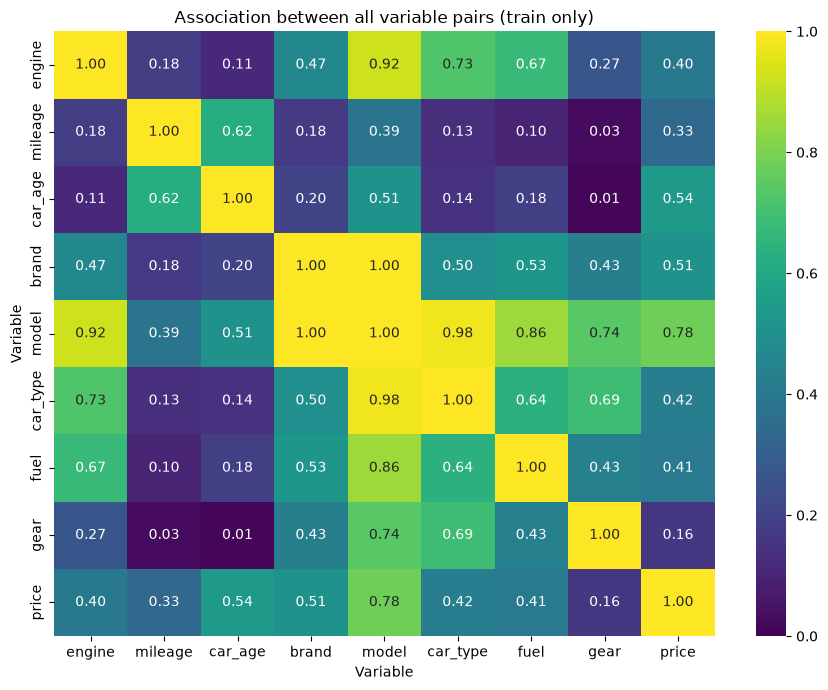

ตารางทั้ง 36 คู่ เรียงจากสัมพันธ์มากที่สุดไปน้อยที่สุด (value 0 = ไม่สัมพันธ์, 1 = สมบูรณ์)


variable 1,variable 2,method,value
brand,model,Cramér's V,1.0000
model,car_type,Cramér's V,0.9801
engine,model,η,0.9222
model,fuel,Cramér's V,0.8555
model,price,η,0.7787
model,gear,Cramér's V,0.7417
engine,car_type,η,0.7254
car_type,gear,Cramér's V,0.6911
engine,fuel,η,0.6743
car_type,fuel,Cramér's V,0.6405


In [16]:
# [16] ความสัมพันธ์ทุกคู่ (heatmap 9x9)
# ==================================================
# ทำอะไร: วัดความสัมพันธ์ของตัวแปรทุกคู่ใน train (9 ตัว = 8 ฟีเจอร์ที่โมเดลใช้ + price
#   ซึ่งเป็นค่าที่จะทำนาย ได้ 36 คู่) แล้วสรุปเป็นตาราง 9x9 (association_matrix)
#   วาดเป็น heatmap (แผนที่สี) และพิมพ์ตาราง 36 คู่เรียงจากสัมพันธ์มากไปน้อย
#   วิธีวัดเลือกตามชนิดของคู่ (อธิบายไว้ที่เซลล์ [15]):
#     ตัวเลข-ตัวเลข   -> |Spearman| (ค่าสัมบูรณ์ ตัดเครื่องหมายทิ้งให้อยู่ช่วง 0..1)
#     หมวดหมู่-หมวดหมู่ -> Cramér's V
#     หมวดหมู่-ตัวเลข  -> η (correlation ratio)
#   เส้นทแยงมุมเป็น 1 เสมอ (ตัวแปรเทียบกับตัวเอง) แต่ละคู่คำนวณครั้งเดียวแล้วเติมทั้ง 2 ฝั่ง
# ทำไม: ก่อนสร้างโมเดล ควรรู้ว่าฟีเจอร์ไหนเกี่ยวข้องกับ price มาก และฟีเจอร์ไหนซ้ำซ้อนกันเอง
#   ใช้ train เท่านั้น เพราะ val และ test ต้องเป็นข้อมูลที่ไม่เคยเห็น
#   ถ้าเอาไปคำนวณด้วย จะเท่ากับแอบดูคำตอบก่อนวัดผล (data leakage)
# ผลที่ควรเห็น: heatmap 9x9 ยิ่งสีสว่าง (ใกล้ 1) ยิ่งสัมพันธ์กันมาก แล้วตาราง 36 คู่
#   วิธีอ่าน:
#     - แถวหรือคอลัมน์ของ price บอกว่าฟีเจอร์ไหนสัมพันธ์กับราคามากที่สุด
#     - คู่ model กับ brand จะใกล้ 1 เป็นเรื่องปกติ เพราะรุ่นหนึ่งสังกัดยี่ห้อเดียว
#       ไม่ใช่ข้อมูลผิดพลาด
#     - ฟีเจอร์สองตัวสัมพันธ์กันสูง ไม่ได้ทำให้ decision tree ทำนายแย่ลง
#       แต่ทำให้บอกยากว่าฟีเจอร์ไหน "สำคัญ" จริง เพราะทั้งคู่ให้ข้อมูลซ้ำกัน
#     - ความสัมพันธ์ไม่ใช่เหตุและผล (association is not causation)
#       เช่น รถอายุมากราคาต่ำ ไม่ได้แปลว่าอายุเป็นตัวกำหนดราคาเพียงอย่างเดียว
# ข้อควรระวัง: ตัววัด 3 ชนิดไม่ได้อยู่บนสเกลเดียวกันเป๊ะ ๆ
#   จึงเทียบค่าข้ามชนิดได้แค่คร่าว ๆ เทียบในชนิดเดียวกันแม่นกว่า
# ==================================================
print("=== [16] ความสัมพันธ์ทุกคู่ (heatmap 9x9) ===")

variables = NUM_COLS + CAT_COLS + ["price"]
numeric_variables = NUM_COLS + ["price"]

association_matrix = pd.DataFrame(np.eye(len(variables)), index=variables, columns=variables)
pair_rows = []
for i in range(len(variables)):
    for j in range(i + 1, len(variables)):
        first = variables[i]
        second = variables[j]
        first_is_numeric = first in numeric_variables
        second_is_numeric = second in numeric_variables
        if first_is_numeric and second_is_numeric:
            method = "Spearman"
            value = abs(train[first].corr(train[second], method="spearman"))
        elif not first_is_numeric and not second_is_numeric:
            method = "Cramér's V"
            value = cramers_v(train[first], train[second])
        elif first_is_numeric:
            method = "η"
            value = correlation_ratio(train[second], train[first])
        else:
            method = "η"
            value = correlation_ratio(train[first], train[second])
        association_matrix.loc[first, second] = value
        association_matrix.loc[second, first] = value
        pair_rows.append(
            {"variable 1": first, "variable 2": second, "method": method, "value": value}
        )

plt.figure(figsize=(9, 7))
sns.heatmap(association_matrix, annot=True, fmt=".2f", vmin=0, vmax=1, cmap="viridis")
plt.title("Association between all variable pairs (train only)")
plt.xlabel("Variable")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

pair_table = pd.DataFrame(pair_rows).sort_values("value", ascending=False)
print("ตารางทั้ง 36 คู่ เรียงจากสัมพันธ์มากที่สุดไปน้อยที่สุด (value 0 = ไม่สัมพันธ์, 1 = สมบูรณ์)")
display(pair_table.style.format({"value": "{:.4f}"}).hide(axis="index"))

=== [17] Spearman ของตัวแปรตัวเลข ===


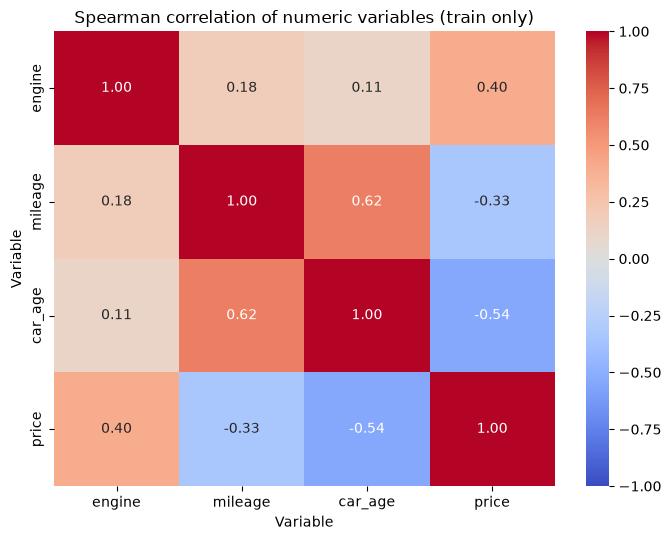

ตาราง Spearman (บวก = ไปทางเดียวกัน, ลบ = สวนทางกัน, ใกล้ 0 = ไม่มีแนวโน้มชัด)


,engine,mileage,car_age,price
engine,1.0000,0.1790,0.1121,0.4044
mileage,0.1790,1.0000,0.6183,-0.3337
car_age,0.1121,0.6183,1.0000,-0.5422
price,0.4044,-0.3337,-0.5422,1.0000


In [17]:
# [17] Spearman ของตัวแปรตัวเลข
# ==================================================
# ทำอะไร: คำนวณ Spearman ของตัวแปรตัวเลข 4 ตัว (engine, mileage, car_age, price) ใน train
#   แล้ววาด heatmap และแสดงตาราง ต่างจากเซลล์ [16] ตรงที่เก็บเครื่องหมายบวก/ลบไว้ (ช่วง -1..1)
# ทำไม: เครื่องหมายบอกทิศทางที่เซลล์ [16] (ใช้ค่าสัมบูรณ์) มองไม่เห็น
#   Spearman คือสหสัมพันธ์ของ "อันดับ" (rank) ของข้อมูล ไม่ใช่ค่าจริง จึงเลือกใช้แทน Pearson เพราะ
#     - ทนต่อค่าผิดปกติ (outlier) เช่น รถราคาสูงมากไม่กี่คัน Pearson จะถูกดึงไปมาก
#     - จับความสัมพันธ์ที่ไม่เป็นเส้นตรงแต่ไปทางเดียวกันได้ (monotonic)
#       เช่น ราคาลดลงเรื่อย ๆ เมื่อเลขไมล์เพิ่ม แม้ไม่ลดเป็นเส้นตรง
# ผลที่ควรเห็น: heatmap สีแดง-น้ำเงิน (coolwarm) พร้อมตัวเลขในช่อง แล้วตารางตัวเลขชุดเดียวกัน
#   วิธีอ่านเครื่องหมาย:
#     - บวก (สีแดง) = สองตัวนี้เพิ่มไปด้วยกัน
#     - ลบ (สีน้ำเงิน) = ตัวหนึ่งเพิ่มขณะที่อีกตัวลด
#     - ใกล้ 0 (สีขาว) = ไม่มีแนวโน้มทางเดียวกันชัดเจน
#   สิ่งที่ควรดู: (1) แถว price ว่าตัวไหนสัมพันธ์กับราคามากและทิศทางใด
#   (2) ฟีเจอร์ตัวเลขสองตัวที่สัมพันธ์กันเองสูง (เช่น car_age กับ mileage มักไปด้วยกัน)
#   ซึ่งหมายความว่าให้ข้อมูลซ้ำกันบางส่วน ควรเทียบกับผลในเซลล์ [16]
# ข้อควรระวัง: สัมพันธ์ไม่ใช่เหตุและผล และใช้ train เท่านั้นเหมือนเซลล์ [16]
# ==================================================
print("=== [17] Spearman ของตัวแปรตัวเลข ===")

spearman_table = train[NUM_COLS + ["price"]].corr(method="spearman")

plt.figure(figsize=(7, 5.5))
sns.heatmap(spearman_table, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm")
plt.title("Spearman correlation of numeric variables (train only)")
plt.xlabel("Variable")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

print("ตาราง Spearman (บวก = ไปทางเดียวกัน, ลบ = สวนทางกัน, ใกล้ 0 = ไม่มีแนวโน้มชัด)")
display(spearman_table.style.format("{:.4f}"))

In [18]:
# [18] รายชื่อฟีเจอร์
# ==================================================
# ทำอะไร: ประกาศตัวแปร features = รายชื่อคอลัมน์ทั้งหมดที่จะป้อนให้โมเดลใช้ทายราคา
#         "ฟีเจอร์ (feature)" คือคอลัมน์ข้อมูลที่โมเดลใช้เป็นเบาะแสในการทาย
#         เช่น ปีรถ เลขไมล์ ยี่ห้อ ส่วน "ราคา" คือคำตอบที่โมเดลต้องทาย จึงไม่นับเป็นฟีเจอร์
#         ในที่นี้ใช้ NUM_COLS (ตัวเลข: engine, mileage, car_age) รวมกับ CAT_COLS
#         (หมวดหมู่: brand, model, car_type, fuel, gear) จากเซลล์ [03] รวม 8 ตัว
# ทำไม: เวอร์ชันนี้ตัดขั้น "คัดเลือกฟีเจอร์" ออกแล้ว ใช้ทุกตัวเลย เหตุผลคือ
#         1) ขั้นคัดเลือกเดิม (วัด CV MAE กับ permutation importance, backward elimination
#            และตรวจคอลัมน์ตัวเลขซ้ำ) เก็บฟีเจอร์ไว้ครบ 8 ตัวอยู่แล้ว และไม่พบคู่คอลัมน์ซ้ำ
#            การตัดขั้นนี้จึงได้ชุดฟีเจอร์เหมือนเดิม แต่ไม่ต้องฝึกโมเดลซ้ำหลายรอบ ประหยัดเวลารัน
#         2) การไม่คัดเลือก ไม่ได้พิสูจน์ว่าทุกฟีเจอร์ช่วยเสมอ ต้นไม้ตัดสินใจอาจเลือกใช้
#            ฟีเจอร์ที่ไม่มีประโยชน์เพราะความบังเอิญในข้อมูล ทำให้ทายข้อมูลใหม่แย่ลงได้
#            (เรียกว่า generalisation แย่ลง) แม้เราจะคุมขนาดต้นไม้ด้วย max_depth,
#            min_samples_leaf และ ccp_alpha อยู่แล้วก็ตาม
# ผลที่ควรเห็น: บรรทัดบอกจำนวนฟีเจอร์ และรายชื่อฟีเจอร์ทั้งหมด
#               คอลัมน์ตัวเลขมาก่อน แล้วตามด้วยหมวดหมู่
# ข้อควรระวัง: กติกานี้ต่างจากโมเดลอื่นในโปรเจกต์ที่ยังมีขั้นคัดเลือกฟีเจอร์อยู่
#              ต้องคำนึงถึงความต่างนี้ตอนเปรียบเทียบผลระหว่างโมเดล
# ==================================================
print("=== [18] รายชื่อฟีเจอร์ ===")

features = NUM_COLS + CAT_COLS

print(f"จำนวนฟีเจอร์ : {len(features)}")
print(f"รายชื่อ      : {features}")

=== [18] รายชื่อฟีเจอร์ ===
จำนวนฟีเจอร์ : 8
รายชื่อ      : ['engine', 'mileage', 'car_age', 'brand', 'model', 'car_type', 'fuel', 'gear']


In [19]:
# [19] คลาส FoldOneHot
# ==================================================
# ทำอะไร: สร้างตัวแปลงข้อมูล (คลาส FoldOneHot) ที่เปลี่ยนคอลัมน์หมวดหมู่ให้เป็นตัวเลข 0/1
#         ด้วยวิธี one-hot encoding แล้วต่อกับคอลัมน์ตัวเลขเดิม
#
#         one-hot คืออะไร: โมเดลต้นไม้ในที่นี้อ่านได้แต่ตัวเลข แต่ fuel เป็นข้อความ
#         เราจึงแตกเป็นคอลัมน์ใหม่ที่ตอบแค่ "ใช่ (1) หรือ ไม่ใช่ (0)" ต่อหนึ่งค่า
#         ตัวอย่าง fuel มี 3 ค่า Benzine / Diesel / Hybrid จะได้ 2 คอลัมน์:
#                          fuel=Diesel   fuel=Hybrid
#             รถดีเซล:          1             0
#             รถไฮบริด:        0             1
#             รถเบนซิน:        0             0      <- ศูนย์ทั้งคู่ = ค่าอ้างอิง
#
# ทำไม:
#   - ทิ้ง 1 ค่า (ระดับอ้างอิง หรือ reference level): ค่าที่เจอบ่อยที่สุดในข้อมูลฝึกจะไม่มีคอลัมน์
#     ของตัวเอง เพราะรู้ได้จากการที่คอลัมน์อื่นเป็น 0 หมด ถ้าเก็บครบทุกค่า คอลัมน์จะซ้ำซ้อนกัน
#     ถ้าความถี่เท่ากัน จะเรียงตามชื่อระดับจากน้อยไปมาก เพื่อให้ผลเหมือนเดิมทุกครั้ง
#   - เรียนรู้ (fit) ใน "แต่ละ fold": fold คือการแบ่งข้อมูลฝึกเป็นส่วนย่อย ๆ เพื่อสลับกันเป็น
#     ชุดฝึกและชุดตรวจ (cross-validation) รายชื่อระดับของแต่ละ fold จึงมาจากแถวฝึกของ fold นั้นเท่านั้น
#     ไม่แอบดูแถวที่ใช้ตรวจ ข้อมูลจึงไม่รั่ว (information leak) ผล CV จึงเชื่อถือได้
#   - ระดับที่ไม่เคยเจอตอนฝึก (unseen level) จะได้ศูนย์ทุกคอลัมน์ ไม่ทำให้โปรแกรมพัง
#   - __init__ ต้องเก็บ argument ทั้งสองตัวไว้ตามเดิมโดยไม่แก้ เพราะ sklearn ต้องสร้างสำเนาของ
#     ตัวแปลง (clone) ในทุก fold โดยอ่านค่าเหล่านี้กลับไป
#   - ในเมธอด transform ใช้การเทียบแบบ broadcasting: ดึงค่าของคอลัมน์ออกมาเป็นแนวตั้ง
#     (values[:, None]) แล้วเทียบ "ทุกแถวกับทุกระดับพร้อมกัน" ในคำสั่งเดียว
#     ได้ตารางจริง/เท็จขนาด (จำนวนแถว x จำนวนระดับ) แล้วแปลงเป็น 1/0
#     วิธีนี้เร็วกว่าวนทีละระดับมาก ซึ่งสำคัญเพราะการค้นหา ccp_alpha และ grid search ต้องเรียกใช้หลายพันครั้ง
# ผลที่ควรเห็น: ข้อความสั้น ๆ ว่าสร้างคลาสแล้ว ยังไม่มีการแปลงข้อมูลในเซลล์นี้
#               เซลล์ที่เรียกใช้จริงคือ [23]-[25] และ pipeline ใน [29]
# ข้อควรระวัง: ผู้เรียกใช้เขียน FoldOneHot(NUM_COLS, CAT_COLS)
# ==================================================
print("=== [19] คลาส FoldOneHot ===")


class FoldOneHot(TransformerMixin, BaseEstimator):
    """one-hot ที่เรียนรู้ระดับจากแถวที่ fit เท่านั้น (ไม่แอบดูแถวตรวจ)"""

    def __init__(self, numeric_columns, categorical_columns):
        # เก็บไว้ตามเดิมโดยไม่แก้ เพื่อให้ sklearn clone ได้
        self.numeric_columns = numeric_columns
        self.categorical_columns = categorical_columns

    def fit(self, X, y=None):
        """จำรายชื่อคอลัมน์ และระดับ (ไม่รวมระดับอ้างอิง) ของแต่ละคอลัมน์หมวดหมู่"""
        self.numeric_ = [c for c in X.columns if c in self.numeric_columns]
        self.categorical_ = [c for c in X.columns if c in self.categorical_columns]
        self.levels_ = {}
        for col in self.categorical_:
            counts = X[col].value_counts()
            # เรียงชื่อก่อน แล้วเรียงตามความถี่แบบ stable ชื่อจึงตัดสินเมื่อความถี่เท่ากัน
            ordered = counts.sort_index().sort_values(ascending=False, kind="stable")
            self.levels_[col] = list(ordered.index[1:])  # ตัดระดับที่พบบ่อยที่สุด = ระดับอ้างอิง
        return self

    def transform(self, X):
        """แปลงด้วยระดับที่จำไว้ตอน fit (ไม่เรียนรู้เพิ่ม)"""
        parts = [X[self.numeric_].astype(float)]
        for col in self.categorical_:
            levels = self.levels_[col]
            values = X[col].to_numpy(dtype=object)
            # เทียบทุกแถวกับทุกระดับพร้อมกัน ได้ตาราง True/False ระดับที่ไม่เคยเจอจะเป็น False หมด
            matches = values[:, None] == np.asarray(levels, dtype=object)
            dummies = pd.DataFrame(
                matches.astype(float),
                index=X.index,
                columns=[f"{col}={level}" for level in levels],
            )
            parts.append(dummies)
        return pd.concat(parts, axis=1)

    def get_feature_names_out(self, input_features=None):
        """รายชื่อคอลัมน์ผลลัพธ์ตามลำดับเดียวกับ transform"""
        names = list(self.numeric_)
        for col in self.categorical_:
            names += [f"{col}={level}" for level in self.levels_[col]]
        return np.asarray(names, dtype=object)


print("สร้างคลาส FoldOneHot แล้ว")

=== [19] คลาส FoldOneHot ===
สร้างคลาส FoldOneHot แล้ว


In [20]:
# [20] ฟังก์ชัน make_model
# ==================================================
# ทำอะไร: สร้างฟังก์ชัน make_model() ที่คืนต้นไม้ตัดสินใจ (DecisionTreeRegressor) ตัวใหม่
#         พร้อมค่า hyperparameter ครบทั้ง 12 ตัว
#         hyperparameter = ค่าที่เราต้องตั้งเองก่อนให้โมเดลเรียน (โมเดลไม่ได้เรียนรู้ค่าพวกนี้จากข้อมูล)
#         เช่น ความลึกสูงสุดของต้นไม้ ส่วนสิ่งที่โมเดลเรียนเองจากข้อมูลคือเงื่อนไขแตกกิ่งในต้นไม้
# ทำไม:
#   - เขียนครบทั้ง 12 ตัว พร้อมคอมเมนต์ทุกตัว ไม่ว่าจะปรับใน grid หรือไม่ เพราะผู้ใช้ต้องการ
#     เห็นทุกค่าที่โมเดลใช้จริง ไม่ต้องไปเปิดเอกสารดูค่าเริ่มต้นเอง
#   - ตัวที่มีป้าย [grid] (max_depth, min_samples_leaf, ccp_alpha) จะถูก GridSearchCV
#     เขียนทับด้วยค่าใน PARAM_GRID ตัวอื่นใช้ค่าตามที่เขียนในฟังก์ชัน
#     random_state=SEED ทำให้ผลซ้ำได้
#   - grid ปรับแค่ 3 ตัว เพราะจำกัดขอบเขตงาน และคุมเวลารัน: ยิ่งปรับหลายพารามิเตอร์
#     จำนวนชุดใน grid ยิ่งเพิ่มแบบคูณกัน
#   - ยังไม่ได้ทดสอบ max_features, criterion="absolute_error", max_leaf_nodes,
#     min_samples_split, min_impurity_decrease จึงสรุปไม่ได้ว่าทางเลือกเหล่านี้ไม่ช่วย
#     max_features ใช้กับต้นไม้ต้นเดียวได้ ส่วนตัวควบคุมขนาดต้นไม้ตัวอื่นให้ผลต่างกัน
#     และไม่ได้ซ้ำซ้อนกันอย่างเคร่งครัด
# ผลที่ควรเห็น: ข้อความสั้น ๆ ว่าสร้างฟังก์ชันแล้ว ยังไม่ฝึกโมเดลในเซลล์นี้
# ข้อควรระวัง: make_model() ไม่รับ argument (ของเก่ารับ threads แต่ไม่เคยใช้ จึงตัดออก)
# ==================================================
print("=== [20] ฟังก์ชัน make_model ===")


def make_model():
    """สร้าง DecisionTreeRegressor ใหม่พร้อม hyperparameter ครบ 12 ตัว"""
    return DecisionTreeRegressor(
        criterion="squared_error",  # วัดคุณภาพการแตกกิ่งด้วย MSE (ค่าเริ่มต้น เหมาะกับการทายราคา)
        splitter="best",  # ลองทุกจุดตัดแล้วเลือกจุดที่ดีที่สุด ไม่สุ่ม
        max_depth=None,  # [grid] ความลึกสูงสุด None = ไม่จำกัด
        min_samples_split=2,  # รถขั้นต่ำในโหนดก่อนแตกกิ่ง (ค่าเริ่มต้น ยังไม่ได้ทดสอบการปรับ)
        min_samples_leaf=1,  # [grid] รถขั้นต่ำต่อใบ
        min_weight_fraction_leaf=0.0,  # สัดส่วนน้ำหนักขั้นต่ำต่อใบ 0 = ไม่ใช้ (ทุกแถวน้ำหนักเท่ากัน)
        max_features=None,  # ทุกการแตกกิ่งเห็นตัวแปรครบ (ใช้กับต้นไม้ต้นเดียวได้ แต่ยังไม่ได้ทดสอบ)
        random_state=SEED,  # เลขสุ่มคงที่ ใช้ตัดสินกรณีจุดตัดดีเท่ากัน ให้ผลซ้ำได้
        max_leaf_nodes=None,  # จำนวนใบสูงสุด None = ไม่จำกัด (ยังไม่ได้ทดสอบขีดจำกัดนี้)
        min_impurity_decrease=0.0,  # แตกกิ่งได้แม้ลด error น้อย (ยังไม่ได้ทดสอบเกณฑ์นี้)
        ccp_alpha=0.0,  # [grid] ค่าตัดกิ่งหลังโตเสร็จ (เลือกจาก pruning path ด้วย CV ในเซลล์ [22]-[27])
        monotonic_cst=None,  # ไม่บังคับทิศทางความสัมพันธ์ของตัวแปรกับราคา
    )


print("สร้างฟังก์ชัน make_model แล้ว")

=== [20] ฟังก์ชัน make_model ===
สร้างฟังก์ชัน make_model แล้ว


In [21]:
# [21] PARAM_GRID ตั้งต้น
# ==================================================
# ทำอะไร: กำหนด PARAM_GRID = ตารางค่าที่ grid search จะลองครบทุกคู่
#         grid search = วิธีค้นหาค่า hyperparameter ที่ดี โดยลองทุกชุดผสมของค่าที่เราเตรียมไว้
#         ฝึกและวัดผลด้วย cross-validation ทีละชุด แล้วเลือกชุดที่ CV MAE เฉลี่ยต่ำสุด
#         ตอนนี้มี 2 พารามิเตอร์ (max_depth 5 ค่า x min_samples_leaf 6 ค่า = 30 คู่)
#         ส่วน ccp_alpha จะถูกเลือกจาก pruning path ของแต่ละคู่ในเซลล์ [23]-[27]
#         แล้วนำค่าที่ดีที่สุดของแต่ละคู่ใส่ใน grid search ในเซลล์ [30]
# ทำไม: ขยาย grid จากต้นฉบับ
#
#   | พารามิเตอร์      | ต้นฉบับ            | ตอนนี้                                    |
#   |------------------|--------------------|--------------------------------------------|
#   | max_depth        | 20, None           | 10, 15, 20, 25, None                       |
#   | min_samples_leaf | 1, 5, 10           | 1, 5, 7, 9, 12, 15                         |
#   | ccp_alpha        | 0, 1e6, 3e6, 1e7   | ทุก alpha บน pruning path ของแต่ละคู่ (CV)  |
#
#   เหตุผลของแต่ละ grid
#   - max_depth และ min_samples_leaf (5-15): ใช้ค่าตามที่ผู้ใช้กำหนด
#     (max_depth = ความลึกสูงสุดของต้นไม้ None = ไม่จำกัด,
#      min_samples_leaf = จำนวนรถขั้นต่ำต่อใบ ค่ามากทำให้ต้นไม้เล็กลง)
#   - min_samples_leaf=1: เพิ่มตามคำแนะนำ เพราะรอบเดิมชนะที่ค่านี้
#   - ccp_alpha: ใช้วิธีมาตรฐานของ CART คือสร้าง pruning path ของแต่ละคู่บน train
#     แล้วลองทุก alpha ของ path ด้วย 5-fold CV (เซลล์ [22]-[27]) จึงไม่มีค่าคงที่
#     หรือกฎจำกัดจำนวน alpha ใน PARAM_GRID อีก
# ผลที่ควรเห็น: แสดง grid ปัจจุบัน และจำนวนคู่ที่ผสมได้ (30 คู่)
# ข้อควรระวัง:
#   - ผู้ชนะคือชุดที่ CV MAE เฉลี่ยต่ำสุด ถ้า CV MAE เท่ากันให้คู่ที่มาก่อนตามลำดับ grid
#     แล้วจึง alpha ที่เล็กกว่า (ลำดับของ np.argmin บนตารางที่เรียงตามคู่แล้วตาม alpha)
#   - รายการ alpha ของแต่ละคู่มาจากต้นไม้ที่ฝึกบน train ทั้งชุด จึงอาจทำให้ CV MAE
#     ดีเกินจริงเล็กน้อย (อธิบายไว้ในเซลล์ [33])
# ==================================================
print("=== [21] PARAM_GRID ตั้งต้น ===")

PARAM_GRID = {
    "max_depth": [10, 15, 20, 25, None],
    "min_samples_leaf": [1, 5, 7, 9, 12, 15],
}

combinations = 1
for values in PARAM_GRID.values():
    combinations = combinations * len(values)

print(f"PARAM_GRID ตอนนี้       : {PARAM_GRID}")
print(f"จำนวนคู่ที่ผสมได้ตอนนี้ : {combinations} (ccp_alpha จะเลือกในเซลล์ [27])")


=== [21] PARAM_GRID ตั้งต้น ===
PARAM_GRID ตอนนี้       : {'max_depth': [10, 15, 20, 25, None], 'min_samples_leaf': [1, 5, 7, 9, 12, 15]}
จำนวนคู่ที่ผสมได้ตอนนี้ : 30 (ccp_alpha จะเลือกในเซลล์ [27])


In [22]:
# [22] ccp 1: ฟังก์ชัน alpha_candidates และ all_alpha_scores
# ==================================================
# ทำอะไร: สร้างฟังก์ชัน 2 ตัวที่ใช้เลือก ccp_alpha แบบ CART
#   1) alpha_candidates(path_alphas) คืนรายการ alpha ที่จะลองของต้นไม้หนึ่งต้น คือ
#      0.0, ค่ากลางแบบเรขาคณิต sqrt(a_k * a_(k+1)) ของ alpha บวกที่ติดกันทุกคู่
#      และ alpha บวกตัวสุดท้าย (ต้นไม้ที่เหลือรากเดียว) เรียงจากน้อยไปมาก ไม่ซ้ำ
#      ตัวอย่าง: [0, 4, 1, 1, 9] -> [0, 2, 6, 9], [0] -> [0], [0, 5] -> [0, 5]
#   2) all_alpha_scores(fitted_tree, X, y, alphas) คืน dict ที่มี key "MAE", "RMSE", "MAPE",
#      "R2", "leaves" แต่ละ value เป็น array ยาวเท่า alphas คือคะแนนของต้นไม้ที่ตัดกิ่ง
#      ด้วย alpha นั้น โดยไม่ต้องฝึกต้นไม้ใหม่ (คำนวณจาก fitted_tree ต้นเดียว)
#      ค่าที่ได้เท่ากับการฝึก DecisionTreeRegressor ใหม่ด้วย ccp_alpha = alpha บนแถวเดียวกัน
#
# ทำไม:
#   - วิธีมาตรฐานของ CART (Breiman, Friedman, Olshen & Stone, 1984) คือสร้าง pruning path
#     ของต้นไม้เต็มที่ก่อน แล้วลองทุก alpha บน path ด้วย cross-validation ถ้าฝึกต้นไม้ใหม่
#     ทุก (คู่พารามิเตอร์ x alpha x fold) จะช้ามาก เพราะ alpha มีได้หลายพันค่าต่อคู่
#   - ค่ากลางแบบเรขาคณิตเป็นธรรมเนียมเดียวกับ CART และ R rpart: มันอยู่ระหว่าง alpha
#     สองค่าที่ติดกันเสมอ จึงไม่ชนกับจุดตัดพอดี (ที่ alpha เท่ากับค่าใน path การเทียบ <= กำกวม)
#     0 คือไม่ตัดกิ่ง (sklearn ตัดกิ่งเฉพาะเมื่อ ccp_alpha > 0)
#
# วิธีคำนวณ (ตรงกับ sklearn/tree/_tree.pyx ฟังก์ชัน _cost_complexity_prune):
#   - R(t) = impurity(t) * weighted_n_node_samples(t) / weighted_n_node_samples(0)
#   - R(T_t) = ผลรวม R ของใบทุกใบในกิ่ง t, L(t) = จำนวนใบในกิ่ง t
#   - alpha ที่ทำให้กิ่ง t ถูกตัด = (R(t) - R(T_t)) / (L(t) - 1) เรียก c(t)
#   - ตัดกิ่งที่ c น้อยที่สุดซ้ำ ๆ (heap) แล้วอัปเดต c ของบรรพบุรุษ ค่า c ไม่ลดลงเมื่อเข้าใกล้ราก
#     ลำดับและเศษทศนิยมตรงกับ sklearn: เริ่มจากผลรวม R(T_t) ที่บวกจากใบขึ้นไปตามลำดับ
#     leaf index และเลือก c น้อยสุดโดย tie-break ด้วย index น้อยสุด
#   - ต้นไม้ที่ alpha หนึ่ง ๆ คือต้นไม้ที่โหนดซึ่ง c <= alpha ถูกยุบเป็นใบ โหนดที่ทำนายแถวหนึ่ง ๆ
#     คือโหนดลึกสุดบนเส้นทางของแถวนั้นที่ c <= alpha (ใบเดิมของ fitted_tree นับเป็น c = 0)
#     ช่วง alpha ที่โหนด v ทำนายจึงเป็น [c(v), c(พ่อของ v)) และรากใช้ [c(ราก), อนันต์)
#   - ไล่ decision_path(X) ทีละแถว แล้วสะสมผลต่าง (difference array) ด้วย searchsorted
#     รวมทุกแถวในครั้งเดียว ต้นไม้ ~20,000 โหนด 7,500 แถว 10,000 alpha ใช้เวลาไม่ถึง 30 วินาที
#     (ทดสอบกับต้นไม้ 60,000 โหนด 28,528 alpha แล้วใช้ราว 5 วินาที)
#
# ผลที่ควรเห็น: ข้อความว่าสร้างฟังก์ชันแล้ว และข้อความว่าการทดสอบกับข้อมูลจำลองผ่าน
#   (ทดสอบเทียบค่าที่คำนวณได้กับ DecisionTreeRegressor ที่ฝึกใหม่จริงทุกค่า alpha)
# ข้อควรระวัง:
#   - ฟังก์ชันไม่แก้ fitted_tree (คัดลอก children_left / children_right ออกมาก่อน)
#   - alphas ต้องเรียงจากน้อยไปมากและไม่ติดลบ แต่ไม่จำเป็นต้องมาจากต้นไม้ต้นเดียวกัน
#     (ใช้ alpha จากต้นไม้ที่ฝึกบน train ทั้งชุดกับต้นไม้ของ fold ได้)
#   - R2 ใช้ SST ของ y ที่ส่งเข้ามา (แถวเดียวกับที่ทำนาย) ตามนิยามของ r2_score
# ==================================================
print("=== [22] ccp 1: ฟังก์ชัน alpha_candidates และ all_alpha_scores ===")

_TREE_LEAF = -1  # ค่า children_left / children_right ของใบใน sklearn


def alpha_candidates(path_alphas):
    """0, ค่ากลางแบบเรขาคณิตของ alpha บวกที่ติดกัน, และ alpha บวกตัวสุดท้าย"""
    values = np.asarray(path_alphas, dtype=float).ravel()
    positive = np.unique(values[(values > 0) & np.isfinite(values)])
    if positive.size == 0:
        return np.array([0.0])
    if positive.size == 1:
        return np.array([0.0, positive[0]])
    middle = np.sqrt(positive[:-1] * positive[1:])
    return np.concatenate(([0.0], middle, [positive[-1]]))


def all_alpha_scores(fitted_tree, X, y, alphas):
    """คะแนนของต้นไม้ที่ตัดกิ่งด้วย alpha แต่ละค่า โดยไม่ฝึกต้นไม้ใหม่"""
    alphas = np.asarray(alphas, dtype=float).ravel()
    if alphas.size and (alphas.min() < 0 or np.any(np.diff(alphas) < 0)):
        raise ValueError("alphas ต้องเรียงจากน้อยไปมากและไม่ติดลบ")
    y = np.asarray(y, dtype=float).ravel()
    t = fitted_tree.tree_
    n_nodes = t.node_count
    # คัดลอกก่อน กันเผลอแก้ tree_ ของ fitted_tree (array ของ tree_ เป็น view)
    left = t.children_left.copy()
    right = t.children_right.copy()
    is_leaf = left == _TREE_LEAF

    parent = np.full(n_nodes, -1, dtype=np.intp)
    internal = np.flatnonzero(~is_leaf)
    parent[left[internal]] = internal
    parent[right[internal]] = internal

    # R(t) และผลรวม R ของใบในกิ่ง (บวกจากใบขึ้นไปตามลำดับ leaf index เหมือน sklearn)
    r_node = (t.weighted_n_node_samples * t.impurity
              / t.weighted_n_node_samples[0]).astype(float)
    r_branch = np.zeros(n_nodes, dtype=float)
    n_leaves = np.zeros(n_nodes, dtype=np.intp)
    for leaf in np.flatnonzero(is_leaf):
        leaf = int(leaf)
        r_branch[leaf] = r_node[leaf]
        current = r_node[leaf]
        node = leaf
        while node != 0:
            node = int(parent[node])
            r_branch[node] += current
            n_leaves[node] += 1

    # ตัดกิ่งทีละกิ่ง: collapse(node) = alpha ที่กิ่งนั้นถูกตัด (heap ของ (c, index))
    collapse = np.full(n_nodes, np.inf)
    candidate = ~is_leaf.copy()
    version = np.zeros(n_nodes, dtype=np.int64)
    heap = []
    for node in np.flatnonzero(candidate):
        value = (r_node[node] - r_branch[node]) / (n_leaves[node] - 1)
        heap.append((value, int(node), 0))
    heapq.heapify(heap)
    while candidate[0]:
        value, node, stamp = heapq.heappop(heap)
        if not candidate[node] or stamp != version[node]:
            continue  # รายการเก่าใน heap ใช้ไม่ได้แล้ว
        collapse[node] = value
        candidate[node] = False
        # ยุบลูกหลานที่ยังเหลืออยู่ด้วย (เกิดเมื่อ c เท่ากันเป๊ะ)
        stack = [node]
        while stack:
            current = stack.pop()
            if current != node:
                if not candidate[current]:
                    continue
                collapse[current] = value
                candidate[current] = False
            if left[current] != _TREE_LEAF:
                stack.append(int(left[current]))
                stack.append(int(right[current]))
        # อัปเดตจำนวนใบและผลรวม R ของบรรพบุรุษ แล้วใส่ c ใหม่ลง heap
        removed = n_leaves[node] - 1
        n_leaves[node] = 0
        difference = r_node[node] - r_branch[node]
        r_branch[node] = r_node[node]
        ancestor = int(parent[node])
        while ancestor != -1:
            n_leaves[ancestor] -= removed
            r_branch[ancestor] += difference
            if candidate[ancestor]:
                version[ancestor] += 1
                value = ((r_node[ancestor] - r_branch[ancestor])
                         / (n_leaves[ancestor] - 1))
                heapq.heappush(heap, (value, ancestor, int(version[ancestor])))
            ancestor = int(parent[ancestor])

    # ช่วง alpha ที่แต่ละโหนดทำนาย: [lo, hi)
    value = t.value[:, 0, 0]
    lo_node = np.where(is_leaf, 0.0, collapse)
    hi_node = np.where(np.arange(n_nodes) == 0, np.inf, collapse[parent])

    path = fitted_tree.decision_path(X)
    rows = np.repeat(np.arange(path.shape[0]), np.diff(path.indptr))
    nodes = path.indices
    n_alphas = alphas.size
    error = y[rows] - value[nodes]
    absolute = np.abs(error)
    squared = error * error
    percentage = absolute / np.maximum(np.abs(y[rows]), np.finfo(np.float64).eps)
    lo_index = np.searchsorted(alphas, lo_node[nodes], side="left")
    hi_index = np.searchsorted(alphas, hi_node[nodes], side="left")

    def cumulative(weights):
        """ผลรวมของ weights ต่อหนึ่ง alpha จาก difference array"""
        difference = (np.bincount(lo_index, weights=weights, minlength=n_alphas + 1)
                      - np.bincount(hi_index, weights=weights, minlength=n_alphas + 1))
        return np.cumsum(difference)[:n_alphas]

    absolute_sum = cumulative(absolute)
    sse = cumulative(squared)
    percentage_sum = cumulative(percentage)
    n_rows = len(y)
    sst = float(np.sum((y - y.mean()) ** 2))
    if sst > 0:
        r2 = 1.0 - sse / sst
    else:
        r2 = np.where(sse == 0, 1.0, 0.0)

    # จำนวนใบที่ alpha แต่ละค่า: โหนดที่ยังไม่ถูกยุบและพ่อถูกยุบแล้ว (รากนับเป็นใบเมื่อถูกยุบ)
    leaf_counts = (
        np.bincount(np.searchsorted(alphas, lo_node, side="left"), minlength=n_alphas + 1)
        - np.bincount(np.searchsorted(alphas, hi_node, side="left"), minlength=n_alphas + 1)
    )
    return {
        "MAE": absolute_sum / n_rows,
        "RMSE": np.sqrt(sse / n_rows),
        "MAPE": percentage_sum / n_rows,
        "R2": r2,
        "leaves": np.cumsum(leaf_counts)[:n_alphas].astype(int),
    }


# --- ทดสอบด้วยข้อมูลจำลอง (ไม่แตะข้อมูลจริงของโน้ตบุ๊ค) ---
assert np.array_equal(alpha_candidates([0, 4, 1, 1, 9]), [0.0, 2.0, 6.0, 9.0])
assert np.array_equal(alpha_candidates([0]), [0.0])
assert np.array_equal(alpha_candidates([0, 5]), [0.0, 5.0])

_selftest_rng = np.random.default_rng(0)
_selftest_X = _selftest_rng.normal(size=(400, 4))
_selftest_y = (3 * _selftest_X[:, 0] - 2 * _selftest_X[:, 1] ** 2
               + _selftest_X[:, 2] * _selftest_X[:, 3]
               + _selftest_rng.normal(size=400) * 0.5)
for _depth, _leaf in [(None, 1), (6, 5)]:
    _tree = DecisionTreeRegressor(random_state=0, max_depth=_depth, min_samples_leaf=_leaf)
    _tree.fit(_selftest_X, _selftest_y)
    _alphas = alpha_candidates(_tree.cost_complexity_pruning_path(_selftest_X, _selftest_y).ccp_alphas)
    _keep = np.unique(np.linspace(0, len(_alphas) - 1, min(len(_alphas), 12)).astype(int))
    _alphas = _alphas[_keep]
    _scores = all_alpha_scores(_tree, _selftest_X, _selftest_y, _alphas)
    assert _scores["leaves"][0] == _tree.get_n_leaves(), "alpha = 0 ต้องไม่ตัดกิ่ง"
    for _k, _alpha in enumerate(_alphas):
        _refit = DecisionTreeRegressor(random_state=0, max_depth=_depth,
                                       min_samples_leaf=_leaf, ccp_alpha=float(_alpha))
        _refit.fit(_selftest_X, _selftest_y)
        _predicted = _refit.predict(_selftest_X)
        assert _scores["leaves"][_k] == _refit.get_n_leaves()
        assert np.isclose(_scores["MAE"][_k], mean_absolute_error(_selftest_y, _predicted),
                          rtol=1e-9, atol=1e-9)
        assert np.isclose(_scores["RMSE"][_k], mean_squared_error(_selftest_y, _predicted) ** 0.5,
                          rtol=1e-9, atol=1e-9)
        assert np.isclose(_scores["MAPE"][_k],
                          mean_absolute_percentage_error(_selftest_y, _predicted),
                          rtol=1e-9, atol=1e-9)
        assert np.isclose(_scores["R2"][_k], r2_score(_selftest_y, _predicted),
                          rtol=1e-9, atol=1e-9)
print("ทดสอบ alpha_candidates และ all_alpha_scores กับ sklearn ที่ฝึกใหม่จริงแล้ว ผ่านทั้งหมด")


=== [22] ccp 1: ฟังก์ชัน alpha_candidates และ all_alpha_scores ===


ทดสอบ alpha_candidates และ all_alpha_scores กับ sklearn ที่ฝึกใหม่จริงแล้ว ผ่านทั้งหมด


In [23]:
# [23] ccp 2: pruning path จาก train และ candidate alpha ของทุกคู่ grid
# ==================================================
# ทำอะไร: ฝึกต้นไม้เต็มที่ (ccp_alpha = 0) บน train ทั้งชุดสำหรับทุกคู่
#         (max_depth, min_samples_leaf) ใน PARAM_GRID ตามลำดับของ sklearn ParameterGrid
#         เก็บ pruning path ของแต่ละคู่ แล้วแปลงเป็นรายการ alpha ที่จะลองด้วย
#         alpha_candidates จากเซลล์ [22] ไว้ใน pair_alphas
# ทำไม:
#   - pruning path ต้องมาจากต้นไม้ที่ฝึกแล้วเท่านั้น จะเดา alpha เองไม่ได้ เพราะขนาดของ alpha
#     ขึ้นกับข้อมูลและหน่วยของราคา (บาท)
#   - ใช้ FoldOneHot ที่ fit บน train ทั้งชุด เพื่อให้ pruning path ของทุกคู่เห็นคอลัมน์ชุดเดียวกัน
#     ขั้นนี้ใช้แค่สร้างรายการ alpha ยังไม่ให้คะแนนอะไร ข้อมูลจึงไม่รั่วเข้า validation / test
#   - เรียงคู่ตาม ParameterGrid เพื่อให้ index ของคู่ตรงกับลำดับที่ใช้ตัดสินเมื่อ CV MAE เท่ากัน
#     (คู่ที่มาก่อนใน grid ชนะ)
# ผลที่ควรเห็น: ตารางหนึ่งแถวต่อคู่ (30 แถว): จำนวนโหนด จำนวนใบ และจำนวน alpha ที่จะลอง
#   ต้นไม้ที่ลึกไม่จำกัดและ min_samples_leaf=1 จะมี alpha มากที่สุด
# ข้อควรระวัง: alpha ของแต่ละคู่มาจากต้นไม้ที่ฝึกบน train ทั้งชุด แต่ตอนวัด CV ใช้กับต้นไม้
#   ที่ฝึกบน 4/5 ของ train (fold) ตามธรรมเนียม CART ค่า alpha จึงไม่ได้เป็น path ของ fold เป๊ะ ๆ
#   แต่ยังเป็นค่าปรับต่อใบที่มีความหมายเดียวกันและครอบช่วงกว้างพอ
# ==================================================
print("=== [23] ccp 2: pruning path จาก train และ candidate alpha ของทุกคู่ grid ===")

encoded_train = FoldOneHot(NUM_COLS, CAT_COLS).fit_transform(train[features])
train_prices = train["price"].to_numpy()  # ราคาเป็นบาท ไม่แปลง log
pairs = list(ParameterGrid({"max_depth": PARAM_GRID["max_depth"],
                            "min_samples_leaf": PARAM_GRID["min_samples_leaf"]}))

pair_alphas = []
path_rows = []
for pair in pairs:
    tree = make_model().set_params(**pair)  # ccp_alpha ยังเป็น 0 = ต้นไม้เต็มที่
    tree.fit(encoded_train, train_prices)
    path = tree.cost_complexity_pruning_path(encoded_train, train_prices)
    candidates = alpha_candidates(path.ccp_alphas)
    pair_alphas.append(candidates)
    path_rows.append({
        "max_depth": pair["max_depth"],
        "min_samples_leaf": pair["min_samples_leaf"],
        "nodes": int(tree.tree_.node_count),
        "leaves": int(tree.get_n_leaves()),
        "alphas": len(candidates),
    })
path_table = pd.DataFrame(path_rows)

print(f"จำนวนคู่ (max_depth x min_samples_leaf) : {len(pairs)}")
print(f"จำนวน alpha ที่จะลองรวมทุกคู่           : {sum(len(a) for a in pair_alphas):,}")
display(path_table.style.format({
    "nodes": "{:,.0f}", "leaves": "{:,.0f}", "alphas": "{:,.0f}",
}).hide(axis="index"))


=== [23] ccp 2: pruning path จาก train และ candidate alpha ของทุกคู่ grid ===


จำนวนคู่ (max_depth x min_samples_leaf) : 30
จำนวน alpha ที่จะลองรวมทุกคู่           : 87,088


max_depth,min_samples_leaf,nodes,leaves,alphas
10.000000,1,"1,569",785,687
10.000000,5,"1,137",569,527
10.000000,7,"1,077",539,499
10.000000,9,971,486,448
10.000000,12,879,440,409
10.000000,15,785,393,364
15.000000,1,"11,089","5,545","3,930"
15.000000,5,"4,897","2,449","2,061"
15.000000,7,"4,019","2,010","1,734"
15.000000,9,"3,421","1,711","1,495"


In [24]:
# [24] ccp 3: ฟังก์ชันให้คะแนนหนึ่งคู่ x หนึ่ง fold
# ==================================================
# ทำอะไร: สร้างฟังก์ชัน score_pair_fold ที่รับคู่พารามิเตอร์ รายการ alpha ของคู่นั้น
#         และแถวของ fold หนึ่ง แล้วคืนคะแนนของทุก alpha บนแถวฝึกและแถวตรวจของ fold
#         (MAE, RMSE, MAPE, R2, จำนวนใบ) ด้วย all_alpha_scores จากเซลล์ [22]
#         ฟังก์ชันนี้ถูกเรียกใน worker process ของ joblib ในเซลล์ [25]
# ทำไม:
#   - ต้อง fit FoldOneHot ใหม่ภายใน fold นี้เท่านั้น (จากแถวฝึกของ fold) ระดับของตัวแปรกลุ่ม
#     จึงไม่รั่วจากแถวตรวจเข้าไปใน encoder
#   - ต้นไม้ของ fold ฝึกด้วย ccp_alpha = 0 ก่อน แล้วให้ all_alpha_scores ตัดกิ่งให้ทุก alpha
#     ในครั้งเดียว จึงฝึกต้นไม้เพียงต้นเดียวต่อ (คู่, fold) ไม่ใช่หนึ่งต้นต่อ alpha
#   - คืนค่าเป็น dict ของ array เพื่อให้ฝั่งแม่ process ประกอบตารางได้ง่าย
# ผลที่ควรเห็น: ข้อความว่าสร้างฟังก์ชันแล้ว ยังไม่มีตัวเลขผลลัพธ์
# ข้อควรระวัง: ห้ามอ่านตัวแปร global ของโน้ตบุ๊คจากในฟังก์ชันนี้ (worker ไม่มีตัวแปรเหล่านั้น)
#   ทุกอย่างที่ต้องใช้ต้องส่งเข้ามาเป็น argument
# ==================================================
print("=== [24] ccp 3: ฟังก์ชันให้คะแนนหนึ่งคู่ x หนึ่ง fold ===")


def score_pair_fold(pair_index, pair, alphas, fold_number, fold_train, fold_valid):
    """ฝึก encoder + ต้นไม้บนแถวฝึกของ fold แล้วให้คะแนนทุก alpha บนแถวฝึกและแถวตรวจ"""
    encoder = FoldOneHot(NUM_COLS, CAT_COLS)
    encoded_fit = encoder.fit_transform(fold_train[features])
    fit_prices = fold_train["price"].to_numpy()
    tree = make_model().set_params(**pair)
    tree.fit(encoded_fit, fit_prices)
    train_scores = all_alpha_scores(tree, encoded_fit, fit_prices, alphas)
    valid_scores = all_alpha_scores(
        tree,
        encoder.transform(fold_valid[features]),
        fold_valid["price"].to_numpy(),
        alphas,
    )
    return {
        "pair_index": pair_index,
        "pair": pair,
        "fold": fold_number,
        "alpha": np.asarray(alphas, dtype=float),
        "train": train_scores,
        "validation": valid_scores,
        "fit_rows": len(fold_train),
        "valid_rows": len(fold_valid),
    }


print("สร้างฟังก์ชัน score_pair_fold แล้ว")


=== [24] ccp 3: ฟังก์ชันให้คะแนนหนึ่งคู่ x หนึ่ง fold ===
สร้างฟังก์ชัน score_pair_fold แล้ว


In [25]:
# [25] ccp 4: รัน joint search ทุกคู่ x ทุก fold
# ==================================================
# ทำอะไร: เรียก score_pair_fold (เซลล์ [24]) หนึ่งครั้งต่อ (คู่, fold) ทั้งหมด 30 x 5 = 150 งาน
#         ด้วย joblib Parallel(n_jobs=SEARCH_JOBS) แล้วเก็บผลทุกงานใน joint_results
# ทำไม:
#   - เหตุผลของวิธีนี้: เป็น standard CART cost-complexity pruning ที่ลองทุก alpha บน pruning path
#     ด้วย 5-fold CV (Breiman, Friedman, Olshen & Stone, 1984; R rpart ใช้วิธีเดียวกัน
#     คือหนึ่งต้นต่อหนึ่ง fold) ผู้ชนะคือชุดที่ CV MAE ต่ำสุด = หลักการเดียวกับ refit="MAE"
#     ของ sklearn ตามที่ผู้ใช้ตัดสินใจเมื่อ 2026-10-27 (ไม่ใช้กฎเลือกต้นไม้เล็กในช่วง SE แบบเดิม)
#   - แต่ละงานเป็นอิสระต่อกัน (ไม่แชร์ข้อมูลกัน) จึงขนานได้เต็มที่ และผลไม่ขึ้นกับลำดับที่เสร็จ
#     เพราะเลขสุ่มของต้นไม้ถูกกำหนดจาก SEED ตั้งแต่ต้น
#   - ส่งแถวของ fold เข้าไปเป็น argument (ไม่ใช้ตัวแปร global) เพื่อให้ worker ใช้งานได้
#   - parallel_backend("loky", inner_max_num_threads=MODEL_THREADS) จำกัด thread ภายในแต่ละ
#     worker ตาม MODEL_THREADS (เซลล์ [03]) ไม่ให้แย่ง core กันเอง
#     max_nbytes=None ปิด memmapping เพราะข้อมูลเป็น DataFrame ที่มีคอลัมน์ข้อความ
# ผลที่ควรเห็น: จำนวนงานและเวลาที่ใช้ (เซลล์จะเงียบระหว่างรันเป็นเรื่องปกติ)
# ข้อควรระวัง: อย่าหยุดรันกลางคัน ถ้าหยุดต้องเริ่มใหม่ทั้งเซลล์
# ==================================================
print("=== [25] ccp 4: รัน joint search ทุกคู่ x ทุก fold ===")

fold_parts = [(train.iloc[train_index], train.iloc[valid_index])
              for train_index, valid_index in folds]
started = time.monotonic()
with parallel_backend("loky", inner_max_num_threads=MODEL_THREADS, max_nbytes=None):
    joint_results = Parallel(n_jobs=SEARCH_JOBS)(
        delayed(score_pair_fold)(
            pair_index, pair, pair_alphas[pair_index], fold_number, fold_train, fold_valid,
        )
        for pair_index, pair in enumerate(pairs)
        for fold_number, (fold_train, fold_valid) in enumerate(fold_parts)
    )
joint_seconds = time.monotonic() - started

minutes, seconds = divmod(joint_seconds, 60)
print(f"จำนวนงาน (คู่ x fold) : {len(joint_results):,} ({len(pairs)} คู่ x {len(folds)} fold)")
print(f"ค้นหาเสร็จแล้ว ใช้เวลา {int(minutes)} นาที {seconds:.0f} วินาที")


=== [25] ccp 4: รัน joint search ทุกคู่ x ทุก fold ===


จำนวนงาน (คู่ x fold) : 150 (30 คู่ x 5 fold)
ค้นหาเสร็จแล้ว ใช้เวลา 0 นาที 28 วินาที


In [26]:
# [26] ccp 5: ตาราง ccp_cv ของทุก (คู่, alpha)
# ==================================================
# ทำอะไร: ประกอบผลจาก joint_results เป็นตารางเดียว ccp_cv หนึ่งแถวต่อ (คู่, alpha)
#         แต่ละแถวมีค่าเฉลี่ยและ SD ข้าม fold (ddof=0 เหมือน sklearn) ของ MAE, RMSE, MAPE, R2
#         ทั้งฝั่งตรวจ (cv_) และฝั่งฝึก (train_) พร้อม max_depth, min_samples_leaf และ alpha
# ทำไม:
#   - เก็บทุกค่าไว้ดูและวาดกราฟได้ โดยไม่ต้องคำนวณซ้ำ
#   - SD ddof=0 (หารด้วย n ไม่ใช่ n-1) เป็นค่าเดียวกับที่ GridSearchCV ใช้ใน std_test_MAE
#   - เรียงแถวตามคู่ (ลำดับ ParameterGrid) แล้วตาม alpha จากน้อยไปมาก ลำดับนี้ทำให้
#     np.argmin เลือกคู่ที่มาก่อนเมื่อ CV MAE เท่ากัน แล้วจึง alpha ที่เล็กกว่า
# ผลที่ควรเห็น: จำนวนแถวทั้งหมด และตารางสรุปหนึ่งแถวต่อคู่ (30 แถว) ที่ alpha ดีที่สุดของคู่นั้น
# ข้อควรระวัง: ตารางมีหลายหมื่นแถว จึงแสดงเฉพาะสรุปต่อคู่ ไม่ได้ display ทั้งตาราง
# ==================================================
print("=== [26] ccp 5: ตาราง ccp_cv ของทุก (คู่, alpha) ===")

metrics = ["MAE", "RMSE", "MAPE", "R2"]
n_folds = len(folds)
tables = []
for pair_index, pair in enumerate(pairs):
    fold_results = joint_results[pair_index * n_folds:(pair_index + 1) * n_folds]
    alphas = fold_results[0]["alpha"]
    for fold_result in fold_results:
        if not np.array_equal(fold_result["alpha"], alphas):
            raise ValueError("ลำดับ alpha ของแต่ละ fold ไม่ตรงกัน")
    columns = {
        "pair": pair_index,
        "max_depth": pair["max_depth"],
        "min_samples_leaf": pair["min_samples_leaf"],
        "alpha": alphas,
    }
    for part, prefix in [("validation", "cv"), ("train", "train")]:
        for metric in metrics:
            values = np.vstack([fold_result[part][metric] for fold_result in fold_results])
            columns[f"{prefix}_{metric.lower()}_mean"] = values.mean(axis=0)
            columns[f"{prefix}_{metric.lower()}_sd"] = values.std(axis=0, ddof=0)
    tables.append(pd.DataFrame(columns))
ccp_cv = pd.concat(tables, ignore_index=True)

summary_rows = []
for pair_index, pair in enumerate(pairs):
    part = ccp_cv[ccp_cv["pair"] == pair_index]
    best = part.loc[part["cv_mae_mean"].idxmin()]
    summary_rows.append({
        "max_depth": pair["max_depth"],
        "min_samples_leaf": pair["min_samples_leaf"],
        "alphas": len(part),
        "best_alpha": best["alpha"],
        "best_cv_mae": best["cv_mae_mean"],
        "best_cv_mae_sd": best["cv_mae_sd"],
    })
pair_summary = pd.DataFrame(summary_rows)

print(f"จำนวนแถวใน ccp_cv (คู่ x alpha) : {len(ccp_cv):,}")
print("อ่านตาราง: หนึ่งแถวต่อคู่, best_alpha คือ alpha ที่ CV MAE เฉลี่ยต่ำสุดของคู่นั้น")
display(
    pair_summary.style
    .format({
        "alphas": "{:,.0f}",
        "best_alpha": "{:.3e}",
        "best_cv_mae": "{:,.0f}",
        "best_cv_mae_sd": "{:,.0f}",
    })
    .hide(axis="index")
)


=== [26] ccp 5: ตาราง ccp_cv ของทุก (คู่, alpha) ===
จำนวนแถวใน ccp_cv (คู่ x alpha) : 87,088
อ่านตาราง: หนึ่งแถวต่อคู่, best_alpha คือ alpha ที่ CV MAE เฉลี่ยต่ำสุดของคู่นั้น


max_depth,min_samples_leaf,alphas,best_alpha,best_cv_mae,best_cv_mae_sd
10.000000,1,687,2.908e+05,"80,147",799
10.000000,5,527,1.753e+05,"80,349",879
10.000000,7,499,5.296e+04,"80,475",790
10.000000,9,448,5.304e+04,"80,528",773
10.000000,12,409,1.317e+04,"80,778",691
10.000000,15,364,5.042e+04,"81,162",758
15.000000,1,"3,930",5.131e+05,"62,338","1,139"
15.000000,5,"2,061",3.009e+05,"62,117",968
15.000000,7,"1,734",3.014e+05,"62,460","1,112"
15.000000,9,"1,495",2.156e+05,"62,879","1,132"


In [27]:
# [27] ccp 6: เลือกผู้ชนะและใส่ alpha ต่อคู่ลง PARAM_GRID
# ==================================================
# ทำอะไร: หาแถวใน ccp_cv ที่ cv_mae_mean ต่ำสุด (ถ้าเท่ากัน np.argmin คืนแถวแรก = คู่ที่มาก่อน
#         แล้วจึง alpha ที่เล็กกว่า) เก็บเป็น winner_params และเก็บ alpha ที่ดีที่สุดของแต่ละคู่
#         ไว้ใน best_alpha_by_pair พร้อม CV MAE ของคู่นั้นใน fast_cv_mae_by_pair
#         จากนั้นตั้ง PARAM_GRID["ccp_alpha"] เป็นรายการ alpha ที่ไม่ซ้ำของทุกคู่ (ไว้แสดงผล)
# ทำไม:
#   - นี่คือวิธีมาตรฐานของ CART: ผู้ชนะคือ (max_depth, min_samples_leaf, ccp_alpha)
#     ที่ CV MAE เฉลี่ยต่ำสุด ไม่มีการเลือกต้นไม้เล็กแทน (ผู้ใช้ตัดสินใจเมื่อ 2026-10-27)
#   - alpha ของแต่ละคู่คือค่าที่ดีที่สุดเฉพาะคู่นั้น จึงต้องเก็บแยกคู่ ไม่ใช่ค่าเดียวใช้ทุกคู่
#     (แต่ละคู่มีสเกล alpha ของตัวเอง) grid search ในเซลล์ [30] จะใช้ค่านี้ทีละคู่
# ผลที่ควรเห็น: พารามิเตอร์ของผู้ชนะ CV MAE และรายการ alpha ที่ดีที่สุดของแต่ละคู่
# ข้อควรระวัง: การเลือกใช้ CV บน train เท่านั้น ไม่แตะ validation / test
# ==================================================
print("=== [27] ccp 6: เลือกผู้ชนะและใส่ alpha ต่อคู่ลง PARAM_GRID ===")

winner_position = int(np.argmin(ccp_cv["cv_mae_mean"].to_numpy()))
winner_row = ccp_cv.iloc[winner_position]
winner_pair_index = int(winner_row["pair"])
winner_pair = pairs[winner_pair_index]
winner_params = {
    "max_depth": winner_pair["max_depth"],
    "min_samples_leaf": winner_pair["min_samples_leaf"],
    "ccp_alpha": float(winner_row["alpha"]),
}

best_alpha_by_pair = []
fast_cv_mae_by_pair = []
for pair_index in range(len(pairs)):
    part = ccp_cv[ccp_cv["pair"] == pair_index]
    best = part.loc[part["cv_mae_mean"].idxmin()]  # idxmin คืนแถวแรก = alpha เล็กสุดเมื่อเสมอ
    best_alpha_by_pair.append(float(best["alpha"]))
    fast_cv_mae_by_pair.append(float(best["cv_mae_mean"]))
fast_cv_mae_by_pair = np.asarray(fast_cv_mae_by_pair)
PARAM_GRID["ccp_alpha"] = sorted(set(best_alpha_by_pair))

print("ผู้ชนะ (CV MAE เฉลี่ยต่ำสุดจากทุกคู่ x ทุก alpha)")
print(f"  max_depth        : {winner_params['max_depth']}")
print(f"  min_samples_leaf : {winner_params['min_samples_leaf']}")
print(f"  ccp_alpha        : {winner_params['ccp_alpha']:.6e}")
print(f"  CV MAE           : {winner_row['cv_mae_mean']:,.0f} บาท")
print(f"alpha ที่ดีที่สุดของแต่ละคู่ (ใช้ใน grid search) มี {len(PARAM_GRID['ccp_alpha'])} ค่าที่ไม่ซ้ำ:")
for alpha in PARAM_GRID["ccp_alpha"]:
    print(f"  {alpha:.6e}")


=== [27] ccp 6: เลือกผู้ชนะและใส่ alpha ต่อคู่ลง PARAM_GRID ===
ผู้ชนะ (CV MAE เฉลี่ยต่ำสุดจากทุกคู่ x ทุก alpha)
  max_depth        : 25
  min_samples_leaf : 5
  ccp_alpha        : 4.860650e+05
  CV MAE           : 57,931 บาท
alpha ที่ดีที่สุดของแต่ละคู่ (ใช้ใน grid search) มี 24 ค่าที่ไม่ซ้ำ:
  1.316981e+04
  5.042111e+04
  5.295948e+04
  5.304243e+04
  5.624798e+04
  5.830989e+04
  1.686711e+05
  1.752682e+05
  2.155824e+05
  2.164312e+05
  2.192087e+05
  2.204878e+05
  2.212589e+05
  2.303175e+05
  2.724405e+05
  2.908124e+05
  3.008695e+05
  3.013586e+05
  4.859302e+05
  4.860650e+05
  4.861757e+05
  5.131433e+05
  1.109484e+06
  1.115984e+06


=== [28] ccp 7: กราฟ CV MAE ต่อ alpha ของคู่ผู้ชนะ ===


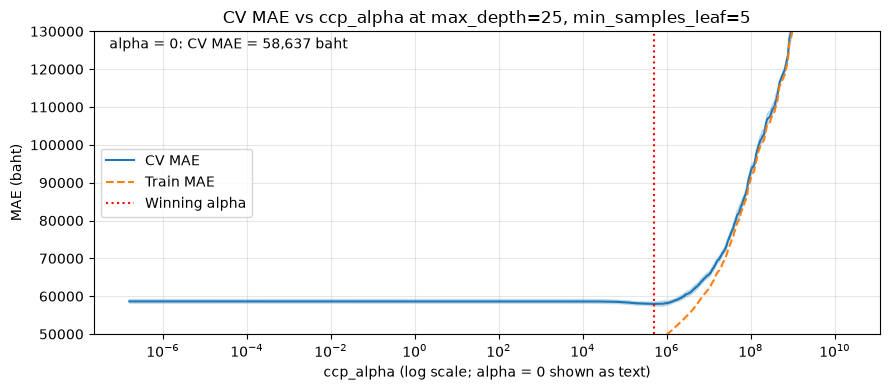

WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (ccp 7 กราฟ) ให้ขยาย MAE_CCP_AXIS ในเซลล์ [03]


In [28]:
# [28] ccp 7: กราฟ CV MAE ต่อ alpha ของคู่ผู้ชนะ
# ==================================================
# ทำอะไร: วาดกราฟ CV MAE (เฉลี่ย ± 1 SD) และ train MAE ต่อ ccp_alpha ของคู่
#         (max_depth, min_samples_leaf) ของผู้ชนะ แกน x เป็นสเกล log และทำเครื่องหมาย alpha ผู้ชนะ
# ทำไม: ดูภาพรวมว่าช่วง alpha ที่ CV MAE ต่ำสุดกว้างแค่ไหน และผู้ชนะอยู่ตรงก้นกราฟจริงหรือไม่
#   - ฝั่งซ้าย (alpha น้อย): ต้นไม้ใหญ่และซับซ้อนเกิน จำข้อมูลฝึก (overfit) CV MAE จึงสูง
#   - ฝั่งขวา (alpha มาก): ต้นไม้เล็กและเรียบง่ายเกิน จับรูปแบบไม่ทัน (underfit) CV MAE จึงสูงขึ้นอีก
#   - แกนถูกล็อกด้วยค่าคงที่ใน [03] (MAE_CCP_AXIS) เหมือนกันทั้ง DT / RF / XGB
# ผลที่ควรเห็น: เส้นรูปตัว U ของ CV MAE, เส้น train MAE ที่ต่ำกว่า และเส้นประที่ alpha ผู้ชนะ
# ข้อควรระวัง:
#   - alpha = 0 วาดบนแกน log ไม่ได้ จึงเขียนค่าไว้เป็นข้อความบนกราฟ
#   - ข้อความในกราฟเป็นภาษาอังกฤษ เพราะฟอนต์ของกราฟอาจไม่มีตัวอักษรไทย (กติกาของโน้ตบุ๊คชุดนี้)
#   - ถ้ามีค่านอกแกนที่ล็อกไว้ จะพิมพ์ WARN หลังกราฟ (ไม่ตัดทิ้งเงียบๆ) ให้ขยาย MAE_CCP_AXIS ใน [03]
# ==================================================
print("=== [28] ccp 7: กราฟ CV MAE ต่อ alpha ของคู่ผู้ชนะ ===")

pair_curve = ccp_cv[ccp_cv["pair"] == winner_pair_index].sort_values("alpha")
positive = pair_curve[pair_curve["alpha"] > 0]
zero_row = pair_curve.iloc[0]  # แถวแรกคือ alpha = 0
winner_alpha = winner_params["ccp_alpha"]

fig, ax = plt.subplots(figsize=(9, 4))
marker = "o" if len(positive) <= 60 else None
line, = ax.plot(positive["alpha"], positive["cv_mae_mean"], marker=marker,
                linestyle="-", label="CV MAE")
ax.fill_between(
    positive["alpha"],
    positive["cv_mae_mean"] - positive["cv_mae_sd"],
    positive["cv_mae_mean"] + positive["cv_mae_sd"],
    color=line.get_color(), alpha=0.2,
)
ax.plot(positive["alpha"], positive["train_mae_mean"], linestyle="--", label="Train MAE")
if winner_alpha > 0:
    ax.axvline(winner_alpha, color="red", linestyle=":", label="Winning alpha")
ax.text(0.02, 0.98, f"alpha = 0: CV MAE = {zero_row['cv_mae_mean']:,.0f} baht",
        transform=ax.transAxes, va="top")
ax.set_xscale("log")
ax.set_xlabel("ccp_alpha (log scale; alpha = 0 shown as text)")
ax.set_ylabel("MAE (baht)")
ax.set_title(
    f"CV MAE vs ccp_alpha at max_depth={winner_params['max_depth']}, "
    f"min_samples_leaf={winner_params['min_samples_leaf']}"
)
ax.set_ylim(*MAE_CCP_AXIS)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

low = np.minimum(pair_curve["train_mae_mean"],
                 pair_curve["cv_mae_mean"] - pair_curve["cv_mae_sd"]).min()
high = np.maximum(pair_curve["train_mae_mean"],
                  pair_curve["cv_mae_mean"] + pair_curve["cv_mae_sd"]).max()
if low < MAE_CCP_AXIS[0] or high > MAE_CCP_AXIS[1]:
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (ccp 7 กราฟ) ให้ขยาย MAE_CCP_AXIS ในเซลล์ [03]")


In [29]:
# [29] Pipeline และฟังก์ชันนับใบ
# ==================================================
# ทำอะไร: ต่อขั้นตอน "แปลงข้อมูล -> โมเดล" เป็น Pipeline ชุดเดียว
#         แล้วสร้างฟังก์ชัน count_pipeline_leaves(params) ที่ฝึกต้นไม้ด้วยพารามิเตอร์ที่ให้มา
#         และบอกว่าต้นไม้นั้นมีกี่ใบ (leaf)
# ทำไม:
#   - Pipeline คือสายพานต่อขั้นตอนเข้าด้วยกัน ที่นี่มี 2 ขั้น ชื่อ "encode" (FoldOneHot จากเซลล์ [19])
#     และ "model" (ต้นไม้จาก make_model ในเซลล์ [20]) ชื่อทั้งสองต้องคงไว้ เพราะ grid ใช้ prefix
#     "model__" ชี้เข้าไปตั้งค่าพารามิเตอร์ของต้นไม้ (เช่น model__max_depth)
#   - ใน CV ทุก fold จะ fit Pipeline ใหม่ทั้งสาย ทำให้ encoder เรียนรู้จากแถวฝึกของ fold นั้นเท่านั้น
#     ข้อมูลฝั่งตรวจจึงไม่รั่วเข้ามา
#   - ใบ (leaf) คือปลายสุดของต้นไม้ที่ให้คำตอบ ยิ่งมีใบมากต้นไม้ยิ่งซับซ้อนและจำข้อมูลฝึกได้ละเอียด
#     จำนวนใบจึงใช้วัดความเรียบง่ายได้ตรงตัว (ใบน้อย = เรียบง่าย) แสดงเป็นข้อมูลให้ดูเท่านั้น
#     ไม่มีผลต่อการเลือกผู้ชนะ ซึ่งเลือกจาก CV MAE ต่ำสุดในเซลล์ [27]
#   - ที่ต้องมี cache (leaf_counts) เพราะชุดเดียวกันถูกนับใบหลายครั้ง ในเซลล์ [33] และ [38]
#     การฝึกต้นไม้ใหม่ทุกครั้งเปลืองเวลา จึงนับครั้งเดียวแล้วจำค่าไว้
# ผลที่ควรเห็น: พิมพ์ชื่อเซลล์ และบอกว่าสร้าง pipeline กับฟังก์ชันแล้ว ยังไม่มีตัวเลขผลลัพธ์
# ข้อควรระวัง: การนับใบฝึกจาก train ทั้งชุดเท่านั้น ไม่แตะ validation หรือ test
#         และใช้ clone เพื่อสร้างสำเนา จึงไม่กระทบ pipeline ต้นแบบ
# ==================================================
print("=== [29] Pipeline และฟังก์ชันนับใบ ===")

pipeline = Pipeline([
    ("encode", FoldOneHot(NUM_COLS, CAT_COLS)),
    ("model", make_model()),
])
leaf_counts = {}


def count_pipeline_leaves(params):
    """ฝึก pipeline ตาม params บน train ทั้งชุด แล้วคืนจำนวนใบ (จำค่าไว้ใน cache)"""
    key = tuple(sorted(params.items()))
    if key not in leaf_counts:
        fitted = clone(pipeline).set_params(**params)
        fitted.fit(train[features], train_prices)
        leaf_counts[key] = int(fitted.named_steps["model"].get_n_leaves())
    return leaf_counts[key]


print("สร้าง pipeline และฟังก์ชัน count_pipeline_leaves แล้ว")

=== [29] Pipeline และฟังก์ชันนับใบ ===
สร้าง pipeline และฟังก์ชัน count_pipeline_leaves แล้ว


In [30]:
# [30] ตั้งค่า GridSearchCV
# ==================================================
# ทำอะไร: สร้างตัวค้นหา GridSearchCV (ยังไม่ฝึก) ที่มี 30 ชุดพารามิเตอร์
#         หนึ่งชุดต่อคู่ (max_depth, min_samples_leaf) พร้อม ccp_alpha ที่ดีที่สุดของคู่นั้น
#         (จากเซลล์ [27]) วัดผลด้วย 5 fold เดิม และใช้ refit="MAE" เลือกผู้ชนะ
# ทำไม:
#   - GridSearchCV คือการลองทุกชุดพารามิเตอร์ วัดผลด้วย cross-validation แล้วเฉลี่ยคะแนน
#     refit="MAE" คือวิธีมาตรฐานของ sklearn: ผู้ชนะ = ชุดที่ mean_test_MAE ดีที่สุด
#     (CV MAE เฉลี่ยต่ำสุด ถ้าเสมอให้ชุดแรก) ตรงกับกฎที่ใช้ในเซลล์ [27]
#   - การรันซ้ำที่นี่มีประโยชน์สองอย่าง: ได้ search / best_estimator_ / cv_results_ ให้เซลล์
#     ถัดไปใช้ตามโครงเดิม และเป็นการตรวจไขว้ว่าคะแนนจาก all_alpha_scores (เร็ว) ตรงกับ
#     การฝึกจริงของ sklearn (เซลล์ [32] assert ให้)
#   - search_grid เป็น list ของ dict (ไม่ใช่ dict ของ list) เพราะแต่ละคู่ใช้ alpha คนละค่า
#     ใส่ prefix "model__" เพื่อชี้เข้าไปที่ขั้น "model" ใน Pipeline
#   - ค่าของแต่ละพารามิเตอร์ใน dict ต้องเป็น list แม้มีค่าเดียว (ข้อกำหนดของ sklearn ParameterGrid)
#   - จำนวน fit = 30 ชุด x 5 fold บวก refit ผู้ชนะบน train ทั้งชุดอีก 1 ครั้ง
#   - scoring วัด 4 ค่า (ทุกค่าเป็นราคาจริงในหน่วยบาท ไม่ได้แปลง log):
#       MAE  = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ย (เช่น ทำนาย 500,000 จริง 450,000 พลาด 50,000)
#       RMSE = รากของค่าเฉลี่ยความคลาดเคลื่อนกำลังสอง ลงโทษพลาดหนัก ๆ มากกว่า MAE
#       MAPE = ความคลาดเคลื่อนเป็นสัดส่วนของราคาจริง
#       R2   = สัดส่วนความแปรปรวนของราคาที่โมเดลอธิบายได้ (1 ดีที่สุด)
#   - sklearn ถือว่า "ค่ามากคือดี" จึงเก็บ error เป็นค่าติดลบ (neg_...) ตอนสรุปกลับเครื่องหมาย
#   - error_score="raise" คือถ้าชุดไหนฝึกพัง ให้หยุดทันทีแทนที่จะเงียบ
#   - return_train_score=True เก็บคะแนนบนส่วนที่ใช้ฝึกของแต่ละ fold ไว้ดู gap
#   - n_jobs และ pre_dispatch ใช้ SEARCH_JOBS (เซลล์ [03])
# ข้อควรระวัง: ส่งเฉพาะ train เข้า search เท่านั้น validation และ test ถูกกันไว้ตรวจภายนอก
# ผลที่ควรเห็น: จำนวนชุด จำนวน CV fits และข้อความว่าสร้าง search แล้ว
# ==================================================
print("=== [30] ตั้งค่า GridSearchCV ===")

search_grid = []
for pair, alpha in zip(pairs, best_alpha_by_pair):
    search_grid.append({
        "model__max_depth": [pair["max_depth"]],
        "model__min_samples_leaf": [pair["min_samples_leaf"]],
        "model__ccp_alpha": [float(alpha)],
    })

fits = len(search_grid) * len(folds)
print(f"จำนวนชุดพารามิเตอร์    : {len(search_grid):,} (หนึ่งชุดต่อคู่ พร้อม alpha ที่ดีที่สุดของคู่)")
print(f"จำนวน CV fits         : {fits:,} ({len(search_grid):,} ชุด x {len(folds)} fold)")
print("(ยังมี refit ผู้ชนะบน train ทั้งชุดอีก 1 ครั้ง และการนับใบอีกไม่กี่ครั้ง)")

search = GridSearchCV(
    pipeline,
    param_grid=search_grid,
    cv=folds,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "MAPE": "neg_mean_absolute_percentage_error",
        "R2": "r2",
    },
    refit="MAE",
    return_train_score=True,
    error_score="raise",
    n_jobs=SEARCH_JOBS,
    pre_dispatch=SEARCH_JOBS,
    verbose=0,
)
print("สร้าง search แล้ว (ยังไม่ได้ฝึก)")


=== [30] ตั้งค่า GridSearchCV ===
จำนวนชุดพารามิเตอร์    : 30 (หนึ่งชุดต่อคู่ พร้อม alpha ที่ดีที่สุดของคู่)
จำนวน CV fits         : 150 (30 ชุด x 5 fold)
(ยังมี refit ผู้ชนะบน train ทั้งชุดอีก 1 ครั้ง และการนับใบอีกไม่กี่ครั้ง)
สร้าง search แล้ว (ยังไม่ได้ฝึก)


In [31]:
# [31] รัน GridSearchCV
# ==================================================
# ทำอะไร: สั่ง search.fit บน train เพื่อลองทุกชุดพารามิเตอร์ใน grid ทุก fold
#         แล้ว refit="MAE" (เซลล์ [30]) เลือกชุดที่ CV MAE ต่ำสุดเป็นผู้ชนะ และ refit ผู้ชนะบน train ทั้งชุด
# ทำไม: ตรงนี้เป็นหนึ่งในขั้นที่ใช้เวลามากที่สุดของโน้ตบุ๊ค (อีกขั้นคือ joint search ในเซลล์ [25])
#         parallel_backend("loky", ...) จำกัดจำนวน thread ภายในแต่ละ worker ตาม MODEL_THREADS
#         (เซลล์ [03]) เพื่อไม่ให้ CPU ถูกแย่งกันเอง
# ผลที่ควรเห็น: เซลล์ไม่พิมพ์อะไรจนกว่าจะเสร็จ ช่วงรันจึงเงียบเป็นเรื่องปกติ
#         เวลาที่ใช้ขึ้นกับเครื่องและ SEARCH_JOBS ท้ายเซลล์พิมพ์เวลาที่ใช้จริง
# ข้อควรระวัง: อย่าหยุดรันกลางคัน ถ้าหยุดต้องเริ่มใหม่ทั้งเซลล์
# ==================================================
print("=== [31] รัน GridSearchCV ===")

started = time.monotonic()
with parallel_backend("loky", inner_max_num_threads=MODEL_THREADS, max_nbytes=None):
    search.fit(train[features], train_prices)
search_seconds = time.monotonic() - started

minutes, seconds = divmod(search_seconds, 60)
print(f"ค้นหาเสร็จแล้ว ใช้เวลา {int(minutes)} นาที {seconds:.0f} วินาที")

=== [31] รัน GridSearchCV ===


ค้นหาเสร็จแล้ว ใช้เวลา 0 นาที 21 วินาที


In [32]:
# [32] ตรวจความสอดคล้องของ joint search กับ GridSearchCV
# ==================================================
# ทำอะไร: ตรวจด้วย assert ว่า CV MAE ที่คำนวณเร็วด้วย all_alpha_scores (เซลล์ [25])
#         ตรงกับ mean_test_MAE ของ GridSearchCV (เซลล์ [31]) ทุกคู่ (rtol 1e-9)
#         และ search.best_params_ ตรงกับผู้ชนะจากเซลล์ [27]
# ทำไม: all_alpha_scores ไม่ได้ฝึกต้นไม้ใหม่ มันคำนวณจากการตัดกิ่งของต้นไม้ที่ฝึกครั้งเดียว
#       ถ้าลำดับการตัดกิ่งหรือสูตร alpha คลาดจาก sklearn แม้แต่นิดเดียว การเลือกผู้ชนะ
#       ก็อาจเปลี่ยนได้ การเทียบคะแนนกับการฝึกจริงทุกคู่จึงเป็นการตรวจที่ตรงจุดที่สุด
#       (ตัวฟังก์ชันเองมี self-test กับข้อมูลจำลองอยู่แล้วในเซลล์ [22])
# ผลที่ควรเห็น: ผลต่างมากที่สุด (ควรเป็นระดับเศษทศนิยมของ float) และข้อความว่าผ่าน
#       ถ้าไม่ผ่านจะเห็น AssertionError พร้อมบอกว่าค่าไหนไม่ตรง
# ข้อควรระวัง: ค่าที่ตรงกันยืนยันว่า all_alpha_scores ถูก แต่ไม่ได้แปลว่าผล CV เป็นอิสระ
#       จากการเลือก (alpha ยังมาจากต้นไม้ที่ฝึกบน train ทั้งชุด ดูเซลล์ [33])
# ==================================================
print("=== [32] ตรวจความสอดคล้องของ joint search กับ GridSearchCV ===")

cv_results = search.cv_results_
search_mae_by_pair = -np.asarray(cv_results["mean_test_MAE"], dtype=float)
differences = np.abs(search_mae_by_pair - fast_cv_mae_by_pair)
worst = int(np.argmax(differences))
print(f"ผลต่าง CV MAE มากที่สุดระหว่างสองวิธี : {differences[worst]:.3e} บาท (คู่ index {worst})")
assert np.allclose(search_mae_by_pair, fast_cv_mae_by_pair, rtol=1e-9, atol=0), (
    "CV MAE จาก GridSearchCV ไม่ตรงกับค่าที่คำนวณด้วย all_alpha_scores"
)

expected_params = {
    "model__max_depth": winner_params["max_depth"],
    "model__min_samples_leaf": winner_params["min_samples_leaf"],
    "model__ccp_alpha": winner_params["ccp_alpha"],
}
assert search.best_params_ == expected_params, (
    f"ผู้ชนะของ GridSearchCV ({search.best_params_}) "
    f"ไม่ตรงกับผู้ชนะของ joint search ({expected_params})"
)
print("ผ่าน: mean_test_MAE ของทุกคู่ตรงกับ all_alpha_scores และ best_params_ ตรงกับผู้ชนะ")


=== [32] ตรวจความสอดคล้องของ joint search กับ GridSearchCV ===
ผลต่าง CV MAE มากที่สุดระหว่างสองวิธี : 1.310e-10 บาท (คู่ index 1)
ผ่าน: mean_test_MAE ของทุกคู่ตรงกับ all_alpha_scores และ best_params_ ตรงกับผู้ชนะ


In [33]:
# [33] สรุปผล joint search
# ==================================================
# ทำอะไร: สรุปผู้ชนะของ GridSearchCV จากผล search ในเซลล์ [31] (ชุดที่ CV MAE เฉลี่ยต่ำสุด)
#         แสดงพารามิเตอร์ CV MAE SD SE train MAE gap จำนวนใบ จำนวน alpha ที่ลอง และเวลาที่ใช้
#         เก็บ cv_results, cv_mae_all, train_mae_all, chosen_index, n_splits, best_params
#         ไว้ให้เซลล์ถัดไปใช้
# ทำไม: เพื่อให้เห็นตัวเลขของผู้ชนะที่เซลล์ถัดไปใช้ต่อ และเห็นขนาดของงานค้นหา
# คำอธิบายค่าที่พิมพ์:
#   index = ลำดับของชุดใน cv_results_   CV MAE = ค่าเฉลี่ย MAE บนแถวตรวจของทุก fold (บาท)
#   SD = ส่วนเบี่ยงเบนมาตรฐานของ MAE ราย fold (sklearn คำนวณแบบ ddof=0 หารด้วย n)
#   SE = SD / sqrt(n_splits) บอกความแกว่งของ CV MAE ให้ดูเท่านั้น ไม่ได้ใช้เลือกผู้ชนะ
#   train MAE = MAE บนส่วนที่ใช้ฝึกของแต่ละ fold เฉลี่ยข้าม fold   gap = CV MAE - train MAE
#   leaves = จำนวนใบของต้นไม้ผู้ชนะที่ฝึกบน train ทั้งชุด (นับซ้ำเมื่อเรียก count_pipeline_leaves)
# ข้อควรระวัง:
#   - gap เป็นอาการที่ต้องอ่านคู่กับระดับ CV MAE ไม่ใช่มาตรวัด overfitting ด้วยตัวเอง
#     (gap เล็กอาจเพราะ train fit แย่ลง) เราไม่ใช้ gap ตัดสิน
#   - ผล CV หลังเลือกไม่ใช่การประเมินอิสระ ส่วน validation / test ถูกกันไว้ประเมินภายนอกใน [36]
#   - รายการ alpha ของแต่ละคู่สร้างจากต้นไม้ที่ฝึกบน train ทั้งชุด (เซลล์ [23]) ซึ่งรวมแถวที่
#     แต่ละ fold กันไว้ตอน CV ค่า CV MAE จึงอาจดีเกินจริงเล็กน้อย การตรวจที่ไม่เอนเอียงคือ
#     test ที่ยังไม่แตะ (รวมถึง validation)
#   - nested CV จะตัด bias นี้ออกได้ แต่ไม่ได้ทำ เพราะใช้เวลามากขึ้นหลายเท่า
# ผลที่ควรเห็น: บรรทัดสรุปของผู้ชนะและเวลาที่ใช้ค้นหา
# ==================================================
print("=== [33] สรุปผล joint search ===")

cv_results = search.cv_results_
cv_mae_all = -np.asarray(cv_results["mean_test_MAE"])
train_mae_all = -np.asarray(cv_results["mean_train_MAE"])
n_splits = 0
for key in cv_results:
    if key.startswith("split") and key.endswith("_test_MAE"):
        n_splits = n_splits + 1
chosen_index = int(search.best_index_)
best_params = {}
for key, value in search.best_params_.items():
    best_params[key.removeprefix("model__")] = value

cv_sd = cv_results["std_test_MAE"][chosen_index]
cv_se = cv_sd / np.sqrt(n_splits)
alpha_counts = [len(values) for values in pair_alphas]

print("ผู้ชนะ (CV MAE ต่ำสุด จากทุกคู่ x ทุก alpha)")
print(f"  index            : {chosen_index}")
print(f"  params           : {best_params}")
print(f"  CV MAE           : {cv_mae_all[chosen_index]:,.0f} บาท")
print(f"  CV SD            : {cv_sd:,.0f} บาท")
print(f"  CV SE            : {cv_se:,.0f} บาท (SD / sqrt(n_splits) ใช้ดูความแกว่งเท่านั้น)")
print(f"  train MAE        : {train_mae_all[chosen_index]:,.0f} บาท")
print(f"  gap              : {cv_mae_all[chosen_index] - train_mae_all[chosen_index]:,.0f} บาท")
print(f"  leaves           : {count_pipeline_leaves(search.best_params_):,}")
print(f"  alpha ที่ลอง     : {min(alpha_counts):,} ถึง {max(alpha_counts):,} ต่อคู่, "
      f"รวม {sum(alpha_counts):,}")
print(f"  เวลาที่ใช้ค้นหา  : {joint_seconds + search_seconds:,.0f} วินาที "
      f"(joint search {joint_seconds:,.0f} + GridSearchCV {search_seconds:,.0f})")


=== [33] สรุปผล joint search ===
ผู้ชนะ (CV MAE ต่ำสุด จากทุกคู่ x ทุก alpha)
  index            : 19
  params           : {'ccp_alpha': 486064.99689526187, 'max_depth': 25, 'min_samples_leaf': 5}
  CV MAE           : 57,931 บาท
  CV SD            : 477 บาท
  CV SE            : 213 บาท (SD / sqrt(n_splits) ใช้ดูความแกว่งเท่านั้น)
  train MAE        : 47,951 บาท
  gap              : 9,980 บาท


  leaves           : 1,609
  alpha ที่ลอง     : 364 ถึง 13,279 ต่อคู่, รวม 87,088
  เวลาที่ใช้ค้นหา  : 49 วินาที (joint search 28 + GridSearchCV 21)


In [34]:
# [34] ตรวจขอบ grid
# ==================================================
# ทำอะไร: ตรวจทีละพารามิเตอร์ว่าค่าของผู้ชนะ (ชุดที่ CV MAE ต่ำสุด) อยู่ "ด้านใน" ของ grid
#         หรือไปตกที่ขอบ (ค่าต่ำสุดหรือสูงสุดของรายการใน PARAM_GRID) แล้วพิมพ์ PASS หรือ WARN
#         พารามิเตอร์ที่ปรับมี 3 ตัว: max_depth, min_samples_leaf และ ccp_alpha
# ทำไม: grid search เลือกได้แค่ค่าที่เราเตรียมไว้ ถ้าค่าที่ดีที่สุดอยู่ที่ขอบของช่วงที่ลอง
#       ค่าที่ดีกว่าอาจอยู่นอกช่วง (เช่น ถ้าชนะที่ min_samples_leaf = 15 ซึ่งเป็นค่ามากสุดใน grid
#       ค่า 20 หรือ 25 อาจดีกว่าอีก) เราจึงอ้างไม่ได้ว่าปรับดีแล้ว ต้องขยาย grid ด้านนั้นแล้วรันใหม่
#       ถ้าค่าอยู่ด้านใน แปลว่ามีค่าที่ลองแล้วแย่กว่าทั้งสองข้าง grid "ครอบ" จุดที่ดีไว้แล้ว
#   ยกเว้น "ขอบธรรมชาติ" ที่ขยายต่อไม่ได้อยู่แล้ว จึงนับเป็น PASS:
#     - min_samples_leaf = 1 (ใบเล็กกว่า 1 คันไม่ได้)
#     - max_depth = None (ไม่จำกัดความลึก ลึกกว่านี้ไม่ได้อีกแล้ว)
#     - ccp_alpha = 0 (ไม่ตัดกิ่งเลย เล็กกว่านี้ไม่ได้)
#   ccp_alpha ตรวจกับรายการ alpha ของคู่ผู้ชนะ (เซลล์ [23]):
#     - อยู่ที่ 0 = PASS (ขอบธรรมชาติ)
#     - เป็น alpha ตัวสุดท้ายของรายการ = ต้นไม้เหลือรากเดียว ซึ่งเป็นขอบบนที่ขยายต่อไม่ได้
#       ด้วยวิธีเดียวกัน (ไม่มี alpha ใหญ่กว่านี้ใน path) แต่ถ้าชนะที่จุดนี้แปลว่าโมเดลอาจเรียบเกินไป
#       จึงรายงาน WARN ให้ตรวจดู
#     - อยู่ด้านในรายการ = PASS
#   วิธีปรับ grid ของ DT ถูกตรึงไว้ตามต้นฉบับ เซลล์นี้จึงแค่รายงานผล ไม่แก้ grid
# ผลที่ควรเห็น: หนึ่งบรรทัดต่อพารามิเตอร์ บอกค่าของผู้ชนะ ช่วงของ grid และสถานะ แล้วบรรทัดสรุป
# ข้อควรระวัง: PASS บอกแค่ว่าไม่ได้ตกขอบ grid ไม่ได้รับประกันว่าไม่มีค่าที่ดีกว่าระหว่างจุดที่ลอง
# ==================================================
print("=== [34] ตรวจขอบ grid ===")

natural_bounds = {"max_depth": [None], "min_samples_leaf": [1]}


def edge_order(value):
    """ลำดับสำหรับหาขอบ: None (ไม่จำกัดความลึก) ถือว่ามากกว่าตัวเลขทุกตัว"""
    return float("inf") if value is None else value


def show(name, value):
    """แสดงค่าพารามิเตอร์ ccp_alpha เป็นรูป .3e ตัวอื่นแสดงตามปกติ"""
    return f"{value:.3e}" if name == "ccp_alpha" else str(value)


warnings_found = 0
print("ผู้ชนะ (CV MAE ต่ำสุด)")
for name in ["max_depth", "min_samples_leaf"]:
    values = sorted(PARAM_GRID[name], key=edge_order)
    value = best_params[name]
    at_edge = value == values[0] or value == values[-1]
    if not at_edge:
        status = "PASS (อยู่ด้านในของ grid)"
    elif value in natural_bounds[name]:
        status = "PASS (อยู่ที่ขอบธรรมชาติ ขยายต่อไม่ได้)"
    else:
        status = "WARN (ตกขอบ grid ค่าที่ดีกว่าอาจอยู่นอกช่วง ควรขยาย grid ด้านนี้)"
        warnings_found = warnings_found + 1
    print(f"  {name:<17}: {show(name, value)} "
          f"(grid {show(name, values[0])} ถึง {show(name, values[-1])}) -> {status}")

winner_alphas = pair_alphas[winner_pair_index]
alpha = best_params["ccp_alpha"]
if alpha == 0.0:
    status = "PASS (อยู่ที่ขอบธรรมชาติ: ไม่ตัดกิ่ง)"
elif alpha == winner_alphas[-1]:
    status = "WARN (เป็น alpha ตัวสุดท้าย = ต้นไม้เหลือรากเดียว โมเดลอาจเรียบเกินไป)"
    warnings_found = warnings_found + 1
elif alpha in winner_alphas:
    status = "PASS (อยู่ในรายการ alpha ของคู่ผู้ชนะ)"
else:
    status = "WARN (ไม่อยู่ในรายการ alpha ของคู่ผู้ชนะ)"
    warnings_found = warnings_found + 1
print(f"  {'ccp_alpha':<17}: {show('ccp_alpha', alpha)} "
      f"(รายการ alpha ของคู่ผู้ชนะ {show('ccp_alpha', winner_alphas[0])} ถึง "
      f"{show('ccp_alpha', winner_alphas[-1])}) -> {status}")

if warnings_found == 0:
    print("สรุป: PASS ค่าของผู้ชนะไม่ตกขอบ grid ทุกพารามิเตอร์")
else:
    print(f"สรุป: WARN ผู้ชนะตกขอบ grid {warnings_found} พารามิเตอร์")


=== [34] ตรวจขอบ grid ===
ผู้ชนะ (CV MAE ต่ำสุด)
  max_depth        : 25 (grid 10 ถึง None) -> PASS (อยู่ด้านในของ grid)
  min_samples_leaf : 5 (grid 1 ถึง 15) -> PASS (อยู่ด้านในของ grid)
  ccp_alpha        : 4.861e+05 (รายการ alpha ของคู่ผู้ชนะ 0.000e+00 ถึง 1.690e+10) -> PASS (อยู่ในรายการ alpha ของคู่ผู้ชนะ)
สรุป: PASS ค่าของผู้ชนะไม่ตกขอบ grid ทุกพารามิเตอร์


In [35]:
# [35] ฟังก์ชัน score
# ==================================================
# ทำอะไร: สร้างฟังก์ชัน score(actual, predicted) ที่คำนวณ 4 metric เทียบราคาจริงกับราคาที่ทำนาย
# ทำไม: ใช้ซ้ำกับ train, validation และ test ในเซลล์ [36] จึงสร้างเป็นฟังก์ชัน ลำดับ key คงที่
#         (RMSE, MAE, MAPE, R2) เพื่อให้ตารางและ RESULT_JSON เรียงเหมือนเดิม
#   ตัวอย่างสมมติ: รถราคาจริง 500,000 บาท โมเดลทำนาย 450,000 บาท
#   - MAE  (Mean Absolute Error) เฉลี่ยของ |จริง - ทำนาย| เป็นบาท ตัวอย่างนี้พลาด 50,000 บาท
#   - RMSE (Root Mean Squared Error) ยกกำลังสองก่อนเฉลี่ยแล้วถอดรากที่สอง จึงลงโทษข้อพลาดใหญ่หนักกว่า
#          MAE ถ้า RMSE สูงกว่า MAE มาก แปลว่ามีบางคันที่ทำนายพลาดมาก
#   - MAPE (Mean Absolute Percentage Error) พลาดเป็นสัดส่วนของราคาจริง ตัวอย่างนี้ 50,000 / 500,000
#          = 0.10 (10%) ทำให้เทียบรถถูกกับรถแพงได้ยุติธรรมกว่า
#   - R2 (R-squared) สัดส่วนความแปรปรวนของราคาที่โมเดลอธิบายได้ 1 คือสมบูรณ์ 0 คือไม่ดีกว่าเดาค่าเฉลี่ย
# ผลที่ควรเห็น: บอกว่าสร้างฟังก์ชันแล้ว ยังไม่มีตัวเลข
# ==================================================
print("=== [35] ฟังก์ชัน score ===")


def score(actual, predicted):
    """คำนวณ RMSE, MAE, MAPE และ R2 เทียบราคาจริงกับราคาที่ทำนาย (ไม่ปัดเศษ)"""
    return {
        "RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "MAE": mean_absolute_error(actual, predicted),
        "MAPE": np.mean(np.abs(predicted / actual - 1)),
        "R2": r2_score(actual, predicted),
    }


print("สร้างฟังก์ชัน score แล้ว")

=== [35] ฟังก์ชัน score ===
สร้างฟังก์ชัน score แล้ว


In [36]:
# [36] วัดผล train / validation / test
# ==================================================
# ทำอะไร: ใช้โมเดลผู้ชนะ (search.best_estimator_ ซึ่งถูก refit บน train ทั้งชุดแล้ว) ทำนายราคา
#         ของ 3 ชุดข้อมูล แล้วคำนวณ 4 metric ด้วย score จากเซลล์ [35]
# ทำไม: เทียบผลของ 3 ชุดเพื่อดูว่าโมเดลเรียนรู้พอดีหรือไม่
# วิธีอ่านตาราง (หน่วยเงินเป็นบาท):
#   - validation ใกล้เคียง test แปลว่าโมเดลทำนายข้อมูลใหม่ได้สม่ำเสมอ (generalise ได้)
#   - ถ้า train ดีกว่า validation มาก (error ต่ำกว่ามาก) แสดงว่าอาจ overfit คือจำข้อมูลฝึกแต่ทำนาย
#     ข้อมูลใหม่ได้แย่กว่า ให้อ่านส่วนต่างคู่กับระดับของ error ไม่ใช่ดูส่วนต่างอย่างเดียว
#   - test ใช้รายงานผลเท่านั้น ไม่เคยใช้เลือกพารามิเตอร์หรือโมเดลใด ๆ
# ผลที่ควรเห็น: ตาราง 3 แถว (train, validation, test) 4 คอลัมน์ metric
#         MAE/RMSE เป็นบาท MAPE/R2 ทศนิยม 4 ตำแหน่ง
# ==================================================
print("=== [36] วัดผล train / validation / test ===")

model = search.best_estimator_
results = {}
for name, part in [("train", train), ("validation", val), ("test", test)]:
    results[name] = score(part["price"], model.predict(part[features]))

print("ตารางผล: แต่ละแถวคือชุดข้อมูล แต่ละคอลัมน์คือ metric (error ยิ่งต่ำยิ่งดี, R2 ยิ่งสูงยิ่งดี)")
display(
    pd.DataFrame.from_dict(results, orient="index").style.format({
        "RMSE": "{:,.0f}",
        "MAE": "{:,.0f}",
        "MAPE": "{:.4f}",
        "R2": "{:.4f}",
    })
)

=== [36] วัดผล train / validation / test ===


ตารางผล: แต่ละแถวคือชุดข้อมูล แต่ละคอลัมน์คือ metric (error ยิ่งต่ำยิ่งดี, R2 ยิ่งสูงยิ่งดี)


,RMSE,MAE,MAPE,R2
train,"71,156","48,149",0.0945,0.9530
validation,"90,272","57,584",0.1091,0.9255
test,"85,630","56,628",0.1072,0.9319


In [37]:
# [37] พิมพ์ RESULT_JSON
# ==================================================
# ทำอะไร: พิมพ์ผลสรุปของการทดลองเป็นข้อความ JSON บรรทัดเดียวขึ้นต้นด้วย "RESULT_JSON="
# ทำไม: บรรทัดนี้ออกแบบให้เครื่องอ่าน โน้ตบุ๊คอื่นหรือสคริปต์อื่นค้นหาบรรทัดที่ขึ้นต้นด้วย
#         "RESULT_JSON=" แล้วแปลง JSON เพื่อเทียบผลของหลายโมเดลได้ ค่าทั้งหมดพิมพ์เต็มความละเอียด
#         (ไม่ปัดเศษ) คีย์เรียงตาม: model, version, features, best_params, train, validation, test
# ผลที่ควรเห็น: บรรทัดสุดท้ายของเซลล์คือ RESULT_JSON=... ยาวบรรทัดเดียว
# ข้อควรระวัง: ให้เป็นผลลัพธ์สุดท้ายของเซลล์ อย่าเพิ่ม print อื่นต่อท้าย
#         default=float แปลงตัวเลขชนิดของ NumPy ให้ JSON รองรับ
# ==================================================
print("=== [37] พิมพ์ RESULT_JSON ===")

print("RESULT_JSON=" + json.dumps({
    "run_id": RUN_ID,
    "dataset": DATASET,
    "variant": VARIANT,
    "model": MODEL_NAME,
    "version": VERSION,
    "features": features,
    "best_params": best_params,
    "train": results["train"],
    "validation": results["validation"],
    "test": results["test"],
}, default=float))

=== [37] พิมพ์ RESULT_JSON ===
RESULT_JSON={"run_id": "DT_merge50minC", "dataset": "merge_50min_clean.csv", "variant": "base", "model": "DT", "version": "v5", "features": ["engine", "mileage", "car_age", "brand", "model", "car_type", "fuel", "gear"], "best_params": {"ccp_alpha": 486064.99689526187, "max_depth": 25, "min_samples_leaf": 5}, "train": {"RMSE": 71156.09338376332, "MAE": 48149.266562413526, "MAPE": 0.09448273224446263, "R2": 0.9530350383602062}, "validation": {"RMSE": 90271.80959915991, "MAE": 57583.653471933685, "MAPE": 0.10909713756698244, "R2": 0.9255363243344525}, "test": {"RMSE": 85629.63271977236, "MAE": 56628.24566167066, "MAPE": 0.10724809951749523, "R2": 0.9318722614324038}}


In [38]:
# [38] ตาราง 10 อันดับแรก
# ==================================================
# ทำอะไร: แสดง 10 ชุดพารามิเตอร์ที่ CV MAE ต่ำสุดจาก GridSearchCV (เซลล์ [31]) พร้อมพารามิเตอร์
#         ทุกตัว, จำนวนใบ, ส่วนเบี่ยงเบนมาตรฐานข้าม fold (cv_mae_sd), train MAE และ gap
#         (MAE = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ย หน่วยบาท)
# ทำไม: ดูว่าผู้ชนะ (ชุดที่ CV MAE ต่ำสุด) ต่างจากอันดับถัดไปมากแค่ไหน เทียบกับความแกว่งข้าม fold
# ผลที่ควรเห็น: ตาราง 10 แถว แถวแรกคือผู้ชนะ คอลัมน์:
#   - candidate : ลำดับของชุดพารามิเตอร์ใน grid
#   - chosen    : เครื่องหมาย * คือผู้ชนะ (CV MAE ต่ำสุด ถ้าเสมอเลือกดัชนีต่ำกว่า)
#   - leaves    : จำนวนใบของต้นไม้ที่ฝึกบน train ทั้งชุด (นับเฉพาะแถวที่แสดง)
#                 แสดงให้ดูเท่านั้น ไม่มีผลต่อการเลือกผู้ชนะ
#   - rank      : อันดับตาม CV MAE (1 = ต่ำสุด)
#   - max_depth, min_samples_leaf, ccp_alpha : ค่าพารามิเตอร์ของชุดนั้น
#   - cv_mae, cv_mae_sd, train_mae : MAE ตรวจสอบเฉลี่ย, ความแกว่งข้าม fold, MAE บนส่วนที่ใช้ฝึก
#   - gap       : cv_mae - train_mae
# ข้อควรระวัง:
#   - gap เป็นแค่อาการ ต้องอ่านคู่กับระดับของ CV MAE และ cv_mae_sd gap ต่ำอาจเกิดจากการที่
#     train ฟิตได้แย่ลง จึงไม่ใช่หลักฐานว่า overfit น้อยกว่าเพียงลำพัง
#   - ชุดอันดับต้น ๆ อาจต่างกันน้อยกว่าความแกว่งข้าม fold (cv_mae_sd) จึงอย่าตีความว่า
#     ชุดผู้ชนะดีกว่าจริงเสมอ
#   - ccp_alpha ของแต่ละแถวเป็นค่าที่ดีที่สุดเฉพาะคู่ของแถวนั้น ไม่ได้เรียงตามขนาด alpha
#   - เซลล์นี้ไม่เปลี่ยนโมเดลหรือ RESULT_JSON
# ==================================================
print("=== [38] ตาราง 10 อันดับแรก ===")

all_results = pd.DataFrame(search.cv_results_)
# mean_test_MAE เป็นค่าลบ จึงเรียงจากมากไปน้อย = MAE ต่ำสุดก่อน, stable คงลำดับเดิมเมื่อเสมอ
top = all_results.sort_values("mean_test_MAE", ascending=False, kind="stable").head(10)

rows = []
for index in top.index:
    result = all_results.loc[index]
    params = result["params"]
    cv_mae = -result["mean_test_MAE"]
    train_mae = -result["mean_train_MAE"]
    rows.append({
        "candidate": index,
        "chosen": "*" if index == search.best_index_ else "",
        "leaves": count_pipeline_leaves(params),
        "rank": result["rank_test_MAE"],
        "max_depth": str(params["model__max_depth"]),  # แสดง None เป็นข้อความ
        "min_samples_leaf": params["model__min_samples_leaf"],
        "ccp_alpha": params["model__ccp_alpha"],
        "cv_mae": cv_mae,
        "cv_mae_sd": result["std_test_MAE"],
        "train_mae": train_mae,
        "gap": cv_mae - train_mae,
    })

top10 = pd.DataFrame(rows)

print("อ่านตาราง: เรียงตาม CV MAE ต่ำสุดก่อน, * = ผู้ชนะ")
display(
    top10.style
    .format(
        {
            "leaves": "{:,.0f}",
            "rank": "{:.0f}",
            "ccp_alpha": "{:.3e}",
            "cv_mae": "{:,.0f}",
            "cv_mae_sd": "{:,.0f}",
            "train_mae": "{:,.0f}",
            "gap": "{:,.0f}",
        },
        na_rep="",
    )
    .hide(axis="index")
)


=== [38] ตาราง 10 อันดับแรก ===


อ่านตาราง: เรียงตาม CV MAE ต่ำสุดก่อน, * = ผู้ชนะ


candidate,chosen,leaves,rank,max_depth,min_samples_leaf,ccp_alpha,cv_mae,cv_mae_sd,train_mae,gap
19,*,"1,609",1,25,5,4.861e+05,"57,931",477,"47,951","9,980"
25,,"1,646",2,None,5,4.859e+05,"57,973",506,"47,855","10,118"
18,,"1,513",3,25,1,1.109e+06,"58,208",654,"44,352","13,855"
13,,"1,438",4,20,5,4.862e+05,"58,244",605,"49,024","9,220"
24,,"1,576",5,None,1,1.109e+06,"58,281",696,"44,048","14,233"
12,,"1,356",6,20,1,1.116e+06,"58,550",660,"46,130","12,420"
20,,"1,829",7,25,7,2.724e+05,"58,620",429,"49,237","9,384"
26,,"1,856",8,None,7,2.724e+05,"58,660",491,"49,151","9,509"
14,,"1,655",9,20,7,2.724e+05,"58,893",540,"50,105","8,789"
21,,"1,729",10,25,9,2.205e+05,"59,382",574,"51,041","8,341"


In [39]:
# [39] learning curve: คำนวณ
# ==================================================
# ทำอะไร: ฝึกโมเดลผู้ชนะซ้ำหลายรอบบนข้อมูล train ที่มีขนาดเพิ่มขึ้นตาม LC_FRACTIONS
#         (10%, 20%, ... 100%) แล้ววัด MAE และ R² บนชุดย่อยที่ใช้ฝึกกับบน test
#         (MAE = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ย หน่วยบาท,
#          R² = สัดส่วนความผันผวนของราคาที่โมเดลอธิบายได้ 1 = ดีที่สุด,
#          sd = ส่วนเบี่ยงเบนมาตรฐาน บอกว่าค่าแกว่งแค่ไหนระหว่างรอบ)
# ทำไม: learning curve ตอบคำถามว่า "ถ้ามีข้อมูลเพิ่ม โมเดลจะดีขึ้นไหม"
#       ถ้า test MAE ยังลดลงเรื่อย ๆ เมื่อเพิ่มแถว อาจได้ประโยชน์จากข้อมูลเพิ่ม
#       ถ้าเส้นนิ่งแล้ว ข้อมูลเพิ่มอาจช่วยน้อย
#       ทำซ้ำ LC_REPEATS (5) รอบ แต่ละรอบสุ่มลำดับแถวของ train ใหม่ด้วย seed ที่กำหนดจาก
#       [SEED, เลขรอบ] จึงทำซ้ำได้เหมือนเดิมทุกครั้ง ภายในรอบเดียวกันชุดเล็กเป็นส่วนหนึ่งของชุดใหญ่
#       (ซ้อนกัน) เพื่อให้เทียบขนาดต่าง ๆ ได้เป็นธรรม แล้วรายงานค่าเฉลี่ยและ sd ข้ามรอบ
#       (pandas คำนวณ sd แบบ ddof=1)
# ผลที่ควรเห็น: ข้อความ "รอบที่ k/5 เสร็จ" ทีละบรรทัด จากนั้นได้
#   - lc_runs  : ผลดิบ หนึ่งแถวต่อรอบและขนาด
#   - lc_table : ผลสรุปต่อขนาด (mean และ sd ของ train/test MAE และ R², จำนวนรอบ repeats)
#   เซลล์ [40] แสดงตารางและกราฟ
# ข้อควรระวัง:
#   - ผลเป็นหลักฐานเชิงชี้แนะเท่านั้น ไม่รับประกันผลนอกขนาดและข้อมูลที่ลอง
#   - ใช้ test เพื่ออธิบายกราฟเท่านั้น ไม่ใช้เลือกพารามิเตอร์หรือย้อนปรับโมเดล
#   - ไม่เปลี่ยน RESULT_JSON
# ==================================================
print("=== [39] learning curve: คำนวณ ===")

# ขนาดที่ใช้ฝึก: ปัดลง และมีอย่างน้อย 2 แถวเพื่อให้คำนวณ R² ได้
sizes = np.unique(np.clip((LC_FRACTIONS * len(train)).astype(int), 2, len(train)))

records = []
for repeat in range(LC_REPEATS):
    seed_sequence = np.random.SeedSequence([SEED, repeat])
    order = np.random.default_rng(seed_sequence).permutation(len(train))
    for size in sizes:
        subset = train.iloc[order[:size]]  # ชุดเล็กเป็นส่วนหนึ่งของชุดใหญ่
        estimator = clone(search.best_estimator_)  # พารามิเตอร์ผู้ชนะ ไม่แก้ search
        estimator.fit(subset[features], subset["price"])
        train_pred = estimator.predict(subset[features])
        test_pred = estimator.predict(test[features])
        records.append({
            "repeat": repeat + 1,
            "rows": int(size),
            "train MAE": mean_absolute_error(subset["price"], train_pred),
            "test MAE": mean_absolute_error(test["price"], test_pred),
            "train R2": r2_score(subset["price"], train_pred),
            "test R2": r2_score(test["price"], test_pred),
        })
    print(f"รอบที่ {repeat + 1}/{LC_REPEATS} เสร็จ")

lc_runs = pd.DataFrame(records)
metric_columns = ["train MAE", "test MAE", "train R2", "test R2"]
lc_table = lc_runs.groupby("rows")[metric_columns].agg(["mean", "std"])

# ทำชื่อคอลัมน์สองชั้นให้เป็นชั้นเดียว เช่น "train MAE mean", "train MAE sd"
flat_columns = []
for metric, statistic in lc_table.columns:
    flat_columns.append(f"{metric} {'sd' if statistic == 'std' else 'mean'}")
lc_table.columns = flat_columns

lc_table["repeats"] = lc_runs.groupby("rows")["repeat"].nunique()
lc_table = lc_table.reset_index()
print(f"ได้ผลครบ {len(lc_runs)} แถว ใน lc_runs และสรุป {len(lc_table)} ขนาดใน lc_table")

=== [39] learning curve: คำนวณ ===


รอบที่ 1/5 เสร็จ


รอบที่ 2/5 เสร็จ


รอบที่ 3/5 เสร็จ


รอบที่ 4/5 เสร็จ


รอบที่ 5/5 เสร็จ
ได้ผลครบ 50 แถว ใน lc_runs และสรุป 10 ขนาดใน lc_table


=== [40] learning curve: ตารางและกราฟ ===
อ่านตาราง: ค่าเฉลี่ยและ sd ข้าม 5 รอบ ของ MAE (บาท) และ R² ที่แต่ละจำนวนแถวฝึก


rows,train MAE mean,train MAE sd,test MAE mean,test MAE sd,train R2 mean,train R2 sd,test R2 mean,test R2 sd,repeats
"3,685","58,130","1,388","80,265","1,081",0.9190,0.0075,0.8494,0.0046,5
"7,371","51,504",894,"71,015",688,0.9399,0.0044,0.8817,0.0052,5
"11,057","49,684",731,"66,446",688,0.9445,0.0023,0.8981,0.0029,5
"14,743","48,616",315,"63,296","1,022",0.9486,0.0016,0.9075,0.0048,5
"18,429","48,237",547,"60,878",416,0.9500,0.0012,0.9156,0.0016,5
"22,115","48,174",330,"59,468",516,0.9514,0.0007,0.9210,0.0019,5
"25,801","48,003",346,"58,353",447,0.9523,0.0006,0.9251,0.0022,5
"29,487","47,912",235,"57,736",270,0.9526,0.0006,0.9268,0.0014,5
"33,173","47,964",303,"56,914",470,0.9530,0.0005,0.9288,0.0025,5
"36,859","48,149",0,"56,628",0,0.9530,0.0000,0.9319,0.0000,5


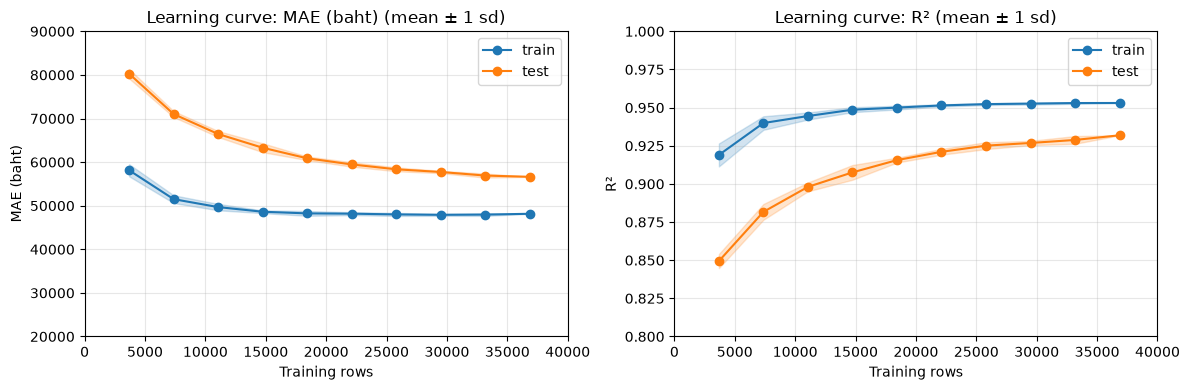

In [40]:
# [40] learning curve: ตารางและกราฟ
# ==================================================
# ทำอะไร: แสดง lc_table จากเซลล์ [39] เป็นตาราง แล้ววาดกราฟ 2 ช่องเคียงกัน (MAE และ R²)
#         แต่ละช่องมีเส้นค่าเฉลี่ยของ train และ test พร้อมแถบ ± 1 sd
# ทำไม: ดูแนวโน้มว่าเมื่อเพิ่มแถวฝึกแล้วคะแนนเปลี่ยนอย่างไร และช่องว่างระหว่าง train กับ test
#       เปลี่ยนอย่างไร
# ผลที่ควรเห็น: ตารางหนึ่งแถวต่อขนาด และกราฟ 2 ช่อง
#   - ถ้า test MAE ยังลดลง (หรือ test R² ยังเพิ่ม) ที่ขนาดมาก ๆ อาจได้ประโยชน์จากข้อมูลเพิ่ม
#   - ถ้า train ดีกว่า test มาก แปลว่าโมเดลจำข้อมูลฝึกได้ดีกว่าข้อมูลใหม่ (อาการ overfit)
#   - แกนถูกล็อกด้วยค่าคงที่ใน [03] (MAE_AXIS, R2_AXIS, ROWS_AXIS) เหมือนกันทั้ง DT / RF / XGB จึงเทียบความสูงข้ามโน้ตบุ๊คได้ตรงๆ
# ข้อควรระวัง:
#   - เป็นหลักฐานเชิงชี้แนะเท่านั้น ไม่ใช่คำยืนยัน
#   - test ใช้อธิบายกราฟเท่านั้น ไม่ใช้เลือกพารามิเตอร์
#   - แถบ ±1 sd คือความแกว่งจากการเลือกชุดย่อยต่างกัน ไม่ใช่ confidence interval
#     (ช่วงความเชื่อมั่น) และไม่รวมความไม่แน่นอนจากการสุ่ม test ชุดใหม่
#   - ที่ขนาดเต็ม ทุกรอบใช้แถวชุดเดียวกัน (แค่เรียงลำดับต่างกัน) จึงได้ sd = 0
#   - ช่องว่าง (gap) ต้องอ่านคู่กับระดับคะแนน ไม่ใช้วัด overfit เพียงลำพัง
#   - ถ้ามีค่านอกแกนที่ล็อกไว้ จะพิมพ์ WARN หลังกราฟ (ไม่ตัดทิ้งเงียบๆ) ให้ขยาย MAE_AXIS, R2_AXIS, ROWS_AXIS ใน [03] ให้เหมือนกันทั้ง 3 โน้ตบุ๊ค
# ==================================================
print("=== [40] learning curve: ตารางและกราฟ ===")

table_formats = {"rows": "{:,.0f}", "repeats": "{:.0f}"}
for column in lc_table.columns:
    if "MAE" in column:
        table_formats[column] = "{:,.0f}"
    elif "R2" in column:
        table_formats[column] = "{:.4f}"

print("อ่านตาราง: ค่าเฉลี่ยและ sd ข้าม 5 รอบ ของ MAE (บาท) และ R² ที่แต่ละจำนวนแถวฝึก")
display(lc_table.style.format(table_formats).hide(axis="index"))

out_of_axis = False
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, ylabel in zip(axes, ["MAE", "R2"], ["MAE (baht)", "R²"]):
    limits = MAE_AXIS if metric == "MAE" else R2_AXIS
    for part in ["train", "test"]:
        mean = lc_table[f"{part} {metric} mean"].to_numpy()
        sd = lc_table[f"{part} {metric} sd"].to_numpy()
        line, = ax.plot(lc_table["rows"], mean, marker="o", label=part)
        ax.fill_between(lc_table["rows"], mean - sd, mean + sd, color=line.get_color(), alpha=0.2)
        if (mean - sd).min() < limits[0] or (mean + sd).max() > limits[1] or lc_table["rows"].max() > ROWS_AXIS[1]:
            out_of_axis = True
    ax.set(xlabel="Training rows", ylabel=ylabel, title=f"Learning curve: {ylabel} (mean ± 1 sd)")
    ax.set_xlim(*ROWS_AXIS)
    ax.set_ylim(*limits)
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

if out_of_axis:
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (learning curve) ให้ขยาย MAE_AXIS / R2_AXIS / ROWS_AXIS ในเซลล์ [03]")

=== [41] ตาราง CV train เทียบ validation ===


อ่านตาราง: หนึ่งแถวต่อ fold, MAE และ RMSE เป็นบาท, MAPE เป็นสัดส่วน (0.10 = 10%), gap = validation - train (R² gap = train - validation)


,train MAE,validation MAE,MAE gap,gap % of validation MAE,train R2,validation R2,R2 gap,train RMSE,validation RMSE,RMSE gap,train MAPE,validation MAPE,MAPE gap
1,"47,784","58,647","10,863",18.52,0.9542,0.9183,0.0359,"70,443","92,701","22,258",0.0937,0.1106,0.0170
2,"48,078","57,724","9,646",16.71,0.9525,0.9266,0.0258,"71,474","89,520","18,046",0.0943,0.1085,0.0142
3,"47,997","57,315","9,318",16.26,0.9528,0.9278,0.0250,"71,394","87,976","16,582",0.0938,0.1097,0.0159
4,"47,679","58,298","10,619",18.21,0.9535,0.9268,0.0267,"70,514","90,126","19,612",0.0938,0.1096,0.0158
5,"48,216","57,673","9,457",16.40,0.9526,0.9261,0.0265,"71,584","88,689","17,104",0.0941,0.1103,0.0161
mean,"47,951","57,931","9,980",17.22,0.9531,0.9251,0.0280,"71,082","89,802","18,721",0.0939,0.1097,0.0158
sd,195,477,634,0.95,0.0007,0.0034,0.0040,497,"1,623","2,047",0.0002,0.0007,0.0009


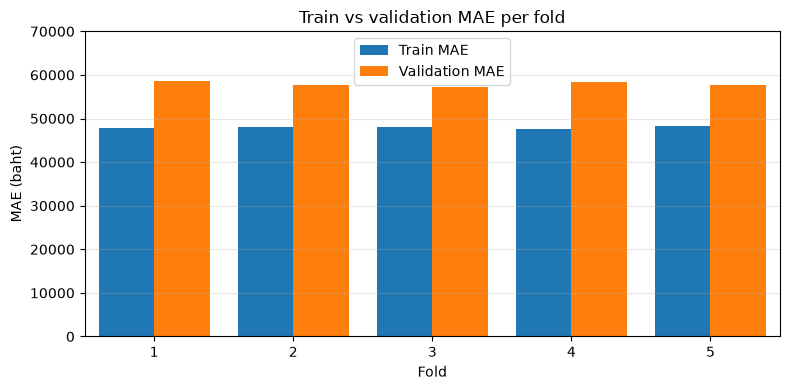

In [41]:
# [41] ตาราง CV train เทียบ validation
# ==================================================
# ทำอะไร: ฝึกโมเดลผู้ชนะใหม่ในแต่ละ fold ของ train แล้วเทียบคะแนนบนแถวที่ใช้ฝึก (train)
#         กับแถวที่กันไว้ตรวจ (validation) ของ fold นั้น ทั้ง MAE, RMSE (บาท), MAPE และ R²
#         (fold = ส่วนย่อยของ train ที่สลับกันเป็นชุดตรวจ, MAE = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ย,
#          RMSE = รากของความคลาดเคลื่อนยกกำลังสองเฉลี่ย (ลงโทษข้อผิดพลาดใหญ่หนักกว่า MAE) หน่วยบาท,
#          MAPE = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ยเป็นสัดส่วนของราคาจริง เช่น 0.10 = 10%,
#          R² = สัดส่วนความผันผวนของราคาที่โมเดลอธิบายได้ 1 = ดีที่สุด)
# ทำไม: ดูขนาดและความสม่ำเสมอของช่องว่างระหว่าง train กับ validation
#       - train ดีกว่า validation มาก อาจเป็นสัญญาณ overfit (จำข้อมูลฝึกมากเกินไป)
#       - ถ้าทั้งสองแย่และใกล้กัน อาจเป็น underfit (โมเดลง่ายเกินไป)
#       เซลล์นี้ไม่ตัดสินให้อัตโนมัติ ให้ดูระดับคะแนนและความกระจายร่วมกัน
#       RMSE และ MAPE อยู่ในตารางนี้เพื่อเทียบกับผล test ที่เซลล์ [37] รายงาน MAE, RMSE, MAPE และ R² (เพิ่มเมื่อ 2026-10-27)
# ผลที่ควรเห็น: ตารางหนึ่งแถวต่อ fold (เลข fold เริ่มที่ 1) คอลัมน์ train MAE, validation MAE,
#              MAE gap (validation - train), gap เป็น % ของ validation MAE, train R²,
#              validation R², R² gap (train - validation), train/validation RMSE กับ RMSE gap,
#              train/validation MAPE กับ MAPE gap (ต่อท้ายตาราง) และท้ายตารางมีแถว mean กับ sd
#              (sd แบบ ddof=0 คำนวณจากแถว fold เท่านั้น) กับกราฟแท่งเทียบ train/validation MAE
#   - แกนถูกล็อกด้วยค่าคงที่ใน [03] (MAE_BAR_AXIS, FOLD_AXIS) เหมือนกันทั้ง DT / RF / XGB จึงเทียบความสูงข้ามโน้ตบุ๊คได้ตรงๆ
# ข้อควรระวัง:
#   - ใช้เฉพาะ train และ folds ไม่ใช้ val หรือ test และเป็นการตรวจผู้ชนะที่เลือกจาก fold เดิม
#     จึงไม่ใช่ผลประเมินอิสระจากการเลือกพารามิเตอร์
#   - ข้อจำกัดของ ccp: CV MAE อาจดีเกินจริงเล็กน้อย เพราะ alpha ถูกสร้างและคัดกรองจาก train
#     ทั้งชุด รวมแถว held-out ของ fold ด้วย ควรใช้ test ที่ยังไม่แตะ (และ val) ตรวจอิสระ
#   - ช่องว่างเป็นอาการที่ต้องอ่านคู่กับระดับ CV และความกระจาย ไม่ใช่มาตรวัด overfit เพียงลำพัง
#   - learning curve (เซลล์ [39]-[40]) เป็นการตรวจที่สาม ช่วยดูว่าเพิ่มแถวฝึกแล้วคะแนนและ
#     ช่องว่างเปลี่ยนอย่างไร ให้หลักฐานเชิงชี้แนะเท่านั้น
#   - ถ้ามีค่านอกแกนที่ล็อกไว้ จะพิมพ์ WARN หลังกราฟ (ไม่ตัดทิ้งเงียบๆ) ให้ขยาย MAE_BAR_AXIS, FOLD_AXIS ใน [03] ให้เหมือนกันทั้ง 3 โน้ตบุ๊ค
# ==================================================
print("=== [41] ตาราง CV train เทียบ validation ===")

scores = cross_validate(
    clone(search.best_estimator_),
    train[features],
    train["price"],
    cv=folds,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "MAPE": "neg_mean_absolute_percentage_error",
        "R2": "r2",
    },
    return_train_score=True,
    n_jobs=SEARCH_JOBS,
    pre_dispatch=SEARCH_JOBS,
    error_score="raise",
)

train_mae = -scores["train_MAE"]  # คะแนนเป็นค่าลบ จึงกลับเครื่องหมายให้เป็น MAE บวก
validation_mae = -scores["test_MAE"]  # "test" ของ sklearn คือแถว validation ใน fold
mae_gap = validation_mae - train_mae
train_rmse = -scores["train_RMSE"]
validation_rmse = -scores["test_RMSE"]
train_mape = -scores["train_MAPE"]  # สัดส่วนของราคาจริง (0.10 = 10%)
validation_mape = -scores["test_MAPE"]

fold_table = pd.DataFrame(
    {
        "train MAE": train_mae,
        "validation MAE": validation_mae,
        "MAE gap": mae_gap,
        "gap % of validation MAE": mae_gap * 100 / validation_mae,
        "train R2": scores["train_R2"],
        "validation R2": scores["test_R2"],
        "R2 gap": scores["train_R2"] - scores["test_R2"],
        "train RMSE": train_rmse,
        "validation RMSE": validation_rmse,
        "RMSE gap": validation_rmse - train_rmse,
        "train MAPE": train_mape,
        "validation MAPE": validation_mape,
        "MAPE gap": validation_mape - train_mape,
    },
    index=pd.Index(range(1, len(train_mae) + 1), name="fold"),
)

summary_rows = pd.DataFrame(
    [fold_table.mean(), fold_table.std(ddof=0)],
    index=["mean", "sd"],
)
cv_check_table = pd.concat([fold_table, summary_rows])

table_formats = {
    "train MAE": "{:,.0f}",
    "validation MAE": "{:,.0f}",
    "MAE gap": "{:,.0f}",
    "gap % of validation MAE": "{:.2f}",
    "train R2": "{:.4f}",
    "validation R2": "{:.4f}",
    "R2 gap": "{:.4f}",
    "train RMSE": "{:,.0f}",
    "validation RMSE": "{:,.0f}",
    "RMSE gap": "{:,.0f}",
    "train MAPE": "{:.4f}",
    "validation MAPE": "{:.4f}",
    "MAPE gap": "{:.4f}",
}
print("อ่านตาราง: หนึ่งแถวต่อ fold, MAE และ RMSE เป็นบาท, MAPE เป็นสัดส่วน (0.10 = 10%), gap = validation - train (R² gap = train - validation)")
display(cv_check_table.style.format(table_formats))

positions = np.arange(len(fold_table))
bar_width = 0.4
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(positions - bar_width / 2, fold_table["train MAE"], bar_width, label="Train MAE")
ax.bar(positions + bar_width / 2, fold_table["validation MAE"], bar_width, label="Validation MAE")
ax.set_xticks(positions, fold_table.index)
ax.set(xlabel="Fold", ylabel="MAE (baht)", title="Train vs validation MAE per fold")
ax.set_xlim(*FOLD_AXIS)
ax.set_ylim(*MAE_BAR_AXIS)
ax.grid(True, axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

if (
    fold_table[["train MAE", "validation MAE"]].max().max() > MAE_BAR_AXIS[1]
    or len(fold_table) - 1 + bar_width > FOLD_AXIS[1]
):
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (กราฟแท่ง CV train เทียบ validation) ให้ขยาย MAE_BAR_AXIS / FOLD_AXIS ในเซลล์ [03]")

In [42]:
# [42] validation curve: คำนวณ
# ==================================================
# ทำอะไร: สร้าง validation curve ของทุกพารามิเตอร์ที่ปรับ (max_depth, min_samples_leaf, ccp_alpha)
#         คือเปลี่ยนพารามิเตอร์ทีละตัวตามทุกค่าใน PARAM_GRID โดยคงพารามิเตอร์ตัวอื่นไว้ตามผู้ชนะ
#         แล้วเก็บ MAE บนส่วนฝึกและส่วนตรวจสอบ (validation) ของแต่ละ fold ลง vc_results
#         (validation curve = กราฟคะแนนเมื่อเปลี่ยนพารามิเตอร์หนึ่งตัว,
#          fold = ส่วนย่อยของ train ที่สลับกันเป็นชุดตรวจ,
#          MAE = ความคลาดเคลื่อนสัมบูรณ์เฉลี่ย หน่วยบาท,
#          sd = ส่วนเบี่ยงเบนมาตรฐานข้าม fold แบบ ddof=0)
# ทำไม: ดูว่าพารามิเตอร์แต่ละตัวทำให้โมเดลซับซ้อนขึ้น/ง่ายลงแล้ว MAE ฝึกกับ MAE ตรวจสอบ
#       ห่างกันอย่างไร เพื่ออ่านความซับซ้อนร่วมกับช่องว่างของคะแนน
#   - max_depth และ min_samples_leaf ใช้ validation_curve ตามปกติ เพราะ PARAM_GRID มีเพียง
#     ไม่กี่ค่า และคะแนนที่ได้ยังไม่ถูกเก็บไว้ที่อื่น
#   - ccp_alpha ไม่ต้องฝึกใหม่: ผลของคู่ผู้ชนะถูกคำนวณไว้ครบทุก alpha ใน ccp_cv แล้ว (เซลล์ [26])
#     จึงอ่าน train / CV MAE mean และ SD จากตารางนั้นโดยตรง (ประหยัดการฝึกหลายพันครั้ง)
# ผลที่ควรเห็น: ข้อความหนึ่งบรรทัดต่อพารามิเตอร์ จากนั้น vc_results พร้อมให้เซลล์ [43]
#              แสดงตารางและกราฟ (ไม่มีผลลัพธ์อื่นในเซลล์นี้)
# ข้อควรระวัง:
#   - ใช้ผลของ train กับ folds เดิมเท่านั้น ไม่เปลี่ยน search
#   - ค่าของ max_depth และ min_samples_leaf คือทุกค่าใน PARAM_GRID ตามลำดับเดิม
#     ส่วน ccp_alpha คือทุก alpha ของคู่ผู้ชนะ เรียงจากน้อยไปมาก
# ==================================================
print("=== [42] validation curve: คำนวณ ===")

vc_results = {}
for name in ["max_depth", "min_samples_leaf"]:
    values = list(PARAM_GRID[name])
    train_scores, valid_scores = validation_curve(
        clone(search.best_estimator_),
        train[features],
        train["price"],
        param_name="model__" + name,
        param_range=values,
        cv=folds,
        scoring="neg_mean_absolute_error",
        n_jobs=SEARCH_JOBS,
        pre_dispatch=SEARCH_JOBS,
        error_score="raise",
    )
    train_mae = -train_scores  # หนึ่งแถวต่อค่า หนึ่งคอลัมน์ต่อ fold
    valid_mae = -valid_scores
    vc_results[name] = {
        "values": values,
        "train_mean": train_mae.mean(axis=1),
        "train_sd": train_mae.std(axis=1, ddof=0),
        "cv_mean": valid_mae.mean(axis=1),
        "cv_sd": valid_mae.std(axis=1, ddof=0),
    }
    print(f"{name} เสร็จ ({len(values)} ค่า)")

# ccp_alpha: อ่านจากผล joint search ของคู่ผู้ชนะ ไม่ฝึกใหม่
winner_curve = ccp_cv[ccp_cv["pair"] == winner_pair_index].sort_values("alpha")
vc_results["ccp_alpha"] = {
    "values": winner_curve["alpha"].to_numpy(dtype=float),
    "train_mean": winner_curve["train_mae_mean"].to_numpy(dtype=float),
    "train_sd": winner_curve["train_mae_sd"].to_numpy(dtype=float),
    "cv_mean": winner_curve["cv_mae_mean"].to_numpy(dtype=float),
    "cv_sd": winner_curve["cv_mae_sd"].to_numpy(dtype=float),
}
print(f"ccp_alpha เสร็จ ({len(winner_curve)} ค่า อ่านจากผล joint search ไม่ฝึกใหม่)")


=== [42] validation curve: คำนวณ ===


max_depth เสร็จ (5 ค่า)


min_samples_leaf เสร็จ (6 ค่า)
ccp_alpha เสร็จ (4102 ค่า อ่านจากผล joint search ไม่ฝึกใหม่)


=== [43] validation curve: ตารางและกราฟ ===
อ่านตาราง max_depth: MAE เป็นบาท, gap = CV MAE - train MAE (ยิ่งกว้างยิ่งเสี่ยง overfit)


value,train MAE mean,CV MAE mean,CV MAE sd,gap
10,"76,410","80,377",852,"3,966"
15,"55,261","62,146","1,010","6,885"
20,"49,023","58,246",606,"9,223"
25,"47,951","57,931",477,"9,980"
None,"47,855","57,973",506,"10,118"


อ่านตาราง min_samples_leaf: MAE เป็นบาท, gap = CV MAE - train MAE (ยิ่งกว้างยิ่งเสี่ยง overfit)


value,train MAE mean,CV MAE mean,CV MAE sd,gap
1,"38,325","58,655",424,"20,330"
5,"47,951","57,931",477,"9,980"
7,"50,261","58,645",474,"8,384"
9,"52,054","59,487",646,"7,433"
12,"54,266","60,619",628,"6,352"
15,"56,439","62,101",757,"5,662"


อ่านตาราง ccp_alpha (ตัวอย่าง 12 จาก 4102 ค่า): MAE เป็นบาท, gap = CV MAE - train MAE (ยิ่งกว้างยิ่งเสี่ยง overfit)


value,train MAE mean,CV MAE mean,CV MAE sd,gap
0.000e+00,"44,400","58,637",499,"14,237"
9.562e+03,"44,417","58,622",504,"14,205"
2.559e+04,"44,488","58,605",499,"14,117"
4.846e+04,"44,647","58,546",476,"13,900"
8.121e+04,"44,943","58,456",446,"13,513"
1.325e+05,"45,415","58,283",467,"12,867"
2.113e+05,"46,085","58,112",427,"12,027"
3.550e+05,"47,169","58,015",436,"10,846"
6.882e+05,"48,843","58,004",583,"9,160"
1.516e+06,"51,579","58,834",459,"7,254"


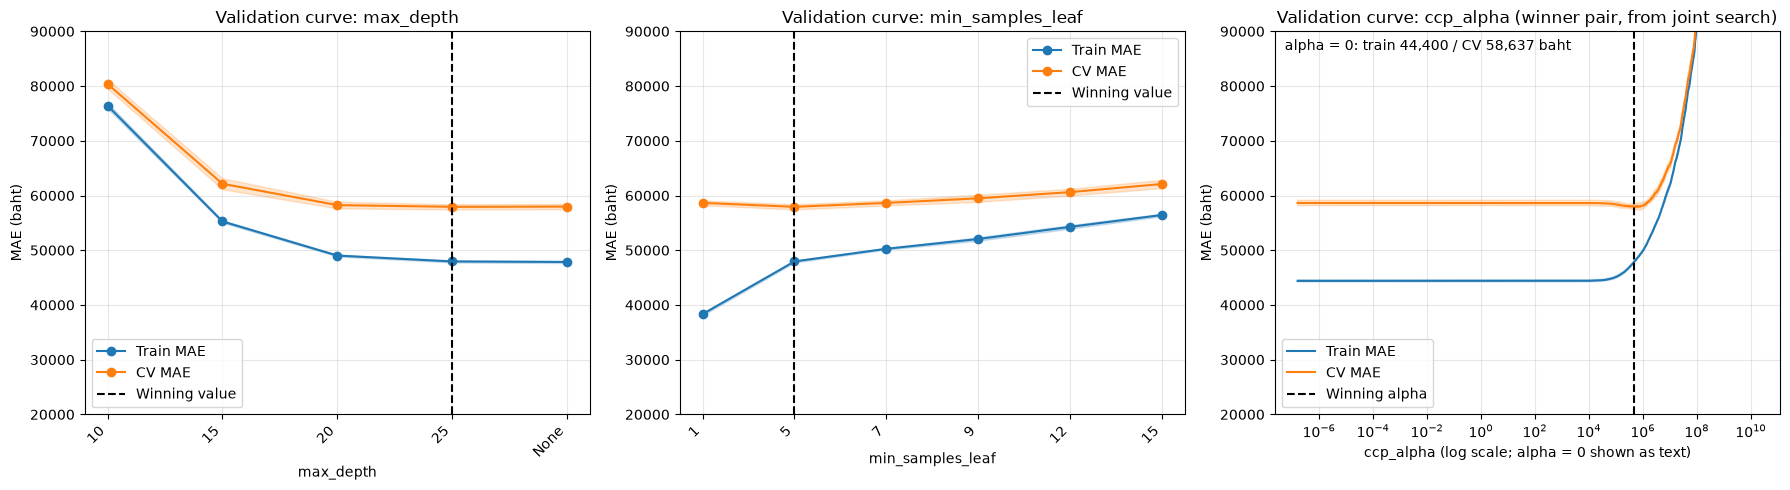

WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (validation curve) ให้ขยาย MAE_AXIS ในเซลล์ [03]


In [43]:
# [43] validation curve: ตารางและกราฟ
# ==================================================
# ทำอะไร: แสดงตารางของแต่ละพารามิเตอร์จาก vc_results (เซลล์ [42]) แล้ววาดกราฟ 3 ช่องเคียงกัน
#         เส้น train และ CV MAE เฉลี่ย พร้อมแถบ ± 1 sd และเส้นประแนวตั้งที่ค่าของผู้ชนะ
# ทำไม: ดูว่าพารามิเตอร์แต่ละตัวพาโมเดลไปทาง overfit หรือ underfit
#       (overfit = จำข้อมูลฝึกมากเกินจนใช้กับข้อมูลใหม่ไม่ดี, underfit = ง่ายเกินจนจับแบบแผนไม่ได้)
# วิธีอ่าน:
#   - max_depth และ min_samples_leaf: ตำแหน่ง x เรียงตามลำดับค่าใน PARAM_GRID
#     (ไม่ใช่ระยะห่างจริง) เพราะมีค่า None ปนอยู่
#   - ccp_alpha: แกน x เป็นสเกล log ตามค่าจริงของ alpha (alpha = 0 เขียนเป็นข้อความบนกราฟ)
#     alpha เล็ก = ต้นไม้ซับซ้อน alpha ใหญ่ = ต้นไม้เล็ก
#   - overfit: train MAE ต่ำมากแต่ CV MAE สูงกว่ามาก (ช่องว่างกว้าง) มักเกิดทางด้านซับซ้อน
#   - underfit: ทั้ง train และ CV MAE สูงและใกล้กัน มักเกิดทางด้านง่าย
#   - ผู้ชนะ (เส้นประ) อยู่ที่ค่าที่ CV MAE ต่ำสุดของแต่ละพารามิเตอร์ เพราะผู้ชนะเลือกจาก CV MAE
# ผลที่ควรเห็น: ตารางของ max_depth และ min_samples_leaf (คอลัมน์ value, train MAE mean,
#              CV MAE mean, CV MAE sd, gap โดย gap = CV MAE - train MAE) และตารางตัวอย่าง
#              ของ ccp_alpha (หลายพันค่า จึงแสดงเฉพาะบางจุดที่เว้นระยะบนสเกล log)
#              กับรูปเดียวที่มี 3 กราฟ
#   - แกนถูกล็อกด้วยค่าคงที่ใน [03] (MAE_AXIS) เหมือนกันทั้ง DT / RF / XGB
# ข้อควรระวัง: ตารางและกราฟนี้ใช้ train กับ folds เดิม จึงไม่ใช่ผลประเมินอิสระ
#   - ถ้ามีค่านอกแกนที่ล็อกไว้ จะพิมพ์ WARN หลังกราฟ (ไม่ตัดทิ้งเงียบๆ) ให้ขยาย MAE_AXIS ใน [03]
# ==================================================
print("=== [43] validation curve: ตารางและกราฟ ===")

parameter_names = ["max_depth", "min_samples_leaf", "ccp_alpha"]

for name in parameter_names:
    result = vc_results[name]
    value_labels = []
    for value in result["values"]:
        if name == "ccp_alpha":
            value_labels.append(f"{value:.3e}")
        else:
            value_labels.append(str(value))  # None แสดงเป็น "None"
    table = pd.DataFrame(
        {
            "value": value_labels,
            "train MAE mean": result["train_mean"],
            "CV MAE mean": result["cv_mean"],
            "CV MAE sd": result["cv_sd"],
            "gap": result["cv_mean"] - result["train_mean"],
        }
    )
    if name == "ccp_alpha" and len(table) > 12:
        # ตารางมีหลายพันแถว จึงแสดงเฉพาะตัวอย่างที่เว้นระยะเท่ากันบนสเกล log
        positions = np.unique(np.linspace(0, len(table) - 1, 12).astype(int))
        table = table.iloc[positions]
        note = f" (ตัวอย่าง {len(table)} จาก {len(result['values'])} ค่า)"
    else:
        note = ""
    print(f"อ่านตาราง {name}{note}: MAE เป็นบาท, gap = CV MAE - train MAE (ยิ่งกว้างยิ่งเสี่ยง overfit)")
    display(
        table.style
        .format(
            {
                "train MAE mean": "{:,.0f}",
                "CV MAE mean": "{:,.0f}",
                "CV MAE sd": "{:,.0f}",
                "gap": "{:,.0f}",
            }
        )
        .hide(axis="index")
    )

out_of_axis = False
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, name in zip(axes[:2], parameter_names[:2]):
    result = vc_results[name]
    values = result["values"]
    positions = np.arange(len(values))  # ใช้ตำแหน่งแทนค่าจริง เพื่อแสดง None ได้
    tick_labels = ["None" if value is None else str(value) for value in values]

    for mean, sd, label in [
        (result["train_mean"], result["train_sd"], "Train MAE"),
        (result["cv_mean"], result["cv_sd"], "CV MAE"),
    ]:
        line, = ax.plot(positions, mean, marker="o", label=label)
        ax.fill_between(positions, mean - sd, mean + sd, color=line.get_color(), alpha=0.2)
        if (mean - sd).min() < MAE_AXIS[0] or (mean + sd).max() > MAE_AXIS[1]:
            out_of_axis = True

    winner_value = search.best_params_["model__" + name]
    ax.axvline(values.index(winner_value), color="black", linestyle="--", label="Winning value")
    ax.set_xticks(positions, tick_labels, rotation=45, ha="right")
    ax.set(xlabel=name, ylabel="MAE (baht)", title=f"Validation curve: {name}")
    ax.set_ylim(*MAE_AXIS)
    ax.grid(True, alpha=0.3)
    ax.legend()

# ช่องที่ 3: ccp_alpha บนสเกล log (alpha = 0 วาดไม่ได้ จึงเขียนเป็นข้อความ)
ax = axes[2]
result = vc_results["ccp_alpha"]
values = result["values"]
positive = values > 0
for mean, sd, label in [
    (result["train_mean"], result["train_sd"], "Train MAE"),
    (result["cv_mean"], result["cv_sd"], "CV MAE"),
]:
    line, = ax.plot(values[positive], mean[positive], label=label)
    ax.fill_between(values[positive], (mean - sd)[positive], (mean + sd)[positive],
                    color=line.get_color(), alpha=0.2)
    if positive.any() and (mean[positive] - sd[positive]).min() < MAE_AXIS[0]:
        out_of_axis = True
    if positive.any() and (mean[positive] + sd[positive]).max() > MAE_AXIS[1]:
        out_of_axis = True
if result["cv_mean"].min() < MAE_AXIS[0] or result["cv_mean"].max() > MAE_AXIS[1]:
    out_of_axis = True
ax.text(
    0.02, 0.98,
    f"alpha = 0: train {result['train_mean'][0]:,.0f} / CV {result['cv_mean'][0]:,.0f} baht",
    transform=ax.transAxes, va="top",
)
winner_alpha = search.best_params_["model__ccp_alpha"]
if winner_alpha > 0:
    ax.axvline(winner_alpha, color="black", linestyle="--", label="Winning alpha")
else:
    ax.text(0.02, 0.90, "winning alpha = 0", transform=ax.transAxes, va="top")
ax.set_xscale("log")
ax.set(
    xlabel="ccp_alpha (log scale; alpha = 0 shown as text)",
    ylabel="MAE (baht)",
    title="Validation curve: ccp_alpha (winner pair, from joint search)",
)
ax.set_ylim(*MAE_AXIS)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

if out_of_axis:
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (validation curve) ให้ขยาย MAE_AXIS ในเซลล์ [03]")


In [44]:
# [44] สรุปการตรวจ overfit
# ==================================================
# ทำอะไร: รวมหลักฐานเรื่อง overfit ของโมเดลผู้ชนะไว้ที่เดียว แล้วพิมพ์ PASS หรือ WARN ทีละข้อพร้อมเกณฑ์
#   1) เทียบ MAE ที่ประเมินจากฝั่ง train (CV จากเซลล์ [33]) กับ MAE บนข้อมูลที่ไม่เคยแตะเลย
#      (validation และ test จากเซลล์ [36]) และเทียบ validation กับ test
#   2) learning curve (เซลล์ [39]-[40]): เมื่อแถวฝึกมากขึ้น test MAE ต้องลดลง และช่องว่าง train-test
#      ต้องแคบลง
#   3) INFO: train MAE เทียบ CV MAE (พิมพ์ให้ดูเฉยๆ ไม่นับเป็น WARN เหตุผลอยู่ด้านล่าง)
# ทำไม:
#   - overfit คือโมเดลจำข้อมูลฝึกจนทายข้อมูลใหม่แย่ลง ถ้าเกิดขึ้น (หรือถ้าการเลือกพารามิเตอร์ไปเข้าข้าง
#     ความบังเอิญของ fold) MAE บน validation / test จะสูงกว่าค่าที่ประเมินจากฝั่ง train อย่างชัดเจน
#     CV วัดบนแถวที่โมเดลตัวนั้นไม่ได้ฝึก จึงควรตรงกับ validation / test ถ้าไม่ overfit
#   - เกณฑ์ "ต่างกันได้ไม่เกิน 2 SE": MAE ที่วัดจากรถ n คันมีความคลาดเคลื่อนจากการสุ่มว่ารถคันไหนตกอยู่
#     ในชุดนั้น เรียกว่า SE (standard error) = sd ของ |ทายผิด| / sqrt(n) ส่วน SE ของ CV ใช้
#     std ของ MAE ราย fold / sqrt(จำนวน fold) ผลต่างของค่าประมาณสองค่ามี
#     SE = sqrt(SE1² + SE2²) ถ้าต่างกันเกิน 2 เท่าของค่านี้ (ราว 95% ของความต่างที่เกิดจากการสุ่มล้วนๆ
#     จะไม่เกินระยะนี้ ตามการประมาณแบบการแจกแจงปกติ) จึงไม่น่าใช่แค่ความบังเอิญ ให้ WARN
#     เกณฑ์คิดจากข้อมูลจริงทุกครั้ง ไม่ได้ตั้งเลขตายตัว
#   - ทิศของความต่าง: validation / test แย่กว่าเกินเกณฑ์ = สัญญาณ overfit
#     (ค่าที่ประเมินจากฝั่ง train มองโลกในแง่ดีเกินไป) ส่วน validation / test ดีกว่าเกินเกณฑ์
#     ไม่ใช่ overfit แต่ควรหาสาเหตุ เช่น แถวที่ค่าเหมือนกันข้ามชุด (ต่างกันแค่สี ดูเซลล์ [13])
#     ทำให้ชุดนั้นง่ายขึ้นเล็กน้อย
#   - ความต่างเล็กๆ ที่คาดได้ล่วงหน้า: โมเดลสุดท้ายฝึกบน train ทั้งชุด (CV ฝึกบน 4/5)
#     จึงมักดีกว่า CV นิดหน่อย และ CV MAE ของผู้ชนะที่ถูกเลือกจากทุกคู่ x ทุก alpha อาจดีเกินจริงเล็กน้อย
#     ยังมีอีกข้อ: รายการ alpha ของแต่ละคู่สร้างจากต้นไม้ที่ฝึกบน train ทั้งชุด (เซลล์ [23])
#     ซึ่งรวมแถวที่แต่ละ fold กันไว้ CV MAE จึงอาจดีเกินจริงเพิ่มอีกนิด
#     ทำให้ validation / test แย่กว่า CV เล็กน้อยได้ เกณฑ์ 2 SE ช่วยแยกความต่างระดับนี้ออกจากของจริง
#   - learning curve: โมเดลที่ไม่ overfit จะทายข้อมูลใหม่ดีขึ้นเมื่อมีข้อมูลฝึกมากขึ้น และช่องว่าง
#     train-test แคบลง ถ้าช่องว่างกว้างขึ้นหรือ test MAE ไม่ลดลง ถือว่าผิดปกติ ให้ WARN
#   - ความจริงเฉพาะของต้นไม้ต้นเดียว: ต้นไม้ที่ใบเล็ก (min_samples_leaf น้อย ไม่ตัดกิ่ง) จำแถวฝึกได้เกือบหมด
#     train MAE จึงต่ำกว่า CV MAE มากเป็นปกติ ช่องว่างนี้ลำพังไม่ใช่ overfit
#     (ถ้าต้นไม้ overfit จริง CV / validation / test จะแย่ลงด้วย ซึ่งข้อ 1 ตรวจอยู่แล้ว)
#     ccp_alpha ช่วยให้ต้นไม้เล็กลง จึงพิมพ์อัตราส่วน train / CV ไว้ให้ดูเป็น INFO
# ผลที่ควรเห็น: ตารางย่อ MAE ± SE ของ CV, validation, test แล้วบรรทัด PASS/WARN 4 บรรทัด
#       (validation เทียบ CV, test เทียบ CV, test เทียบ validation, learning curve)
#       บรรทัด INFO 1 บรรทัด และบรรทัดสรุปสุดท้าย
# ข้อควรระวัง: PASS ทุกข้อแปลว่า "ไม่พบหลักฐาน overfit" ตามเกณฑ์เหล่านี้ ไม่ใช่การพิสูจน์ว่าไม่มีเลย
#       และ test ใช้ตรวจอย่างเดียว ห้ามย้อนกลับไปปรับโมเดลตามผลนี้
# ==================================================
print("=== [44] สรุปการตรวจ overfit ===")

estimates = {
    "CV": (cv_mae_all[chosen_index], cv_results["std_test_MAE"][chosen_index] / np.sqrt(n_splits)),
}
for name, part in [("validation", val), ("test", test)]:
    errors = np.abs(part["price"].to_numpy() - model.predict(part[features]))
    estimates[name] = (errors.mean(), errors.std(ddof=1) / np.sqrt(len(errors)))

print("MAE ของโมเดลผู้ชนะจากแต่ละแหล่ง (± SE)")
for name, (mae, standard_error) in estimates.items():
    print(f"  {name:<10}: {mae:,.0f} ± {standard_error:,.0f} บาท")

warn_count = 0
comparisons = [
    ("validation", "CV"),
    ("test", "CV"),
    ("test", "validation"),
]
for held_out, reference in comparisons:
    held_out_mae, held_out_se = estimates[held_out]
    reference_mae, reference_se = estimates[reference]
    difference = held_out_mae - reference_mae
    band = 2 * np.sqrt(held_out_se**2 + reference_se**2)
    if abs(difference) <= band:
        status = "PASS"
    else:
        status = "WARN"
        warn_count = warn_count + 1
    label = f"{held_out} เทียบ {reference}"
    print(
        f"{status} {label:<24}: ต่างกัน {difference:+,.0f} บาท "
        f"({difference * 100 / reference_mae:+.2f}%) เกณฑ์ ±{band:,.0f} บาท (2 SE)"
    )

first = lc_table.iloc[0]
last = lc_table.iloc[-1]
first_gap = first["test MAE mean"] - first["train MAE mean"]
last_gap = last["test MAE mean"] - last["train MAE mean"]
if last["test MAE mean"] < first["test MAE mean"] and last_gap < first_gap:
    status = "PASS"
else:
    status = "WARN"
    warn_count = warn_count + 1
print(
    f"{status} learning curve ({int(first['rows']):,} -> {int(last['rows']):,} แถว): "
    f"test MAE {first['test MAE mean']:,.0f} -> {last['test MAE mean']:,.0f} บาท, "
    f"gap {first_gap:,.0f} -> {last_gap:,.0f} บาท (ต้องลดลงทั้งคู่)"
)

train_ratio = results["train"]["MAE"] / estimates["CV"][0]
print(
    f"INFO train MAE {results['train']['MAE']:,.0f} บาท = {train_ratio:.4f} เท่าของ CV MAE "
    "(ต่ำกว่ามากเป็นปกติของต้นไม้ที่ใบเล็ก ไม่นับเป็น WARN)"
)

if warn_count == 0:
    print("สรุป: PASS ทุกข้อ ไม่พบหลักฐานว่าโมเดล overfit ตามเกณฑ์ของเซลล์นี้")
else:
    print(f"สรุป: มี WARN {warn_count} ข้อ อ่านคำอธิบายทิศของความต่างที่หัวเซลล์ก่อนนำโมเดลไปใช้")


=== [44] สรุปการตรวจ overfit ===
MAE ของโมเดลผู้ชนะจากแต่ละแหล่ง (± SE)
  CV        : 57,931 ± 213 บาท
  validation: 57,584 ± 1,024 บาท
  test      : 56,628 ± 946 บาท
PASS validation เทียบ CV     : ต่างกัน -348 บาท (-0.60%) เกณฑ์ ±2,093 บาท (2 SE)
PASS test เทียบ CV           : ต่างกัน -1,303 บาท (-2.25%) เกณฑ์ ±1,940 บาท (2 SE)
PASS test เทียบ validation   : ต่างกัน -955 บาท (-1.66%) เกณฑ์ ±2,789 บาท (2 SE)
PASS learning curve (3,685 -> 36,859 แถว): test MAE 80,265 -> 56,628 บาท, gap 22,135 -> 8,479 บาท (ต้องลดลงทั้งคู่)
INFO train MAE 48,149 บาท = 0.8311 เท่าของ CV MAE (ต่ำกว่ามากเป็นปกติของต้นไม้ที่ใบเล็ก ไม่นับเป็น WARN)
สรุป: PASS ทุกข้อ ไม่พบหลักฐานว่าโมเดล overfit ตามเกณฑ์ของเซลล์นี้


=== [45] ความสำคัญแบบ permutation บน test ===


Permutation importance: increase in test MAE (baht)
variable        mean       std  share (%)
  engine 136918.1541 1808.3777    29.5761
 car_age 126352.6484 2324.7596    27.2938
car_type  60852.6672 1434.3540    13.1449
   brand  55511.1800 1094.0317    11.9911
   model  41819.1142  781.8213     9.0335
 mileage  18539.1627  629.7479     4.0047
    fuel  16336.4161  855.6557     3.5289
    gear   6606.4380  278.9019     1.4271


,variable,mean,std,share (%)
0,engine,136918.154101,1808.377673,29.576058
1,car_age,126352.648352,2324.759611,27.293775
2,car_type,60852.667173,1434.354019,13.144948
3,brand,55511.180018,1094.031699,11.991119
4,model,41819.114157,781.821313,9.033459
5,mileage,18539.162710,629.747914,4.004694
6,fuel,16336.416100,855.655696,3.528873
7,gear,6606.437987,278.901893,1.427074


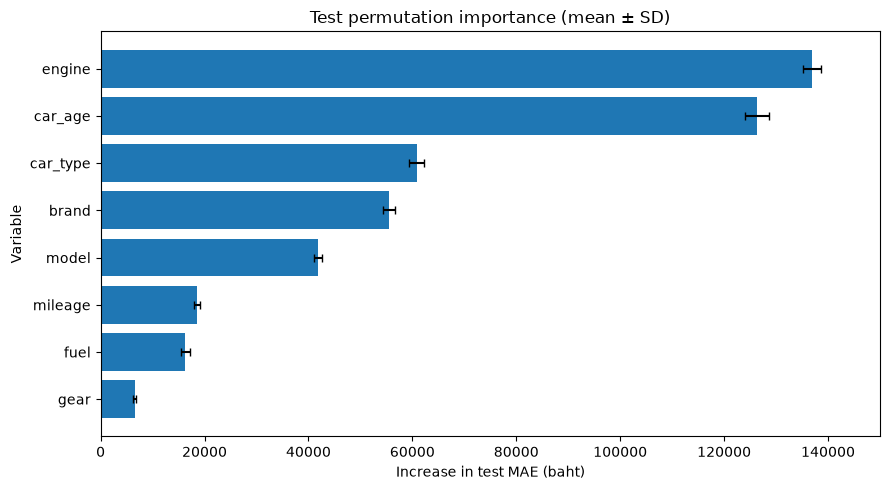

In [45]:
# [45] ความสำคัญแบบ permutation บน test
# ==================================================
# ทำอะไร: สลับตัวแปรต้นฉบับทีละคอลัมน์ก่อน encoding สิบรอบแล้ววัด MAE ที่เพิ่มเป็นบาท
# ทำไม: ใช้ข้อมูลและกติกาเดียวกันเพื่อเปรียบเทียบการทดลองได้อย่างเป็นธรรม
# ผลที่ควรเห็น: ตารางผลที่คำนวณจริงและกราฟที่มีข้อความภาษาอังกฤษ
# ข้อควรระวัง: ค่าติดลบเกิดได้; share ใช้ผลรวมมีเครื่องหมาย ไม่ตัดค่าลบทิ้ง; ถ้าผลรวมศูนย์ให้ share เป็นศูนย์
# ==================================================
print("=== [45] ความสำคัญแบบ permutation บน test ===")

importance_estimator = search.best_estimator_
X_test = test[features]
y_test = test["price"]
assert len(features) == 8 and list(X_test.columns) == features
permutation_result = permutation_importance(
    importance_estimator, X_test, y_test, scoring="neg_mean_absolute_error",
    n_repeats=10, random_state=SEED,
)
permutation_table = pd.DataFrame({"variable": features, "mean": permutation_result.importances_mean,
                                  "std": permutation_result.importances_std})
# ใช้ผลรวมแบบมีเครื่องหมาย ค่าลบหมายถึงสลับแล้วดีขึ้น; ถ้าผลรวมเป็นศูนย์ให้ share เป็นศูนย์
total_increase = permutation_table["mean"].sum()
permutation_table["share (%)"] = (100 * permutation_table["mean"] / total_increase
                                   if total_increase != 0 else 0.0)
permutation_table = permutation_table.sort_values("mean", ascending=False, kind="stable").reset_index(drop=True)
print("Permutation importance: increase in test MAE (baht)")
print(permutation_table.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
display(permutation_table)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(permutation_table["variable"], permutation_table["mean"], xerr=permutation_table["std"], capsize=3)
ax.invert_yaxis()
ax.set(xlabel="Increase in test MAE (baht)", ylabel="Variable", title="Test permutation importance (mean ± SD)")
ax.set_xlim(*PERM_AXIS)
plt.tight_layout()
plt.show()
if ((permutation_table["mean"] - permutation_table["std"]).min() < PERM_AXIS[0]
        or (permutation_table["mean"] + permutation_table["std"]).max() > PERM_AXIS[1]):
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (permutation importance) ให้ขยาย PERM_AXIS ในเซลล์ [03]")


=== [46] ความสำคัญจากโมเดลรวมกลับเป็นตัวแปร ===
Model-based importance: gain (XGB) or mean decrease of impurity (DT/RF)
variable  model_based
 car_age     0.261728
  engine     0.209321
car_type     0.155496
   model     0.139061
   brand     0.137702
 mileage     0.058465
    fuel     0.029686
    gear     0.008540


,variable,model_based
2,car_age,0.261728
0,engine,0.209321
5,car_type,0.155496
4,model,0.139061
3,brand,0.137702
1,mileage,0.058465
6,fuel,0.029686
7,gear,0.008540


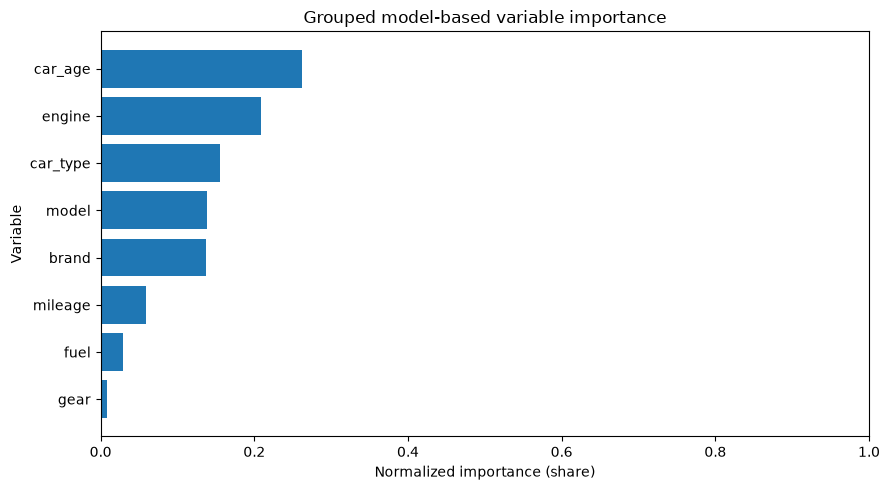

In [46]:
# [46] ความสำคัญจากโมเดลรวมกลับเป็นตัวแปร
# ==================================================
# ทำอะไร: รวม impurity หรือ gain ของ dummy กลับเป็นแปดตัวแปรและ normalize ให้รวมเป็นหนึ่ง
# ทำไม: ใช้ข้อมูลและกติกาเดียวกันเพื่อเปรียบเทียบการทดลองได้อย่างเป็นธรรม
# ผลที่ควรเห็น: ตารางผลที่คำนวณจริงและกราฟที่มีข้อความภาษาอังกฤษ
# ข้อควรระวัง: ใช้ผู้ชนะที่ fit บน train แล้ว; gain ขอผ่าน booster อย่างชัดเจน; ระดับมากอาจได้เปรียบ
# ==================================================
print("=== [46] ความสำคัญจากโมเดลรวมกลับเป็นตัวแปร ===")

fitted_model = importance_estimator.named_steps["model"]
if isinstance(fitted_model, TransformedTargetRegressor):
    fitted_model = fitted_model.regressor_
encoded_names = importance_estimator.named_steps["encode"].get_feature_names_out()
if MODEL_NAME == "XGB":
    # ขอ gain อย่างชัดเจนและจับคู่ชื่อตามลำดับจริงของ encoder (รองรับทั้งชื่อจริงและ f0, f1)
    booster = fitted_model.get_booster()
    gains = booster.get_score(importance_type="gain")
    booster_names = booster.feature_names
    if booster_names is None:
        booster_names = [f"f{i}" for i in range(len(encoded_names))]
    else:
        assert booster_names == list(encoded_names), "Booster feature order differs from encoder output"
    assert len(booster_names) == len(encoded_names)
    assert set(gains).issubset(booster_names), "Unknown booster feature name"
    weights = np.asarray([gains.get(name, 0.0) for name in booster_names], dtype=float)
else:
    weights = np.asarray(fitted_model.feature_importances_, dtype=float)
assert len(weights) == len(encoded_names)
grouped_importance = {name: 0.0 for name in features}
for encoded_name, weight in zip(encoded_names, weights):
    original_name = str(encoded_name).split("=", 1)[0]
    assert original_name in grouped_importance, f"Unknown encoded variable: {encoded_name}"
    grouped_importance[original_name] += float(weight)
total_weight = sum(grouped_importance.values())
assert total_weight > 0, "โมเดลไม่มีความสำคัญที่เป็นบวกให้ normalize"
grouped_importance = {name: weight / total_weight for name, weight in grouped_importance.items()}
assert np.isclose(sum(grouped_importance.values()), 1.0)
model_importance_table = pd.DataFrame({"variable": features,
    "model_based": [grouped_importance[name] for name in features]}).sort_values("model_based", ascending=False, kind="stable")
print("Model-based importance: gain (XGB) or mean decrease of impurity (DT/RF)")
print(model_importance_table.to_string(index=False, float_format=lambda value: f"{value:.6f}"))
display(model_importance_table)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(model_importance_table["variable"], model_importance_table["model_based"])
ax.invert_yaxis()
ax.set(xlabel="Normalized importance (share)", ylabel="Variable", title="Grouped model-based variable importance")
ax.set_xlim(*SHARE_AXIS)
plt.tight_layout()
plt.show()
if (model_importance_table["model_based"].min() < SHARE_AXIS[0]
        or model_importance_table["model_based"].max() > SHARE_AXIS[1]):
    print("WARN: ค่าบางจุดอยู่นอกแกนที่ล็อกไว้ (model importance) ให้ขยาย SHARE_AXIS ในเซลล์ [03]")


In [47]:
# [47] เปรียบเทียบอันดับและพิมพ์ IMPORTANCE_JSON
# ==================================================
# ทำอะไร: แสดงความสำคัญและอันดับทั้งสองวิธีเคียงกันแล้วพิมพ์ JSON หนึ่งบรรทัด
# ทำไม: ใช้ข้อมูลและกติกาเดียวกันเพื่อเปรียบเทียบการทดลองได้อย่างเป็นธรรม
# ผลที่ควรเห็น: ตารางผลที่คำนวณจริงและกราฟที่มีข้อความภาษาอังกฤษ
# ข้อควรระวัง: เมื่อผลสองวิธีขัดกันควรเชื่อ permutation บนข้อมูลที่ไม่เคยเห็นมากกว่า
# ==================================================
print("=== [47] เปรียบเทียบอันดับและพิมพ์ IMPORTANCE_JSON ===")

# impurity/gain เอนเอียงไปหาตัวแปรที่มีหลายระดับ เช่น model ซึ่งมี dummy หลายร้อยตัว และคำนวณจากแถวฝึก
# permutation วัดว่า error เพิ่มบนแถวที่ไม่เคยเห็นเท่าใด เมื่อสองวิธีขัดกันควรเชื่อ permutation มากกว่า
importance_comparison = permutation_table.merge(model_importance_table, on="variable", validate="one_to_one")
importance_comparison["permutation rank"] = importance_comparison["mean"].rank(method="min", ascending=False).astype(int)
importance_comparison["model rank"] = importance_comparison["model_based"].rank(method="min", ascending=False).astype(int)
importance_comparison = importance_comparison[["variable", "mean", "std", "share (%)", "permutation rank", "model_based", "model rank"]]
print(importance_comparison.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
display(importance_comparison)
print("IMPORTANCE_JSON=" + json.dumps({
    "run_id": RUN_ID,
    "permutation": {row["variable"]: {"mean": float(row["mean"]), "std": float(row["std"])}
                    for _, row in permutation_table.iterrows()},
    "model_based": grouped_importance,
}, allow_nan=False))


=== [47] เปรียบเทียบอันดับและพิมพ์ IMPORTANCE_JSON ===
variable        mean       std  share (%)  permutation rank  model_based  model rank
  engine 136918.1541 1808.3777    29.5761                 1       0.2093           2
 car_age 126352.6484 2324.7596    27.2938                 2       0.2617           1
car_type  60852.6672 1434.3540    13.1449                 3       0.1555           3
   brand  55511.1800 1094.0317    11.9911                 4       0.1377           5
   model  41819.1142  781.8213     9.0335                 5       0.1391           4
 mileage  18539.1627  629.7479     4.0047                 6       0.0585           6
    fuel  16336.4161  855.6557     3.5289                 7       0.0297           7
    gear   6606.4380  278.9019     1.4271                 8       0.0085           8


,variable,mean,std,share (%),permutation rank,model_based,model rank
0,engine,136918.154101,1808.377673,29.576058,1,0.209321,2
1,car_age,126352.648352,2324.759611,27.293775,2,0.261728,1
2,car_type,60852.667173,1434.354019,13.144948,3,0.155496,3
3,brand,55511.180018,1094.031699,11.991119,4,0.137702,5
4,model,41819.114157,781.821313,9.033459,5,0.139061,4
5,mileage,18539.162710,629.747914,4.004694,6,0.058465,6
6,fuel,16336.416100,855.655696,3.528873,7,0.029686,7
7,gear,6606.437987,278.901893,1.427074,8,0.008540,8


IMPORTANCE_JSON={"run_id": "DT_merge50minC", "permutation": {"engine": {"mean": 136918.15410068366, "std": 1808.3776729229555}, "car_age": {"mean": 126352.64835163843, "std": 2324.7596107266045}, "car_type": {"mean": 60852.66717250226, "std": 1434.3540191319032}, "brand": {"mean": 55511.18001784739, "std": 1094.0316985865031}, "model": {"mean": 41819.1141567242, "std": 781.8213126605688}, "mileage": {"mean": 18539.162709811568, "std": 629.7479139135935}, "fuel": {"mean": 16336.416100088842, "std": 855.6556960024484}, "gear": {"mean": 6606.437986964107, "std": 278.90189284278114}}, "model_based": {"engine": 0.20932057719504285, "mileage": 0.05846537836763889, "car_age": 0.26172814915029036, "brand": 0.13770213197520723, "model": 0.13906113417962124, "car_type": 0.1554964481171467, "fuel": 0.029685888471647166, "gear": 0.008540292543405664}}
